# ST1504 Deep Learning - CA2 Part B
## Reinforcement Learning with DQN on Pendulum

This notebook builds a reinforcement-learning workflow for the Pendulum control task.

The aim is not only to train a DQN. I also need to show why each modelling decision was made and whether the evidence supports it. Pendulum is a useful task for this because the agent's actions can be checked both numerically and visually.

The main challenge is that Pendulum uses a continuous torque action, while a standard DQN chooses from a fixed set of discrete actions. Because of this, the workflow starts by understanding the environment, then converts torque into fixed choices, trains exploratory DQN models, and finally uses a stricter matched-seed audit before selecting the final setup.

The workflow is:

1. Check the environment, packages and output folders.
2. Understand the Pendulum state, action space and reward objective.
3. Establish random and zero-torque non-learning baselines.
4. Discretise the continuous torque action for DQN.
5. Train and evaluate a 5-action DQN baseline.
6. Run exploratory improvements with 9 actions, 15 actions, learning-rate tuning and gravity changes.
7. Identify that some early comparisons used different training-seed paths.
8. Run a matched-seed controlled audit for action count, target-update interval, learning rate, epsilon endpoint and gravity.
9. Recheck action count after the target-update setting changes.
10. Freeze the selected configuration and evaluate it on held-out seeds.
11. Generate a final controlled GIF and record the exact final model weights.
12. Add secondary upright-control, paired training-seed and metric-disagreement diagnostics to qualify the final model-selection evidence.
13. Audit the saved final evidence and conclude.


## 1. Introduction and Approach

Part B is a control problem, so the main question is how an agent should act over time.

The pendulum should stay close to upright. A good policy should therefore produce rewards closer to zero, but it should also show sensible movement: smaller angle error, controlled angular velocity and reasonable torque use.

I use DQN as the main method, but I cannot apply it directly to the original continuous action space. The first important design decision is therefore action discretisation. I then improve the DQN only after the baseline evidence shows what is still weak.

The notebook is built as exploratory improvements followed by a stricter matched-seed controlled audit. This matters because early results can be useful for direction, but they should still be corrected if better-controlled evidence later contradicts them.

Decision: show the reasoning trail first, then use the matched-seed audit and held-out evaluation as the final model-selection evidence.


## 2. Evaluation Plan and Definition of Best

Before training, I define how the final model will be judged.

The main metric is total episode reward. Since Pendulum gives negative penalties, a reward closer to zero is better. However, I do not want to choose a model only because it has one lucky episode. I also check reward spread, worst-case performance, absolute angle, angular velocity, torque use and trajectory plots.

This gives the evaluation two layers. The numerical layer tells me which policy performs better across repeated seeds. The behaviour layer checks whether the policy actually keeps the pendulum near upright instead of just looking good in one summary value.

Decision: use mean evaluation reward as the main score, then confirm the choice using consistency and movement behaviour.


## 3. Environment Setup and Package Checks

This first code block checks that the notebook is running in the correct environment.

This matters because Part B depends on `gym`, `tensorflow`, `numpy`, `pandas` and `matplotlib`. If the selected kernel is wrong, later DQN errors may come from the environment rather than from the model logic.

Expected output: package versions, the active Python executable, the fixed seed and the output folders for models, tables and plots.


In [1]:
# Step 3.1: Environment setup and package checks
import os
import sys
import math
import random
import time
import warnings
from collections import deque
from pathlib import Path
from importlib.metadata import PackageNotFoundError, version as package_version

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
warnings.filterwarnings("ignore", message=".*TensorFlow GPU support is not available.*")
warnings.filterwarnings("ignore", message="Skipping variable loading for optimizer.*")
warnings.filterwarnings("ignore", message="Skipping loading of optimizer variables.*")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gym
import tensorflow as tf

tf.get_logger().setLevel("ERROR")

def load_model_weights_without_optimizer_warning(model, weights_path):
    with warnings.catch_warnings():
        warnings.filterwarnings("ignore", message="Skipping variable loading for optimizer.*")
        warnings.filterwarnings("ignore", message="Skipping loading of optimizer variables.*")
        model.load_weights(str(weights_path))


SEED = 88
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

PROJECT_DIR = Path.cwd()
OUTPUT_DIR = PROJECT_DIR / "part_b_outputs"
MODEL_DIR = OUTPUT_DIR / "models"
TABLE_DIR = OUTPUT_DIR / "tables"
PLOT_DIR = OUTPUT_DIR / "plots"

for folder in [OUTPUT_DIR, MODEL_DIR, TABLE_DIR, PLOT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)


def safe_package_version(package_name):
    try:
        return package_version(package_name)
    except PackageNotFoundError:
        return "not found"


plt.rcParams.update({
    "figure.figsize": (8, 4),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

gpu_devices = tf.config.list_physical_devices("GPU")

setup_checks = pd.DataFrame([
    {"check": "Python executable", "result": sys.executable, "why it matters": "confirms the selected Jupyter kernel"},
    {"check": "project directory", "result": str(PROJECT_DIR), "why it matters": "shows where notebook outputs will be saved"},
    {"check": "NumPy version", "result": np.__version__, "why it matters": "used for arrays and numerical calculation"},
    {"check": "Pandas version", "result": pd.__version__, "why it matters": "used for result tables"},
    {"check": "Matplotlib version", "result": safe_package_version("matplotlib"), "why it matters": "used for EDA and evaluation plots"},
    {"check": "Gym version", "result": gym.__version__, "why it matters": "creates the Pendulum environment"},
    {"check": "TensorFlow version", "result": tf.__version__, "why it matters": "builds and trains the DQN"},
    {"check": "GPU devices", "result": len(gpu_devices), "why it matters": "confirms whether training uses GPU or CPU"},
    {"check": "fixed seed", "result": SEED, "why it matters": "improves reproducibility"},
])

output_folders = pd.DataFrame([
    {"folder": "models", "path": str(MODEL_DIR), "purpose": "save DQN weights"},
    {"folder": "tables", "path": str(TABLE_DIR), "purpose": "save metrics and experiment logs"},
    {"folder": "plots", "path": str(PLOT_DIR), "purpose": "save visual evidence"},
])

display(setup_checks)
display(output_folders)

print("Setup complete.")
print("All Part B outputs will be saved inside:", OUTPUT_DIR)


,check,result,why it matters
0,Python executable,C:\Users\USER\Big Download\envs\RL\python.exe,confirms the selected Jupyter kernel
1,project directory,C:\Users\USER\OneDrive - Singapore Polytechnic...,shows where notebook outputs will be saved
2,NumPy version,1.26.4,used for arrays and numerical calculation
3,Pandas version,1.5.3,used for result tables
4,Matplotlib version,3.7.5,used for EDA and evaluation plots
5,Gym version,0.17.3,creates the Pendulum environment
6,TensorFlow version,2.21.0,builds and trains the DQN
7,GPU devices,0,confirms whether training uses GPU or CPU
8,fixed seed,88,improves reproducibility


,folder,path,purpose
0,models,C:\Users\USER\OneDrive - Singapore Polytechnic...,save DQN weights
1,tables,C:\Users\USER\OneDrive - Singapore Polytechnic...,save metrics and experiment logs
2,plots,C:\Users\USER\OneDrive - Singapore Polytechnic...,save visual evidence


Setup complete.
All Part B outputs will be saved inside: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_b_outputs


## 4. Pendulum Environment Understanding

Before building a DQN, I need to understand what the agent receives and what it is allowed to do.

This section checks the observation space, action space, starting state and visual meaning of the state values. The model design should come from these environment properties.


In [2]:
# Step 4.1.1: Define Pendulum environment helper functions
def make_pendulum_env(gravity=None, seed=SEED):
    env_ids = ["Pendulum-v0", "Pendulum-v1"]
    last_error = None

    for env_id in env_ids:
        try:
            if gravity is None:
                env = gym.make(env_id)
            else:
                env = gym.make(env_id, g=float(gravity))
        except Exception as error:
            last_error = error
            continue

        try:
            env.seed(seed)
        except Exception:
            pass

        try:
            env.action_space.seed(seed)
        except Exception:
            pass

        return env

    raise RuntimeError("Could not create a Pendulum environment.") from last_error


def reset_env(env, seed=None):
    try:
        result = env.reset(seed=seed)
    except TypeError:
        if seed is not None:
            try:
                env.seed(seed)
            except Exception:
                pass
        result = env.reset()

    if isinstance(result, tuple):
        return result[0]
    return result


def step_env(env, action):
    result = env.step(action)

    if len(result) == 5:
        next_state, reward, terminated, truncated, info = result
        done = terminated or truncated
        return next_state, reward, done, info

    next_state, reward, done, info = result
    return next_state, reward, done, info


def angle_from_state(state):
    cos_theta, sin_theta, _ = state
    return float(np.arctan2(sin_theta, cos_theta))


helper_function_table = pd.DataFrame([
    {
        "helper function": "make_pendulum_env()",
        "purpose": "creates Pendulum with default or custom gravity",
        "why it is needed": "keeps default, g=0, g=-10 and g=15 experiments consistent",
    },
    {
        "helper function": "reset_env()",
        "purpose": "resets the environment across Gym versions",
        "why it is needed": "prevents version differences from breaking the workflow",
    },
    {
        "helper function": "step_env()",
        "purpose": "steps through the environment across Gym versions",
        "why it is needed": "returns next state, reward and done flag in one format",
    },
    {
        "helper function": "angle_from_state()",
        "purpose": "reconstructs theta from cos(theta) and sin(theta)",
        "why it is needed": "makes Pendulum behaviour easier to interpret in plots",
    },
])

helper_function_path = TABLE_DIR / "pendulum_helper_functions.csv"
helper_function_table.to_csv(helper_function_path, index=False)

display(helper_function_table)


,helper function,purpose,why it is needed
0,make_pendulum_env(),creates Pendulum with default or custom gravity,"keeps default, g=0, g=-10 and g=15 experiments..."
1,reset_env(),resets the environment across Gym versions,prevents version differences from breaking the...
2,step_env(),steps through the environment across Gym versions,"returns next state, reward and done flag in on..."
3,angle_from_state(),reconstructs theta from cos(theta) and sin(theta),makes Pendulum behaviour easier to interpret i...


### 4.1.1 Helper Function Checkpoint

The helper functions are ready.

They handle environment creation, Gym reset/step differences and angle reconstruction. This is useful because the notebook later compares several gravity settings, so the environment handling must stay consistent across experiments.

The key helper for interpretation is `angle_from_state()`. Pendulum stores angle as `cos(theta)` and `sin(theta)`, so reconstructing theta makes the plots and behaviour metrics easier to understand.

Decision: use these helper functions for every default-gravity and custom-gravity run.


In [3]:
# Step 4.1.2: Inspect Pendulum observation and action spaces
default_env = make_pendulum_env(seed=SEED)

max_episode_steps = getattr(default_env, "_max_episode_steps", None)
if default_env.spec is not None:
    max_episode_steps = getattr(default_env.spec, "max_episode_steps", max_episode_steps)

environment_space_summary = pd.DataFrame([
    {
        "environment check": "environment id",
        "result": default_env.spec.id,
        "meaning": "confirms the Pendulum version used in this notebook",
    },
    {
        "environment check": "observation space",
        "result": str(default_env.observation_space),
        "meaning": "shows the DQN will receive 3 state values",
    },
    {
        "environment check": "action space",
        "result": str(default_env.action_space),
        "meaning": "shows the original torque action is continuous",
    },
    {
        "environment check": "minimum torque",
        "result": float(default_env.action_space.low[0]),
        "meaning": "lowest torque the environment allows",
    },
    {
        "environment check": "maximum torque",
        "result": float(default_env.action_space.high[0]),
        "meaning": "highest torque the environment allows",
    },
    {
        "environment check": "maximum episode steps",
        "result": max_episode_steps,
        "meaning": "maximum number of control decisions in one episode",
    },
])

environment_space_path = TABLE_DIR / "pendulum_environment_space_summary.csv"
environment_space_summary.to_csv(environment_space_path, index=False)

default_env.close()

display(environment_space_summary)


,environment check,result,meaning
0,environment id,Pendulum-v0,confirms the Pendulum version used in this not...
1,observation space,"Box(-8.0, 8.0, (3,), float32)",shows the DQN will receive 3 state values
2,action space,"Box(-2.0, 2.0, (1,), float32)",shows the original torque action is continuous
3,minimum torque,-2.0,lowest torque the environment allows
4,maximum torque,2.0,highest torque the environment allows
5,maximum episode steps,200,maximum number of control decisions in one epi...


### 4.1.2 Environment Space Interpretation

The environment space output confirms the main modelling issue.

The DQN receives 3 state values, so the network input is simple: `cos(theta)`, `sin(theta)` and `theta_dot`. The action space is different. Pendulum accepts one continuous torque value from **-2.0 to 2.0**, but DQN needs a fixed number of action outputs.

This means the state can go directly into a Q-network, but the action space must be converted into discrete torque choices first.

Decision: keep the 3-value state input and build a torque discretisation plan before the DQN.


In [4]:
# Step 4.1.3: Inspect one initial Pendulum state
state_env = make_pendulum_env(seed=SEED)
initial_state = reset_env(state_env, seed=SEED)
initial_theta = angle_from_state(initial_state)
state_env.close()

initial_state_table = pd.DataFrame([
    {
        "state component": "cos(theta)",
        "sample value": round(float(initial_state[0]), 4),
        "ideal upright value": 1.0,
        "interpretation": "part of the angle representation",
    },
    {
        "state component": "sin(theta)",
        "sample value": round(float(initial_state[1]), 4),
        "ideal upright value": 0.0,
        "interpretation": "part of the angle representation",
    },
    {
        "state component": "theta_dot",
        "sample value": round(float(initial_state[2]), 4),
        "ideal upright value": 0.0,
        "interpretation": "angular velocity should be small for stable control",
    },
    {
        "state component": "theta from arctan2",
        "sample value": round(float(initial_theta), 4),
        "ideal upright value": 0.0,
        "interpretation": "readable angle reconstructed for analysis",
    },
])

initial_state_path = TABLE_DIR / "pendulum_initial_state_table.csv"
initial_state_table.to_csv(initial_state_path, index=False)

display(initial_state_table)


,state component,sample value,ideal upright value,interpretation
0,cos(theta),-0.7468,1.0,part of the angle representation
1,sin(theta),0.6650,0.0,part of the angle representation
2,theta_dot,-0.1914,0.0,angular velocity should be small for stable co...
3,theta from arctan2,2.4141,0.0,readable angle reconstructed for analysis


### 4.1.3 Initial State Interpretation

The sampled initial state is far from upright.

The reconstructed angle is **2.4141 radians**, while the ideal upright angle is **0.0**. The angular velocity is small at **-0.1914**, so the main issue in this starting state is position, not fast movement.

This helps explain the reward objective. A good policy must learn actions that reduce angle error first, while also keeping velocity and torque under control.

Decision: visualise the starting state so the numeric state values connect to the pendulum position.


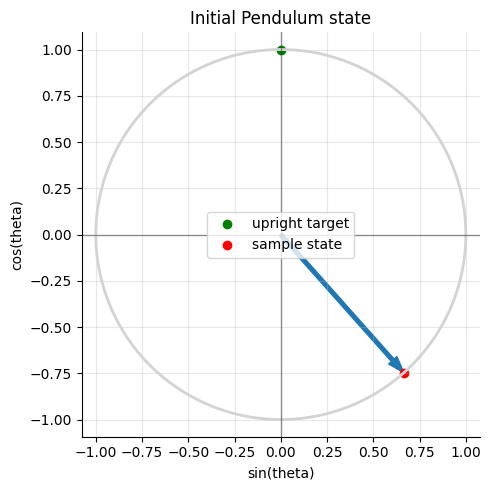

In [5]:
# Step 4.1.4: Visualise the initial Pendulum state
state_plot_path = PLOT_DIR / "pendulum_initial_state_geometry.png"

theta = initial_theta
circle_angles = np.linspace(0, 2 * np.pi, 300)

plt.figure(figsize=(5, 5))
plt.plot(np.sin(circle_angles), np.cos(circle_angles), color="lightgray", linewidth=2)
plt.axhline(0, color="black", linewidth=1, alpha=0.4)
plt.axvline(0, color="black", linewidth=1, alpha=0.4)
plt.arrow(
    0,
    0,
    np.sin(theta),
    np.cos(theta),
    width=0.02,
    length_includes_head=True,
    color="tab:blue",
)
plt.scatter([0], [1], color="green", label="upright target")
plt.scatter([np.sin(theta)], [np.cos(theta)], color="red", label="sample state")
plt.title("Initial Pendulum state")
plt.xlabel("sin(theta)")
plt.ylabel("cos(theta)")
plt.axis("equal")
plt.legend(loc="best")
plt.tight_layout()
plt.savefig(state_plot_path, dpi=150, bbox_inches="tight")
plt.show()


### 4.1.4 Initial State Visual Interpretation

The initial-state visual confirms the table result.

Before seeing the plot, I expected the pendulum to be away from the top position because theta was **2.4141 radians**. The visual supports this: the pendulum is clearly not near the upright target.

This makes the task concrete. The agent is not simply choosing random movement; it must learn a sequence of torque choices that moves the pendulum closer to upright and keeps it there.

Decision: inspect the reward function next, because the reward defines what the DQN will learn to optimise.


## 5. Reward Function and Control Objective

This section checks what the environment reward is actually punishing.

For Pendulum, the best behaviour is upright, slow and not using unnecessary torque. Since the reward is negative, better behaviour means a smaller penalty.


In [6]:
# Step 5.1: Inspect Pendulum reward components using controlled examples
def pendulum_reward_from_values(theta, theta_dot, torque):
    angle_penalty = theta ** 2
    velocity_penalty = 0.1 * (theta_dot ** 2)
    torque_penalty = 0.001 * (torque ** 2)
    reward = -(angle_penalty + velocity_penalty + torque_penalty)

    return {
        "theta": theta,
        "theta_dot": theta_dot,
        "torque": torque,
        "angle_penalty": angle_penalty,
        "velocity_penalty": velocity_penalty,
        "torque_penalty": torque_penalty,
        "reward": reward,
    }


reward_examples = pd.DataFrame([
    {
        "case": "upright and stable",
        **pendulum_reward_from_values(theta=0.0, theta_dot=0.0, torque=0.0),
    },
    {
        "case": "wrong angle only",
        **pendulum_reward_from_values(theta=1.0, theta_dot=0.0, torque=0.0),
    },
    {
        "case": "fast rotation only",
        **pendulum_reward_from_values(theta=0.0, theta_dot=3.0, torque=0.0),
    },
    {
        "case": "high torque only",
        **pendulum_reward_from_values(theta=0.0, theta_dot=0.0, torque=2.0),
    },
    {
        "case": "far from upright sample",
        **pendulum_reward_from_values(theta=initial_theta, theta_dot=float(initial_state[2]), torque=0.0),
    },
])

reward_examples = reward_examples.round(4)
reward_examples_path = TABLE_DIR / "pendulum_reward_component_examples.csv"
reward_examples.to_csv(reward_examples_path, index=False)

display(reward_examples)


,case,theta,theta_dot,torque,angle_penalty,velocity_penalty,torque_penalty,reward
0,upright and stable,0.0000,0.0000,0.0,0.0000,0.0000,0.000,-0.0000
1,wrong angle only,1.0000,0.0000,0.0,1.0000,0.0000,0.000,-1.0000
2,fast rotation only,0.0000,3.0000,0.0,0.0000,0.9000,0.000,-0.9000
3,high torque only,0.0000,0.0000,2.0,0.0000,0.0000,0.004,-0.0040
4,far from upright sample,2.4141,-0.1914,0.0,5.8278,0.0037,0.000,-5.8314


### 5.1 Reward Objective Interpretation

The reward examples show that angle error is the most important penalty.

The ideal upright and stable case gives a reward of **0.0**. A one-radian angle error already gives **-1.0**, and a fast rotation example gives **-0.9**. In contrast, using maximum torque by itself gives only **-0.004**.

This tells me how to interpret later results. If a model improves reward, I should expect it to reduce angle error and angular velocity. Torque still matters, but the reward function mainly rewards staying close to upright.

Decision: use reward as the main score, but always check angle and velocity as supporting evidence.


In [7]:
# Step 5.2: Check whether the reward and epsilon targets are realistic
REWARD_TARGET = 0.0
LECTURER_EPSILON_TARGET = 0.01
CURRENT_EPSILON_END = 0.05
GREEDY_EVALUATION_EPSILON = 0.0

target_feasibility_check = pd.DataFrame([
    {
        "target": "reward = 0",
        "status": "theoretical maximum, not a realistic repeated-evaluation expectation",
        "reason": (
            "Pendulum reaches 0 reward only when angle error, angular velocity and torque penalty "
            "are all exactly 0 at every step."
        ),
    },
    {
        "target": "epsilon = 0.01",
        "status": "achievable as a training setting, but not the setting used in this workflow",
        "reason": (
            "The current experiments keep EPSILON_END at 0.05 for some late-training exploration, "
            "while final evaluation is greedy with epsilon = 0."
        ),
    },
])

target_feasibility_path = TABLE_DIR / "reward_and_epsilon_target_feasibility.csv"
target_feasibility_check.to_csv(target_feasibility_path, index=False)

display(target_feasibility_check)
print("Saved reward and epsilon target feasibility check to:", target_feasibility_path)


,target,status,reason
0,reward = 0,"theoretical maximum, not a realistic repeated-...",Pendulum reaches 0 reward only when angle erro...
1,epsilon = 0.01,"achievable as a training setting, but not the ...",The current experiments keep EPSILON_END at 0....


Saved reward and epsilon target feasibility check to: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_b_outputs\tables\reward_and_epsilon_target_feasibility.csv


### 5.2 Reward 0 and Epsilon 0.01 Target Interpretation

This checkpoint answers the target question directly.

A reward of **0** is the theoretical best reward for Pendulum, but it is not a realistic repeated-evaluation expectation. To get 0 at every timestep, the pendulum would need to be exactly upright, have no angular velocity and use no torque. In the actual environment, episodes start from different states and the DQN only chooses from discretised torque values, so I treat reward closer to 0 as the correct performance direction rather than claiming that perfect 0 reward should be reached.

The epsilon target is different. **Epsilon = 0.01** is achievable because it is only a training exploration setting. I keep **0.05** for the first workflow because it gives the replay memory a little late-stage variation, but I do not want to leave that as an assumption. I revisit **0.01** later in the matched-seed audit so the notebook tests whether the smaller exploration floor actually helps.

Decision: do not claim that reward 0 was achieved. Use reward closer to 0 as the performance direction, and test epsilon **0.01** as a controlled alternative before the final conclusion.


## 6. Non-Learning Baselines

Before training a DQN, I need a reference point.

If a learned policy only performs like random torque or zero torque, then it has not learned useful control. These baselines show what performance looks like before learning.


In [8]:
# Step 6.1: Define non-learning baseline policies
def random_torque_policy(env, state, step):
    return env.action_space.sample()


def zero_torque_policy(env, state, step):
    return np.array([0.0], dtype=np.float32)


baseline_policy_plan = pd.DataFrame([
    {
        "baseline policy": "random torque",
        "comparison purpose": "shows behaviour without learned control",
        "expected limitation": "torque is applied without using the state properly",
    },
    {
        "baseline policy": "zero torque",
        "comparison purpose": "shows behaviour with no control effort",
        "expected limitation": "cannot actively move the pendulum towards upright",
    },
])

baseline_policy_plan_path = TABLE_DIR / "non_learning_baseline_policy_plan.csv"
baseline_policy_plan.to_csv(baseline_policy_plan_path, index=False)

display(baseline_policy_plan)


,baseline policy,comparison purpose,expected limitation
0,random torque,shows behaviour without learned control,torque is applied without using the state prop...
1,zero torque,shows behaviour with no control effort,cannot actively move the pendulum towards upright


### 6.1 Baseline Policy Checkpoint

The two non-learning policies are ready.

Random torque checks behaviour when actions do not properly use the state. Zero torque checks behaviour when the agent applies no active control. I expect both to perform poorly, but for different reasons: random torque wastes effort, while zero torque cannot correct the pendulum.

Decision: evaluate both policies so the first DQN has a clear baseline to beat.


In [9]:
# Step 6.2: Evaluate non-learning baselines on default Pendulum
def run_policy_episode(policy_name, policy_fn, gravity=None, seed=SEED, max_steps=200):
    env = make_pendulum_env(gravity=gravity, seed=seed)
    state = reset_env(env, seed=seed)
    records = []

    for step in range(max_steps):
        action = policy_fn(env, state, step)
        next_state, reward, done, _ = step_env(env, action)

        records.append({
            "policy": policy_name,
            "step": step,
            "theta": angle_from_state(state),
            "theta_dot": float(state[2]),
            "torque": float(action[0]),
            "reward": float(reward),
        })

        state = next_state

        if done:
            break

    env.close()
    return pd.DataFrame(records)


baseline_rollouts = pd.concat([
    run_policy_episode("random torque", random_torque_policy, seed=SEED),
    run_policy_episode("zero torque", zero_torque_policy, seed=SEED),
], ignore_index=True)

baseline_summary = (
    baseline_rollouts
    .groupby("policy")
    .agg(
        steps=("step", "count"),
        total_reward=("reward", "sum"),
        mean_reward=("reward", "mean"),
        reward_std=("reward", "std"),
        mean_abs_angle=("theta", lambda values: np.mean(np.abs(values))),
        mean_abs_angular_velocity=("theta_dot", lambda values: np.mean(np.abs(values))),
        mean_abs_torque=("torque", lambda values: np.mean(np.abs(values))),
    )
    .reset_index()
    .round(4)
)

baseline_rollouts_path = TABLE_DIR / "non_learning_baseline_rollouts.csv"
baseline_summary_path = TABLE_DIR / "non_learning_baseline_summary.csv"

baseline_rollouts.to_csv(baseline_rollouts_path, index=False)
baseline_summary.to_csv(baseline_summary_path, index=False)

display(baseline_summary)


,policy,steps,total_reward,mean_reward,reward_std,mean_abs_angle,mean_abs_angular_velocity,mean_abs_torque
0,random torque,200,-1597.9341,-7.9897,1.2994,2.7719,1.3943,1.036
1,zero torque,200,-1519.2539,-7.5963,1.4851,2.6779,1.7405,0.000


### 6.2 Non-Learning Baseline Evaluation

This cell evaluates the random-torque and zero-torque policies on the default Pendulum environment.

Expected output: both policies should receive strongly negative rewards and large absolute angles. These results define the "before learning" reference level.


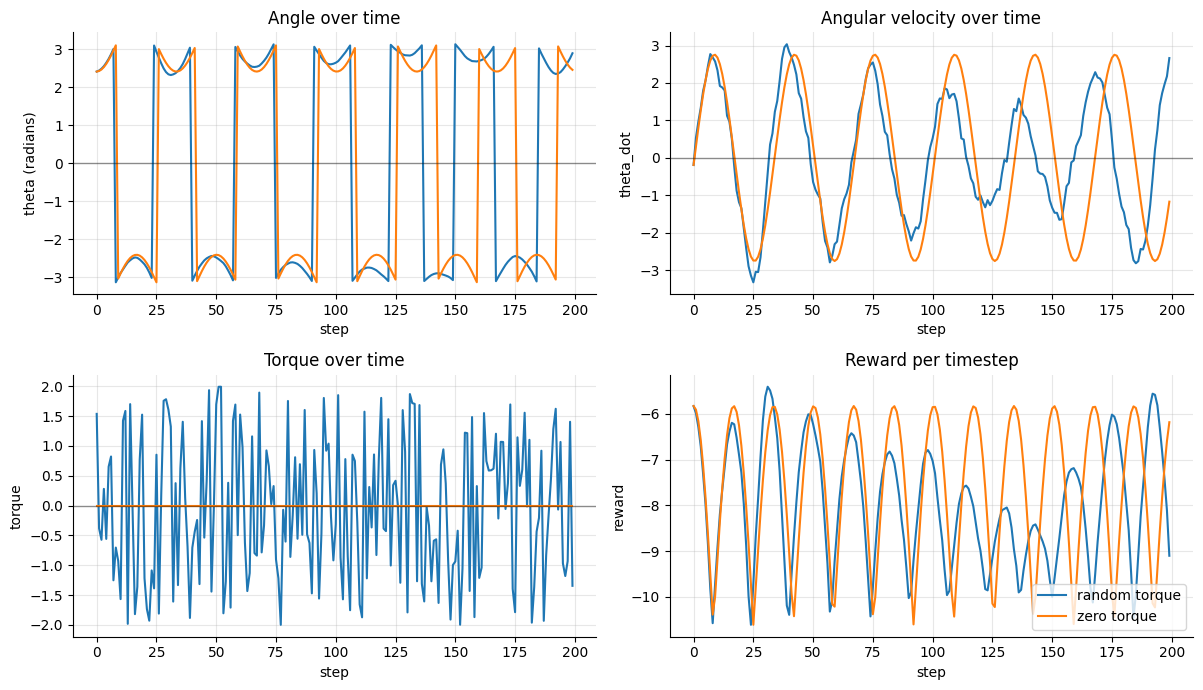

In [10]:
# Step 6.3: Visualise non-learning baseline trajectories
baseline_trajectory_plot_path = PLOT_DIR / "non_learning_baseline_trajectories.png"

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
axes = axes.flatten()

plot_columns = [
    ("theta", "Angle over time", "theta (radians)"),
    ("theta_dot", "Angular velocity over time", "theta_dot"),
    ("torque", "Torque over time", "torque"),
    ("reward", "Reward per timestep", "reward"),
]

for ax, (column, title, ylabel) in zip(axes, plot_columns):
    for policy_name, policy_df in baseline_rollouts.groupby("policy"):
        ax.plot(policy_df["step"], policy_df[column], label=policy_name)

    ax.set_title(title)
    ax.set_xlabel("step")
    ax.set_ylabel(ylabel)
    ax.grid(True, alpha=0.3)

axes[0].axhline(0, color="black", linewidth=1, alpha=0.4)
axes[1].axhline(0, color="black", linewidth=1, alpha=0.4)
axes[2].axhline(0, color="black", linewidth=1, alpha=0.4)
axes[3].legend(loc="best")

plt.tight_layout()
plt.savefig(baseline_trajectory_plot_path, dpi=150, bbox_inches="tight")
plt.show()


### 6.3 Baseline Trajectory Interpretation

The non-learning baselines confirm that the pendulum is not controlled.

Random torque gets a total reward of **-1597.93** with mean absolute angle **2.7719**. Zero torque is also poor, with total reward **-1519.25** and mean absolute angle **2.6779**. The trajectory plot supports this because neither policy settles near `theta = 0`.

This is useful evidence because it gives the DQN a meaningful target. The learned policy should not only have a higher reward, but also a visibly more stable angle trajectory.

Decision: convert the torque action into discrete choices so a DQN can be trained.


## 7. Action Discretisation Plan

The main modelling adaptation is action discretisation.

Pendulum allows any torque from -2 to 2, but DQN needs fixed action indices. I therefore compare possible torque sets before choosing the first baseline.


In [11]:
# Step 7.1: Define candidate torque discretisation sets
ACTION_SET_5 = np.linspace(-2.0, 2.0, 5).astype(np.float32)
ACTION_SET_9 = np.linspace(-2.0, 2.0, 9).astype(np.float32)
ACTION_SET_15 = np.linspace(-2.0, 2.0, 15).astype(np.float32)


def format_action_set(action_values):
    return [round(float(value), 3) for value in action_values]


action_discretisation_plan = pd.DataFrame([
    {
        "action set": "5 actions",
        "torque values": format_action_set(ACTION_SET_5),
        "hypothesis": "simple and fast, but may be too coarse",
    },
    {
        "action set": "9 actions",
        "torque values": format_action_set(ACTION_SET_9),
        "hypothesis": "better torque precision while still manageable",
    },
    {
        "action set": "15 actions",
        "torque values": format_action_set(ACTION_SET_15),
        "hypothesis": "more precise, but harder because more Q-values must be learned",
    },
])

action_plan_path = TABLE_DIR / "action_discretisation_plan.csv"
action_discretisation_plan.to_csv(action_plan_path, index=False)

display(action_discretisation_plan)


,action set,torque values,hypothesis
0,5 actions,"[-2.0, -1.0, 0.0, 1.0, 2.0]","simple and fast, but may be too coarse"
1,9 actions,"[-2.0, -1.5, -1.0, -0.5, 0.0, 0.5, 1.0, 1.5, 2.0]",better torque precision while still manageable
2,15 actions,"[-2.0, -1.714, -1.429, -1.143, -0.857, -0.571,...","more precise, but harder because more Q-values..."


### 7.1 Action Discretisation Plan Interpretation

The discretisation plan sets up the first modelling trade-off.

The 5-action set is simple and fast, but it may be too coarse. The 9-action set adds intermediate torque values such as -0.5 and 0.5, which should allow smoother corrections. The 15-action set gives even more precision, but it also increases the number of Q-values the agent must learn.

I do not start with the largest action set because that would make the first baseline harder to interpret. A simple baseline first makes the improvement evidence clearer.

Decision: start with 5 actions, then test 9 actions as the first improvement.


In [12]:
# Step 7.2: Select the first baseline DQN action set
BASELINE_ACTION_SET_NAME = "5 actions"
ACTION_VALUES = ACTION_SET_5.copy()
NUM_ACTIONS = len(ACTION_VALUES)


def action_index_to_env_action(action_index, action_values=ACTION_VALUES):
    torque = float(action_values[int(action_index)])
    return np.array([torque], dtype=np.float32)


baseline_action_table = pd.DataFrame({
    "action_index": np.arange(NUM_ACTIONS),
    "torque_value": format_action_set(ACTION_VALUES),
})

baseline_action_table_path = TABLE_DIR / "baseline_dqn_action_mapping.csv"
baseline_action_table.to_csv(baseline_action_table_path, index=False)

display(baseline_action_table)


,action_index,torque_value
0,0,-2.0
1,1,-1.0
2,2,0.0
3,3,1.0
4,4,2.0


### 7.2 Baseline Action Mapping Interpretation

The first DQN baseline uses five fixed torque values: **-2.0, -1.0, 0.0, 1.0 and 2.0**.

This gives the agent strong left torque, mild left torque, no torque, mild right torque and strong right torque. It is intentionally simple, which makes it a fair first learned baseline.

Decision: build a Q-network with 3 state inputs and 5 Q-value outputs.


## 8. Baseline DQN Model

This section builds the first learned controller.

The goal is not to create the final model immediately. The goal is to confirm that a DQN with replay memory, epsilon-greedy exploration and a target network can improve over the non-learning baselines.


In [13]:
# Step 8.1: Build the baseline DQN Q-network
STATE_DIM = int(default_env.observation_space.shape[0])
DQN_LEARNING_RATE = 0.001


def build_q_network(input_dim, num_actions, learning_rate=DQN_LEARNING_RATE, name="baseline_dqn_q_network"):
    inputs = tf.keras.Input(shape=(input_dim,), name="state_input")
    x = tf.keras.layers.Dense(128, activation="relu", name="dense_1")(inputs)
    x = tf.keras.layers.Dense(128, activation="relu", name="dense_2")(x)
    q_values = tf.keras.layers.Dense(num_actions, activation="linear", name="q_values")(x)

    model = tf.keras.Model(inputs=inputs, outputs=q_values, name=name)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss=tf.keras.losses.Huber(),
    )
    return model


baseline_q_network = build_q_network(
    input_dim=STATE_DIM,
    num_actions=NUM_ACTIONS,
    learning_rate=DQN_LEARNING_RATE,
)

q_network_summary = pd.DataFrame([
    {
        "item": "state input size",
        "value": STATE_DIM,
        "meaning": "cos(theta), sin(theta) and theta_dot enter the network",
    },
    {
        "item": "number of output Q-values",
        "value": NUM_ACTIONS,
        "meaning": "one Q-value is produced for each discretised torque action",
    },
    {
        "item": "hidden layers",
        "value": "128 -> 128",
        "meaning": "small baseline model before adding more complexity",
    },
    {
        "item": "loss function",
        "value": "Huber loss",
        "meaning": "reduces the effect of large unstable TD errors",
    },
    {
        "item": "trainable parameters",
        "value": baseline_q_network.count_params(),
        "meaning": "model size used for the first DQN baseline",
    },
])

display(q_network_summary)


,item,value,meaning
0,state input size,3,"cos(theta), sin(theta) and theta_dot enter the..."
1,number of output Q-values,5,one Q-value is produced for each discretised t...
2,hidden layers,128 -> 128,small baseline model before adding more comple...
3,loss function,Huber loss,reduces the effect of large unstable TD errors
4,trainable parameters,17669,model size used for the first DQN baseline


### 8.1 Baseline Q-Network Interpretation

The baseline Q-network was built successfully.

The model receives the 3 Pendulum state values and outputs 5 Q-values, one for each torque action. It uses two hidden layers of **128** units and has **17,669 trainable parameters**.

I use **128 -> 128** as the starting network because the state is small, but the control relationship is still nonlinear: angle, angular velocity and torque choice interact over time. A smaller **64 -> 64** network would be faster, but it may underfit the Q-value pattern once the action set becomes finer. A much larger or deeper network would add training cost and make the first DQN harder to interpret. This makes **128 -> 128** a reasonable middle point for the main workflow.

ReLU is used because it is a simple, stable starting activation for dense Q-networks. Huber loss is used because DQN target values can be noisy, and Huber loss is less sensitive to large TD errors than plain squared loss.

Decision: keep this as the first DQN baseline, then use controlled experiments later to test the settings that most directly affect the final policy choice.


In [14]:
# Step 8.2: Define replay memory and epsilon-greedy action selection
REPLAY_MEMORY_SIZE = 50_000
MIN_REPLAY_SIZE = 1_000
BATCH_SIZE = 64
GAMMA = 0.99

EPSILON_START = 1.00
EPSILON_END = 0.05
EPSILON_DECAY_STEPS = 8_000

replay_memory = deque(maxlen=REPLAY_MEMORY_SIZE)


def epsilon_by_step(step):
    progress = min(float(step) / EPSILON_DECAY_STEPS, 1.0)
    return EPSILON_START + progress * (EPSILON_END - EPSILON_START)


def select_epsilon_greedy_action(state, q_network, epsilon, action_values=ACTION_VALUES):
    if np.random.random() < epsilon:
        return int(np.random.randint(len(action_values)))

    state_batch = np.asarray(state, dtype=np.float32).reshape(1, -1)
    q_values = q_network(state_batch, training=False).numpy()[0]
    return int(np.argmax(q_values))


dqn_training_controls = pd.DataFrame([
    {
        "setting": "replay memory size",
        "value": REPLAY_MEMORY_SIZE,
        "reason": "stores past transitions so batches are not based only on the latest episode",
    },
    {
        "setting": "minimum replay size",
        "value": MIN_REPLAY_SIZE,
        "reason": "waits for several episodes of experience before the first gradient update",
    },
    {
        "setting": "batch size",
        "value": BATCH_SIZE,
        "reason": "keeps each update small enough to run repeatedly while still averaging across many transitions",
    },
    {
        "setting": "discount factor",
        "value": GAMMA,
        "reason": "uses 0.99 instead of a short-sighted value such as 0.90 because Pendulum needs sustained future stability",
    },
    {
        "setting": "epsilon schedule",
        "value": f"{EPSILON_START} to {EPSILON_END} over {EPSILON_DECAY_STEPS} steps",
        "reason": "keeps early exploration high, then keeps a small 0.05 exploration chance during late training",
    },
])

display(dqn_training_controls)


,setting,value,reason
0,replay memory size,50000,stores past transitions so batches are not bas...
1,minimum replay size,1000,waits for several episodes of experience befor...
2,batch size,64,keeps each update small enough to run repeated...
3,discount factor,0.99,uses 0.99 instead of a short-sighted value suc...
4,epsilon schedule,1.0 to 0.05 over 8000 steps,"keeps early exploration high, then keeps a sma..."


### 8.2 Replay Memory and Exploration Interpretation

The replay and exploration settings are ready, but these choices need to be justified because they affect how stable DQN training is.

Replay memory stores up to **50,000** transitions, but training only starts after **1,000** transitions are available. This gives the model a small pool of different states before the first update. A much smaller memory would make batches too dependent on the most recent swing, while a much larger one would add storage without clearly helping this short Pendulum task.

The batch size is **64** because it is a moderate update size. Smaller batches would make the updates noisier, while much larger batches would slow down each training step and make the first baseline heavier than needed.

I use **gamma = 0.99** because Pendulum is a continuing control problem inside a 200-step episode. A lower value such as **0.90** would focus too much on immediate reward and may not value staying upright later in the episode. A value even closer to 1, such as **0.999**, would make the target more future-heavy and can make Q-learning less stable. So **0.99** is a balanced choice: it still values future stability strongly without pushing the target too far.

Epsilon starts at **1.0** so the agent explores all torque actions before trusting the untrained Q-network. It decays over **8,000** steps, which is roughly the first 40 full Pendulum episodes. This is slow enough to gather experience, but not so slow that most of training is random.

I keep **EPSILON_END = 0.05** for the first baseline because late exploration can still help the replay memory contain varied corrections. However, I also test **0.01** later under matched training seeds because it is a valid alternative and could improve final exploitation. The final evaluation itself is greedy, so evaluation is judged with epsilon effectively equal to **0**.

Decision: use **gamma = 0.99** and **epsilon end = 0.05** for the first workflow, then check whether epsilon **0.01** is better once the action setup and target-network interval have been audited.


In [15]:
# Step 8.3: Create the target Q-network for DQN stability
TARGET_UPDATE_EVERY_EPISODES = 10

target_q_network = build_q_network(
    input_dim=STATE_DIM,
    num_actions=NUM_ACTIONS,
    learning_rate=DQN_LEARNING_RATE,
    name="baseline_dqn_target_network",
)
target_q_network.set_weights(baseline_q_network.get_weights())


def update_target_network(source_network, target_network):
    target_network.set_weights(source_network.get_weights())


sample_state_batch = np.asarray(initial_state, dtype=np.float32).reshape(1, -1)
online_q_values = baseline_q_network(sample_state_batch, training=False).numpy()[0]
target_q_values = target_q_network(sample_state_batch, training=False).numpy()[0]
max_initial_q_difference = float(np.max(np.abs(online_q_values - target_q_values)))

target_network_check = pd.DataFrame([
    {
        "check": "online Q-network",
        "result": baseline_q_network.name,
        "meaning": "network updated by gradient descent during training",
    },
    {
        "check": "target Q-network",
        "result": target_q_network.name,
        "meaning": "separate network used to calculate more stable TD targets",
    },
    {
        "check": "initial weight copy difference",
        "result": round(max_initial_q_difference, 6),
        "meaning": "0 means both networks start with identical Q-value predictions",
    },
    {
        "check": "target update interval",
        "result": f"every {TARGET_UPDATE_EVERY_EPISODES} episodes",
        "meaning": "keeps targets stable for several episodes before copying new weights",
    },
])

display(target_network_check)


,check,result,meaning
0,online Q-network,baseline_dqn_q_network,network updated by gradient descent during tra...
1,target Q-network,baseline_dqn_target_network,separate network used to calculate more stable...
2,initial weight copy difference,0.0,0 means both networks start with identical Q-v...
3,target update interval,every 10 episodes,keeps targets stable for several episodes befo...


### 8.3 Target Network Interpretation

The target network check passed.

The online and target networks start with identical Q-value predictions, shown by an initial difference of **0.0**. This is expected because the target network is copied from the online network before training.

The first workflow updates the target network every **10 episodes**. This is a middle setting: updating too frequently can make the target chase the online network, while updating too slowly can leave the TD target stale. I start with 10 because it gives the model several episodes of stable targets without freezing the target network for too long.

Decision: use the target network during replay-batch updates, then revisit the update interval in the controlled audit so this choice is not left as only a one-line assumption.


In [16]:
# Step 8.4: Define one replay-batch DQN update
def store_transition(memory, state, action_index, reward, next_state, done):
    memory.append((
        np.asarray(state, dtype=np.float32),
        int(action_index),
        float(reward),
        np.asarray(next_state, dtype=np.float32),
        bool(done),
    ))


def train_dqn_batch(
    q_network,
    target_network,
    memory,
    batch_size=BATCH_SIZE,
    gamma=GAMMA,
):
    if len(memory) < batch_size:
        return None

    minibatch = random.sample(memory, batch_size)

    states = np.asarray([transition[0] for transition in minibatch], dtype=np.float32)
    action_indices = np.asarray([transition[1] for transition in minibatch], dtype=np.int32)
    rewards = np.asarray([transition[2] for transition in minibatch], dtype=np.float32)
    next_states = np.asarray([transition[3] for transition in minibatch], dtype=np.float32)
    dones = np.asarray([transition[4] for transition in minibatch], dtype=np.float32)

    current_q_values = q_network(states, training=False).numpy()
    next_q_values = target_network(next_states, training=False).numpy()
    best_next_q_values = np.max(next_q_values, axis=1)

    target_q_values = current_q_values.copy()
    batch_rows = np.arange(batch_size)
    target_q_values[batch_rows, action_indices] = rewards + (1.0 - dones) * gamma * best_next_q_values

    loss_value = q_network.train_on_batch(states, target_q_values)
    if isinstance(loss_value, (list, tuple)):
        loss_value = loss_value[0]

    return float(loss_value)


dqn_update_plan = pd.DataFrame([
    {
        "training part": "stored transition",
        "implementation": "state, action_index, reward, next_state, done",
        "why it matters": "keeps each control experience in a reusable format",
    },
    {
        "training part": "sampled batch",
        "implementation": f"random sample of {BATCH_SIZE} transitions",
        "why it matters": "breaks the direct dependence on the latest trajectory only",
    },
    {
        "training part": "TD target",
        "implementation": "reward + gamma * max(target Q(next_state))",
        "why it matters": "connects the immediate reward to expected future control value",
    },
    {
        "training part": "terminal handling",
        "implementation": "future value removed when done is True",
        "why it matters": "prevents the model from learning value beyond the end of an episode",
    },
])

display(dqn_update_plan)


,training part,implementation,why it matters
0,stored transition,"state, action_index, reward, next_state, done",keeps each control experience in a reusable fo...
1,sampled batch,random sample of 64 transitions,breaks the direct dependence on the latest tra...
2,TD target,reward + gamma * max(target Q(next_state)),connects the immediate reward to expected futu...
3,terminal handling,future value removed when done is True,prevents the model from learning value beyond ...


### 8.4 Replay-Batch Update Interpretation

The replay-batch update defines the DQN learning step.

Each stored transition contains the state, chosen action index, reward, next state and done flag. A random batch is sampled from memory, and the selected action's Q-value is moved toward the target `reward + gamma * max(target Q(next_state))`.

This is the point where the model learns the expected value of each torque action. Terminal handling is included so the model does not learn future value beyond the end of an episode.

Decision: smoke-test the update before using it in full training.


In [17]:
# Step 8.5: Smoke-test one replay-batch update without changing the baseline model
smoke_memory = deque(maxlen=REPLAY_MEMORY_SIZE)
smoke_env = make_pendulum_env(seed=SEED + 1)
smoke_state = reset_env(smoke_env, seed=SEED + 1)
smoke_rng = np.random.default_rng(SEED + 1)

for smoke_step in range(BATCH_SIZE):
    smoke_action_index = int(smoke_rng.integers(NUM_ACTIONS))
    smoke_action = action_index_to_env_action(smoke_action_index)
    smoke_next_state, smoke_reward, smoke_done, _ = step_env(smoke_env, smoke_action)

    store_transition(
        smoke_memory,
        smoke_state,
        smoke_action_index,
        smoke_reward,
        smoke_next_state,
        smoke_done,
    )

    if smoke_done:
        smoke_state = reset_env(smoke_env, seed=SEED + 100 + smoke_step)
    else:
        smoke_state = smoke_next_state

smoke_env.close()

smoke_q_network = build_q_network(
    input_dim=STATE_DIM,
    num_actions=NUM_ACTIONS,
    learning_rate=DQN_LEARNING_RATE,
    name="smoke_test_q_network",
)
smoke_target_network = build_q_network(
    input_dim=STATE_DIM,
    num_actions=NUM_ACTIONS,
    learning_rate=DQN_LEARNING_RATE,
    name="smoke_test_target_network",
)
smoke_target_network.set_weights(smoke_q_network.get_weights())

probe_state = np.asarray(initial_state, dtype=np.float32).reshape(1, -1)
q_values_before = smoke_q_network(probe_state, training=False).numpy()[0]
smoke_loss = train_dqn_batch(
    smoke_q_network,
    smoke_target_network,
    smoke_memory,
    batch_size=BATCH_SIZE,
    gamma=GAMMA,
)
q_values_after = smoke_q_network(probe_state, training=False).numpy()[0]
max_q_value_change = float(np.max(np.abs(q_values_after - q_values_before)))

smoke_test_summary = pd.DataFrame([
    {
        "check": "temporary replay transitions",
        "result": len(smoke_memory),
        "meaning": "enough transitions were collected for one batch update",
    },
    {
        "check": "batch update loss",
        "result": round(float(smoke_loss), 6),
        "meaning": "finite loss means the update calculation ran successfully",
    },
    {
        "check": "Q-value change after update",
        "result": round(max_q_value_change, 6),
        "meaning": "a non-zero change shows the temporary network weights were updated",
    },
    {
        "check": "baseline model protected",
        "result": "yes",
        "meaning": "the smoke test used separate temporary networks, not the real baseline network",
    },
])

display(smoke_test_summary)


,check,result,meaning
0,temporary replay transitions,64,enough transitions were collected for one batc...
1,batch update loss,0.682701,finite loss means the update calculation ran s...
2,Q-value change after update,0.037137,a non-zero change shows the temporary network ...
3,baseline model protected,yes,the smoke test used separate temporary network...


### 8.5 Replay Update Smoke-Test Interpretation

The smoke test confirms that the replay update works before full training.

The temporary memory collected **64** transitions, enough for one batch update. The update returned a finite loss of **0.682701**, and the Q-values changed by **0.037137** after the update. This shows that the training calculation can actually move the network weights.

The real baseline model was protected because the smoke test used separate temporary networks. This is important because the baseline should start cleanly during real training.

Decision: train or load the 5-action DQN baseline.


## 9. Baseline DQN Training

This section trains the first learned policy and compares it against the non-learning references.

The baseline uses the 5-action torque mapping. I keep the setup simple so later improvements can be judged clearly.


In [18]:
# Step 9.1: Define the baseline DQN training plan
BASELINE_DQN_EPISODES = 100
MAX_STEPS_PER_EPISODE = 200
TRAIN_EVERY_STEPS = 1
BASELINE_DQN_WEIGHTS_PATH = MODEL_DIR / "baseline_dqn_5_actions.weights.h5"
BASELINE_DQN_HISTORY_PATH = TABLE_DIR / "baseline_dqn_5_actions_training_history.csv"

baseline_training_plan = pd.DataFrame([
    {
        "training decision": "model being trained",
        "selected value": "baseline DQN with 5 torque actions",
        "reason": "first learned control baseline after random and zero-torque policies",
    },
    {
        "training decision": "episodes",
        "selected value": BASELINE_DQN_EPISODES,
        "reason": "long enough to observe an initial reward trend without making the first baseline excessive",
    },
    {
        "training decision": "steps per episode",
        "selected value": MAX_STEPS_PER_EPISODE,
        "reason": "matches the Pendulum episode length checked earlier",
    },
    {
        "training decision": "training frequency",
        "selected value": f"every {TRAIN_EVERY_STEPS} environment step",
        "reason": "updates the Q-network regularly once replay memory has enough experience",
    },
    {
        "training decision": "target network update",
        "selected value": f"every {TARGET_UPDATE_EVERY_EPISODES} episodes",
        "reason": "keeps the TD target more stable during training",
    },
    {
        "training decision": "saved weights file",
        "selected value": str(BASELINE_DQN_WEIGHTS_PATH),
        "reason": "allows the notebook to reload the baseline instead of retraining every time",
    },
])

display(baseline_training_plan)


,training decision,selected value,reason
0,model being trained,baseline DQN with 5 torque actions,first learned control baseline after random an...
1,episodes,100,long enough to observe an initial reward trend...
2,steps per episode,200,matches the Pendulum episode length checked ea...
3,training frequency,every 1 environment step,updates the Q-network regularly once replay me...
4,target network update,every 10 episodes,keeps the TD target more stable during training
5,saved weights file,C:\Users\USER\OneDrive - Singapore Polytechnic...,allows the notebook to reload the baseline ins...


### 9.1 Baseline Training Plan Interpretation

The baseline training plan is ready.

The model trains for **100 episodes**, with up to **200 steps** per episode. The target network is updated every **10 episodes**, and the weights are saved as `baseline_dqn_5_actions.weights.h5`.

This plan is intentionally moderate. It is long enough to show whether the DQN learns a trend, but not so long that the first baseline becomes the final model by training time alone.

Decision: use a train-or-load function so the notebook can be rerun without retraining unnecessarily.


In [19]:
# Step 9.2: Define the baseline DQN train/load function
def train_or_load_baseline_dqn(
    q_network,
    target_network,
    weights_path=BASELINE_DQN_WEIGHTS_PATH,
    history_path=BASELINE_DQN_HISTORY_PATH,
    force_retrain=False,
):
    if weights_path.exists() and history_path.exists() and not force_retrain:
        load_model_weights_without_optimizer_warning(q_network, weights_path)
        update_target_network(q_network, target_network)
        history_df = pd.read_csv(history_path)
        return history_df, "loaded"

    replay_memory.clear()
    training_records = []
    global_step = 0

    for episode in range(1, BASELINE_DQN_EPISODES + 1):
        env = make_pendulum_env(seed=SEED + episode)
        state = reset_env(env, seed=SEED + episode)

        episode_reward = 0.0
        episode_losses = []
        random_action_count = 0
        greedy_action_count = 0

        for step in range(MAX_STEPS_PER_EPISODE):
            epsilon = epsilon_by_step(global_step)

            if np.random.random() < epsilon:
                action_index = int(np.random.randint(NUM_ACTIONS))
                random_action_count += 1
            else:
                state_batch = np.asarray(state, dtype=np.float32).reshape(1, -1)
                q_values = q_network(state_batch, training=False).numpy()[0]
                action_index = int(np.argmax(q_values))
                greedy_action_count += 1

            action = action_index_to_env_action(action_index)
            next_state, reward, done, _ = step_env(env, action)
            store_transition(replay_memory, state, action_index, reward, next_state, done)

            if len(replay_memory) >= MIN_REPLAY_SIZE and global_step % TRAIN_EVERY_STEPS == 0:
                loss = train_dqn_batch(q_network, target_network, replay_memory)
                if loss is not None:
                    episode_losses.append(loss)

            episode_reward += float(reward)
            state = next_state
            global_step += 1

            if done:
                break

        env.close()

        if episode % TARGET_UPDATE_EVERY_EPISODES == 0:
            update_target_network(q_network, target_network)

        mean_loss = np.mean(episode_losses) if episode_losses else np.nan
        training_records.append({
            "episode": episode,
            "episode_reward": episode_reward,
            "mean_loss": mean_loss,
            "epsilon_end": epsilon_by_step(global_step),
            "replay_size": len(replay_memory),
            "random_actions": random_action_count,
            "greedy_actions": greedy_action_count,
            "steps": step + 1,
        })

        if episode % 10 == 0:
            print(
                f"Episode {episode:03d} | reward {episode_reward:8.2f} | "
                f"epsilon {epsilon_by_step(global_step):.3f} | replay {len(replay_memory)}"
            )

    history_df = pd.DataFrame(training_records)
    history_df.to_csv(history_path, index=False)
    q_network.save_weights(str(weights_path))
    update_target_network(q_network, target_network)

    return history_df, "trained"


training_loop_checklist = pd.DataFrame([
    {
        "loop feature": "load existing weights",
        "how it is handled": "loads weights and training history when saved files already exist",
    },
    {
        "loop feature": "episode interaction",
        "how it is handled": "collects Pendulum transitions using the 5-action torque mapping",
    },
    {
        "loop feature": "exploration tracking",
        "how it is handled": "records random and greedy action counts per episode",
    },
    {
        "loop feature": "learning evidence",
        "how it is handled": "records episode reward, mean loss, epsilon and replay size",
    },
    {
        "loop feature": "reproducible continuation",
        "how it is handled": "saves the baseline weights and training history after training",
    },
])

display(training_loop_checklist)


,loop feature,how it is handled
0,load existing weights,loads weights and training history when saved ...
1,episode interaction,collects Pendulum transitions using the 5-acti...
2,exploration tracking,records random and greedy action counts per ep...
3,learning evidence,"records episode reward, mean loss, epsilon and..."
4,reproducible continuation,saves the baseline weights and training histor...


### 9.2 Training Function Interpretation

The training function keeps the baseline workflow reproducible.

It loads saved weights and history if they already exist. Otherwise, it trains from scratch, records episode rewards, saves the history and saves the model weights.

This matters because reinforcement-learning training can be noisy and time-consuming. Saving both weights and history lets me evaluate the same learned policy later instead of accidentally changing the result on every run.

Decision: train or load the baseline DQN, then interpret the actual training history.


In [20]:
# Step 9.3: Train or load the baseline DQN
try:
    baseline_dqn_history, baseline_dqn_source = train_or_load_baseline_dqn(
        baseline_q_network,
        target_q_network,
        weights_path=BASELINE_DQN_WEIGHTS_PATH,
        history_path=BASELINE_DQN_HISTORY_PATH,
        force_retrain=False,
    )
except ValueError as error:
    if BASELINE_DQN_WEIGHTS_PATH.exists() or BASELINE_DQN_HISTORY_PATH.exists():
        print("Saved baseline files could not be reused, so I am retraining the baseline DQN.")
        print("Load issue:", error)
        baseline_dqn_history, baseline_dqn_source = train_or_load_baseline_dqn(
            baseline_q_network,
            target_q_network,
            weights_path=BASELINE_DQN_WEIGHTS_PATH,
            history_path=BASELINE_DQN_HISTORY_PATH,
            force_retrain=True,
        )
    else:
        raise

baseline_reward_start = float(baseline_dqn_history["episode_reward"].head(10).mean())
baseline_reward_end = float(baseline_dqn_history["episode_reward"].tail(10).mean())
baseline_best_row = baseline_dqn_history.loc[baseline_dqn_history["episode_reward"].idxmax()]

baseline_training_summary = pd.DataFrame([
    {
        "result check": "training source",
        "value": baseline_dqn_source,
        "meaning": "shows whether this run trained from scratch or loaded saved evidence",
    },
    {
        "result check": "episodes recorded",
        "value": len(baseline_dqn_history),
        "meaning": "confirms the baseline history length",
    },
    {
        "result check": "first 10 episode mean reward",
        "value": round(baseline_reward_start, 2),
        "meaning": "early baseline performance before much learning has happened",
    },
    {
        "result check": "last 10 episode mean reward",
        "value": round(baseline_reward_end, 2),
        "meaning": "later baseline performance after training or loaded learning",
    },
    {
        "result check": "best episode reward",
        "value": round(float(baseline_best_row["episode_reward"]), 2),
        "meaning": f"best observed episode was episode {int(baseline_best_row['episode'])}",
    },
    {
        "result check": "final epsilon",
        "value": round(float(baseline_dqn_history["epsilon_end"].iloc[-1]), 4),
        "meaning": "shows how much exploration remains at the end",
    },
    {
        "result check": "saved history file",
        "value": str(BASELINE_DQN_HISTORY_PATH),
        "meaning": "training evidence saved for later plots and comparison",
    },
])

display(baseline_training_summary)


,result check,value,meaning
0,training source,loaded,shows whether this run trained from scratch or...
1,episodes recorded,100,confirms the baseline history length
2,first 10 episode mean reward,-1184.76,early baseline performance before much learnin...
3,last 10 episode mean reward,-426.85,later baseline performance after training or l...
4,best episode reward,-1.2,best observed episode was episode 80
5,final epsilon,0.05,shows how much exploration remains at the end
6,saved history file,C:\Users\USER\OneDrive - Singapore Polytechnic...,training evidence saved for later plots and co...


### 9.3 Baseline DQN Training Interpretation

The baseline DQN training history was loaded successfully.

The first 10 episode mean reward was **-1184.76**, while the last 10 episode mean improved to **-426.85**. The best episode reached **-1.20** at episode 80, and final epsilon reached **0.05**.

This shows that the 5-action DQN learned useful control compared with early exploration. However, the final part of training is still not smooth, so I should not rely on the best training episode alone.

Decision: use plots and repeated greedy evaluation before deciding whether this baseline is good enough.


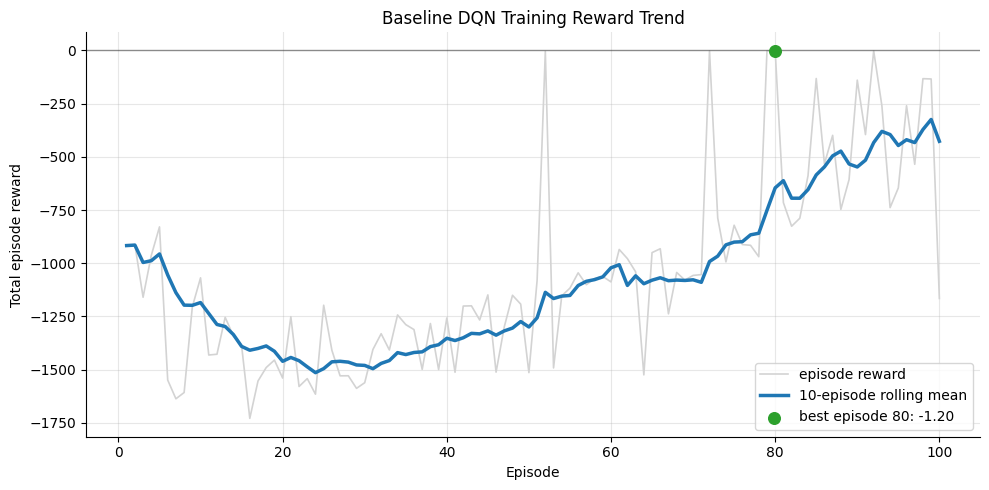

In [21]:
# Step 9.4: Visualise baseline DQN training reward trend
baseline_training_plot_path = PLOT_DIR / "baseline_dqn_training_reward_trend.png"

baseline_plot_df = baseline_dqn_history.copy()
baseline_plot_df["rolling_mean_10"] = baseline_plot_df["episode_reward"].rolling(
    window=10,
    min_periods=1,
).mean()

best_episode_index = baseline_plot_df["episode_reward"].idxmax()
best_episode = int(baseline_plot_df.loc[best_episode_index, "episode"])
best_reward = float(baseline_plot_df.loc[best_episode_index, "episode_reward"])

plt.figure(figsize=(10, 5))
plt.plot(
    baseline_plot_df["episode"],
    baseline_plot_df["episode_reward"],
    color="lightgray",
    linewidth=1.2,
    label="episode reward",
)
plt.plot(
    baseline_plot_df["episode"],
    baseline_plot_df["rolling_mean_10"],
    color="tab:blue",
    linewidth=2.5,
    label="10-episode rolling mean",
)
plt.scatter(
    [best_episode],
    [best_reward],
    color="tab:green",
    s=70,
    zorder=3,
    label=f"best episode {best_episode}: {best_reward:.2f}",
)
plt.axhline(0, color="black", linewidth=1, alpha=0.4)
plt.title("Baseline DQN Training Reward Trend")
plt.xlabel("Episode")
plt.ylabel("Total episode reward")
plt.legend(loc="best")
plt.tight_layout()
plt.savefig(baseline_training_plot_path, dpi=150, bbox_inches="tight")
plt.show()


### 9.4 Baseline Reward Trend Interpretation

The baseline reward plot shows improvement, but not stable mastery.

Before viewing the plot, I expected early episodes to be weak because epsilon starts high and many actions are random. The result matches that expectation: the reward improves from a first-10 mean of **-1184.76** to a last-10 mean of **-426.85**.

The best training episode is much better than the average, which tells me the policy can sometimes control well. But the later rewards still fluctuate, so the baseline is not consistently strong.

Decision: evaluate the trained policy greedily on fixed seeds.


In [22]:
# Step 9.5: Evaluate the trained baseline DQN against non-learning baselines
EVALUATION_EPISODES = 10
EVALUATION_SEEDS = [SEED + 500 + episode for episode in range(EVALUATION_EPISODES)]


def run_evaluation_episode(policy_name, seed, evaluation_episode, q_network=None):
    env = make_pendulum_env(seed=seed)
    state = reset_env(env, seed=seed)
    records = []

    zero_action_index = int(np.argmin(np.abs(ACTION_VALUES - 0.0)))

    for step in range(MAX_STEPS_PER_EPISODE):
        if policy_name == "random torque":
            action_index = np.nan
            action = env.action_space.sample()
        elif policy_name == "zero torque":
            action_index = zero_action_index
            action = action_index_to_env_action(action_index)
        elif policy_name == "baseline DQN (greedy)":
            state_batch = np.asarray(state, dtype=np.float32).reshape(1, -1)
            q_values = q_network(state_batch, training=False).numpy()[0]
            action_index = int(np.argmax(q_values))
            action = action_index_to_env_action(action_index)
        else:
            raise ValueError(f"Unknown policy name: {policy_name}")

        next_state, reward, done, _ = step_env(env, action)

        records.append({
            "policy": policy_name,
            "evaluation_episode": evaluation_episode,
            "seed": seed,
            "step": step,
            "theta": angle_from_state(state),
            "theta_dot": float(state[2]),
            "torque": float(action[0]),
            "action_index": action_index,
            "reward": float(reward),
        })

        state = next_state
        if done:
            break

    env.close()
    return pd.DataFrame(records)


evaluation_rollouts = pd.concat([
    run_evaluation_episode(policy_name, seed, episode_index, baseline_q_network)
    for episode_index, seed in enumerate(EVALUATION_SEEDS, start=1)
    for policy_name in ["random torque", "zero torque", "baseline DQN (greedy)"]
], ignore_index=True)

evaluation_episode_scores = (
    evaluation_rollouts
    .groupby(["policy", "evaluation_episode", "seed"], as_index=False)
    .agg(
        total_reward=("reward", "sum"),
        mean_abs_angle=("theta", lambda values: float(np.mean(np.abs(values)))),
        mean_abs_angular_velocity=("theta_dot", lambda values: float(np.mean(np.abs(values)))),
        mean_abs_torque=("torque", lambda values: float(np.mean(np.abs(values)))),
        steps=("step", "count"),
    )
)

policy_evaluation_summary = (
    evaluation_episode_scores
    .groupby("policy", as_index=False)
    .agg(
        episodes=("evaluation_episode", "count"),
        mean_total_reward=("total_reward", "mean"),
        std_total_reward=("total_reward", "std"),
        best_total_reward=("total_reward", "max"),
        worst_total_reward=("total_reward", "min"),
        mean_abs_angle=("mean_abs_angle", "mean"),
        mean_abs_angular_velocity=("mean_abs_angular_velocity", "mean"),
        mean_abs_torque=("mean_abs_torque", "mean"),
    )
)

policy_order = ["random torque", "zero torque", "baseline DQN (greedy)"]
policy_evaluation_summary["policy"] = pd.Categorical(
    policy_evaluation_summary["policy"],
    categories=policy_order,
    ordered=True,
)
policy_evaluation_summary = policy_evaluation_summary.sort_values("policy").reset_index(drop=True)

evaluation_rollouts_path = TABLE_DIR / "baseline_dqn_policy_evaluation_rollouts.csv"
evaluation_scores_path = TABLE_DIR / "baseline_dqn_policy_evaluation_episode_scores.csv"
evaluation_summary_path = TABLE_DIR / "baseline_dqn_policy_evaluation_summary.csv"

evaluation_rollouts.to_csv(evaluation_rollouts_path, index=False)
evaluation_episode_scores.to_csv(evaluation_scores_path, index=False)
policy_evaluation_summary.to_csv(evaluation_summary_path, index=False)

display(policy_evaluation_summary.round(4))


,policy,episodes,mean_total_reward,std_total_reward,best_total_reward,worst_total_reward,mean_abs_angle,mean_abs_angular_velocity,mean_abs_torque
0,random torque,10,-1385.2668,313.5578,-851.2011,-1749.8713,2.3456,2.2476,1.013
1,zero torque,10,-1404.0986,368.2791,-848.7303,-1889.5836,2.3605,2.2086,0.000
2,baseline DQN (greedy),10,-391.9942,217.2573,-2.6777,-820.7178,0.7925,1.1859,1.107


### 9.5 Baseline Policy Evaluation Interpretation

The repeated evaluation shows that the learned DQN is much better than the non-learning policies.

Random torque and zero torque have mean rewards around **-1385** and **-1404**. The 5-action DQN improves this to **-391.99** and reduces mean absolute angle to **0.7925**.

This confirms that DQN is learning useful state-based control. However, the reward is still negative and the policy still needs to be checked for consistency across seeds.

Decision: inspect reward spread and a representative trajectory before choosing the next improvement.


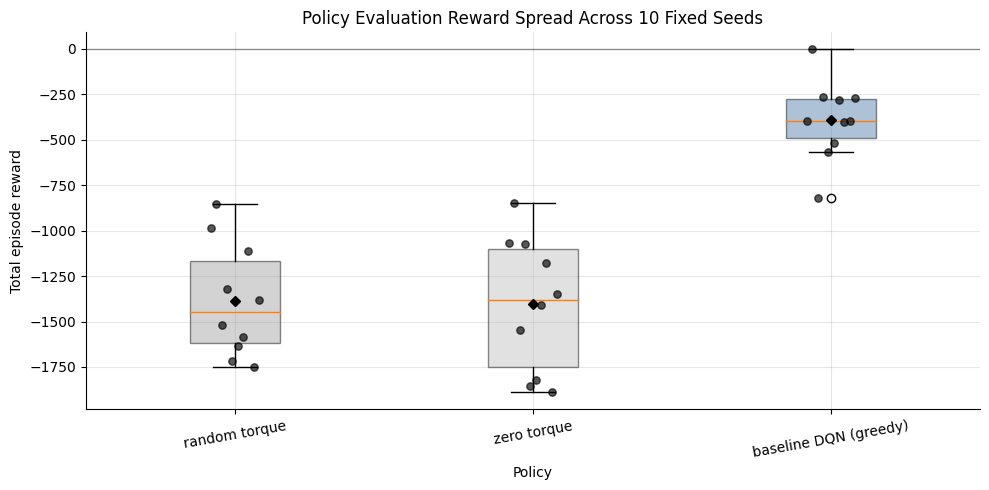

In [23]:
# Step 9.6: Visualise policy evaluation reward spread
policy_evaluation_plot_path = PLOT_DIR / "baseline_dqn_policy_evaluation_reward_spread.png"

plot_policies = ["random torque", "zero torque", "baseline DQN (greedy)"]
plot_values = [
    evaluation_episode_scores.loc[
        evaluation_episode_scores["policy"] == policy,
        "total_reward",
    ].to_numpy()
    for policy in plot_policies
]

fig, ax = plt.subplots(figsize=(10, 5))
box = ax.boxplot(
    plot_values,
    labels=plot_policies,
    patch_artist=True,
    showmeans=True,
    meanprops={
        "marker": "D",
        "markerfacecolor": "black",
        "markeredgecolor": "black",
        "markersize": 5,
    },
)

box_colours = ["#9e9e9e", "#bdbdbd", "#4c78a8"]
for patch, colour in zip(box["boxes"], box_colours):
    patch.set_facecolor(colour)
    patch.set_alpha(0.45)

for position, values in enumerate(plot_values, start=1):
    jitter = np.linspace(-0.08, 0.08, len(values))
    ax.scatter(
        np.full(len(values), position) + jitter,
        values,
        color="black",
        alpha=0.65,
        s=28,
        zorder=3,
    )

ax.axhline(0, color="black", linewidth=1, alpha=0.4)
ax.set_title("Policy Evaluation Reward Spread Across 10 Fixed Seeds")
ax.set_xlabel("Policy")
ax.set_ylabel("Total episode reward")
ax.grid(True, axis="y", alpha=0.3)
plt.xticks(rotation=10)
plt.tight_layout()
plt.savefig(policy_evaluation_plot_path, dpi=150, bbox_inches="tight")
plt.show()


### 9.6 Evaluation Reward Spread Interpretation

The reward-spread plot shows that the baseline DQN improves performance, but still has unstable outcomes.

The mean reward is **-391.99**, but the standard deviation is **217.26**. The best evaluation episode is close to zero at **-2.68**, while the worst is much weaker at **-820.72**.

This changes my interpretation of the baseline. It is clearly better than random or zero torque, but it is not reliable across all starting conditions.

Decision: inspect a representative trajectory, then use the remaining instability to motivate the next improvement.


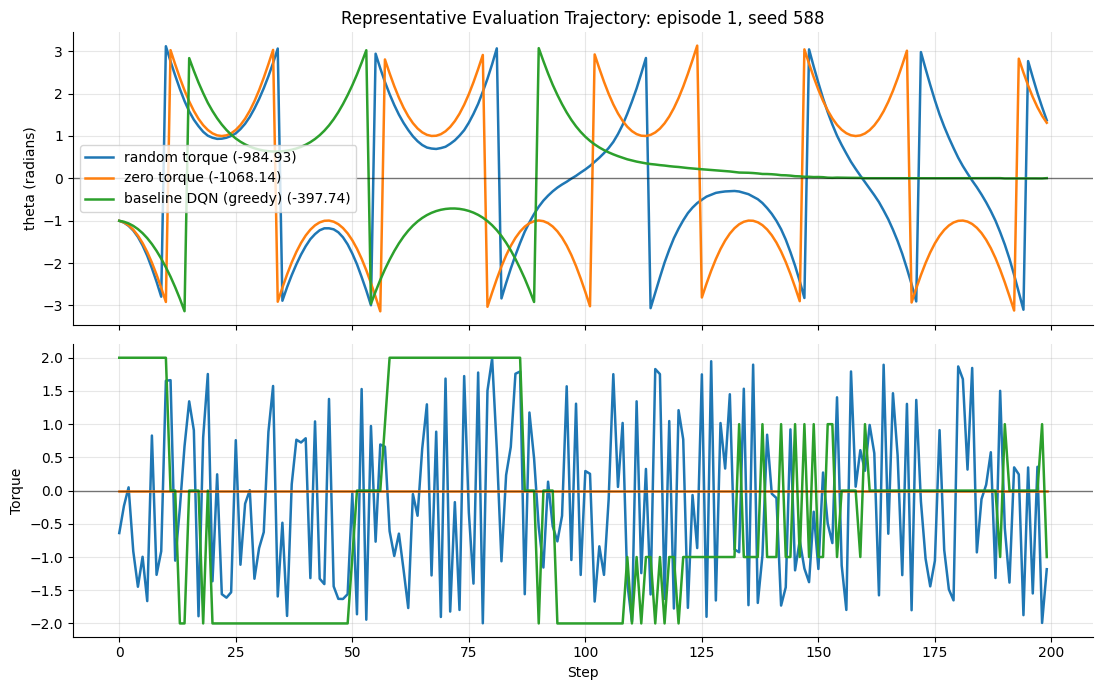

Representative episode chosen because its DQN reward (-397.74) is closest to the DQN median reward (-395.93).


In [24]:
# Step 9.7: Visualise a representative evaluation trajectory
representative_trajectory_plot_path = PLOT_DIR / "baseline_dqn_representative_evaluation_trajectory.png"

dqn_score_rows = evaluation_episode_scores[
    evaluation_episode_scores["policy"] == "baseline DQN (greedy)"
].copy()
dqn_median_reward = float(dqn_score_rows["total_reward"].median())
dqn_score_rows["distance_from_median"] = (
    dqn_score_rows["total_reward"] - dqn_median_reward
).abs()

representative_row = dqn_score_rows.sort_values("distance_from_median").iloc[0]
representative_episode = int(representative_row["evaluation_episode"])
representative_seed = int(representative_row["seed"])

representative_rollouts = evaluation_rollouts[
    evaluation_rollouts["evaluation_episode"] == representative_episode
].copy()

representative_scores = (
    evaluation_episode_scores[
        evaluation_episode_scores["evaluation_episode"] == representative_episode
    ]
    .set_index("policy")["total_reward"]
    .to_dict()
)

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)

for policy_name in policy_order:
    policy_df = representative_rollouts[representative_rollouts["policy"] == policy_name]
    reward_label = representative_scores.get(policy_name, np.nan)
    label = f"{policy_name} ({reward_label:.2f})"

    axes[0].plot(policy_df["step"], policy_df["theta"], linewidth=1.8, label=label)
    axes[1].plot(policy_df["step"], policy_df["torque"], linewidth=1.8, label=label)

axes[0].axhline(0, color="black", linewidth=1, alpha=0.5)
axes[0].set_ylabel("theta (radians)")
axes[0].set_title(
    f"Representative Evaluation Trajectory: episode {representative_episode}, seed {representative_seed}"
)
axes[0].legend(loc="best")

axes[1].axhline(0, color="black", linewidth=1, alpha=0.5)
axes[1].set_ylim(-2.2, 2.2)
axes[1].set_xlabel("Step")
axes[1].set_ylabel("Torque")

plt.tight_layout()
plt.savefig(representative_trajectory_plot_path, dpi=150, bbox_inches="tight")
plt.show()

print(
    "Representative episode chosen because its DQN reward",
    f"({representative_row['total_reward']:.2f}) is closest to the DQN median reward",
    f"({dqn_median_reward:.2f}).",
)


### 9.7 Representative Trajectory Interpretation

The representative trajectory gives behaviour evidence behind the baseline reward.

The plotted episode was chosen because its DQN reward, **-397.74**, is close to the median DQN reward, **-395.93**. That makes it more useful than showing only the best episode.

The trajectory shows meaningful torque use and better control than the non-learning baselines. However, the angle still moves noticeably instead of settling smoothly near zero.

Decision: test a finer 9-action discretisation as Improvement 1.


## 10. Improvement 1: Finer Action Discretisation

The first improvement targets the clearest weakness from the baseline.

The 5-action DQN learned useful control, but the torque choices are coarse. If the agent needs a smaller correction than -1 or +1, the baseline can only choose zero or a larger torque. A 9-action set gives intermediate choices and may support smoother control.


In [25]:
# Step 10.1: Define the first improvement plan
IMPROVED_ACTION_SET_NAME = "9 actions"
IMPROVED_ACTION_VALUES = ACTION_SET_9.copy()
IMPROVED_NUM_ACTIONS = len(IMPROVED_ACTION_VALUES)

IMPROVED_DQN_WEIGHTS_PATH = MODEL_DIR / "improved_dqn_9_actions.weights.h5"
IMPROVED_DQN_HISTORY_PATH = TABLE_DIR / "improved_dqn_9_actions_training_history.csv"


def improved_action_index_to_env_action(action_index, action_values=IMPROVED_ACTION_VALUES):
    torque = float(action_values[int(action_index)])
    return np.array([torque], dtype=np.float32)


baseline_eval_row = policy_evaluation_summary[
    policy_evaluation_summary["policy"] == "baseline DQN (greedy)"
].iloc[0]

improvement_1_plan = pd.DataFrame([
    {
        "workflow question": "What problem did I see?",
        "evidence-based answer": (
            f"The baseline DQN improved to a mean reward of {baseline_eval_row['mean_total_reward']:.2f}, "
            f"but the worst evaluation episode was still {baseline_eval_row['worst_total_reward']:.2f}."
        ),
    },
    {
        "workflow question": "Why might this happen?",
        "evidence-based answer": (
            "The 5-action set only allows coarse torque choices: "
            f"{format_action_set(ACTION_VALUES)}."
        ),
    },
    {
        "workflow question": "How do I plan to fix it?",
        "evidence-based answer": (
            "Train a second DQN with 9 torque choices: "
            f"{format_action_set(IMPROVED_ACTION_VALUES)}."
        ),
    },
    {
        "workflow question": "What must stay the same?",
        "evidence-based answer": (
            "Keep the same environment, reward function, network style, replay update and evaluation seeds."
        ),
    },
    {
        "workflow question": "How will I know if it helped?",
        "evidence-based answer": (
            "Compare mean reward, worst reward, reward spread and representative trajectory against the 5-action baseline."
        ),
    },
])

display(improvement_1_plan)


,workflow question,evidence-based answer
0,What problem did I see?,The baseline DQN improved to a mean reward of ...
1,Why might this happen?,The 5-action set only allows coarse torque cho...
2,How do I plan to fix it?,Train a second DQN with 9 torque choices: [-2....
3,What must stay the same?,"Keep the same environment, reward function, ne..."
4,How will I know if it helped?,"Compare mean reward, worst reward, reward spre..."


### 10.1 Improvement Plan Interpretation

Improvement 1 is based on the baseline limitation.

The observed problem is that the 5-action DQN improved reward but remained inconsistent. A likely reason is coarse torque control. The planned fix is to train a second DQN with 9 torque choices while keeping the environment, network depth, replay logic and evaluation seeds consistent.

This makes the experiment fair. If the result improves, the main changed factor is action precision.

Decision: build a 9-action Q-network using the same core DQN structure.


In [26]:
# Step 10.2: Build the improved 9-action DQN networks
improved_q_network = build_q_network(
    input_dim=STATE_DIM,
    num_actions=IMPROVED_NUM_ACTIONS,
    learning_rate=DQN_LEARNING_RATE,
    name="improved_dqn_9_action_q_network",
)

improved_target_q_network = build_q_network(
    input_dim=STATE_DIM,
    num_actions=IMPROVED_NUM_ACTIONS,
    learning_rate=DQN_LEARNING_RATE,
    name="improved_dqn_9_action_target_network",
)
improved_target_q_network.set_weights(improved_q_network.get_weights())

improved_online_q_values = improved_q_network(sample_state_batch, training=False).numpy()[0]
improved_target_q_values = improved_target_q_network(sample_state_batch, training=False).numpy()[0]
improved_initial_q_difference = float(
    np.max(np.abs(improved_online_q_values - improved_target_q_values))
)

improved_network_check = pd.DataFrame([
    {
        "check": "state input size",
        "result": STATE_DIM,
        "meaning": "same 3 Pendulum state values as the baseline DQN",
    },
    {
        "check": "output Q-values",
        "result": IMPROVED_NUM_ACTIONS,
        "meaning": "one Q-value for each of the 9 torque choices",
    },
    {
        "check": "torque values",
        "result": format_action_set(IMPROVED_ACTION_VALUES),
        "meaning": "finer action choices than the 5-action baseline",
    },
    {
        "check": "trainable parameters",
        "result": improved_q_network.count_params(),
        "meaning": "slightly larger output layer because the model predicts 9 Q-values",
    },
    {
        "check": "extra parameters vs baseline",
        "result": improved_q_network.count_params() - baseline_q_network.count_params(),
        "meaning": "keeps the improvement mainly focused on action precision, not model size",
    },
    {
        "check": "target copy difference",
        "result": round(improved_initial_q_difference, 6),
        "meaning": "0 means the improved online and target networks start identically",
    },
])

display(improved_network_check)


,check,result,meaning
0,state input size,3,same 3 Pendulum state values as the baseline DQN
1,output Q-values,9,one Q-value for each of the 9 torque choices
2,torque values,"[-2.0, -1.5, -1.0, -0.5, 0.0, 0.5, 1.0, 1.5, 2.0]",finer action choices than the 5-action baseline
3,trainable parameters,18185,slightly larger output layer because the model...
4,extra parameters vs baseline,516,keeps the improvement mainly focused on action...
5,target copy difference,0.0,0 means the improved online and target network...


### 10.2 Improved Network Interpretation

The improved DQN network was built with 9 output Q-values.

The input size stays at 3 because the Pendulum state is unchanged. The output changes from 5 Q-values to 9 Q-values, one for each finer torque choice. The model has **18,185** trainable parameters, only slightly more than the 5-action baseline.

This is useful because the comparison stays focused on action discretisation rather than a much larger network.

Decision: train or load the 9-action DQN and compare it directly with the 5-action baseline.


In [27]:
# Step 10.3: Define the improved 9-action DQN training plan
IMPROVED_DQN_EPISODES = BASELINE_DQN_EPISODES
IMPROVED_MAX_STEPS_PER_EPISODE = MAX_STEPS_PER_EPISODE
IMPROVED_TRAIN_EVERY_STEPS = TRAIN_EVERY_STEPS
IMPROVED_TARGET_UPDATE_EVERY_EPISODES = TARGET_UPDATE_EVERY_EPISODES

improved_training_plan = pd.DataFrame([
    {
        "training decision": "model being trained",
        "selected value": "improved DQN with 9 torque actions",
        "reason": "tests whether finer torque choices improve the baseline control behaviour",
    },
    {
        "training decision": "episodes",
        "selected value": IMPROVED_DQN_EPISODES,
        "reason": "kept the same as the 5-action baseline for a fair comparison",
    },
    {
        "training decision": "steps per episode",
        "selected value": IMPROVED_MAX_STEPS_PER_EPISODE,
        "reason": "kept the same Pendulum horizon used in the baseline experiment",
    },
    {
        "training decision": "action set",
        "selected value": format_action_set(IMPROVED_ACTION_VALUES),
        "reason": "adds intermediate torque values while keeping the full -2 to 2 range",
    },
    {
        "training decision": "target network update",
        "selected value": f"every {IMPROVED_TARGET_UPDATE_EVERY_EPISODES} episodes",
        "reason": "kept unchanged so the main experiment difference is action discretisation",
    },
    {
        "training decision": "saved weights file",
        "selected value": str(IMPROVED_DQN_WEIGHTS_PATH),
        "reason": "allows the improved model to be reused without retraining every run",
    },
])

display(improved_training_plan)


,training decision,selected value,reason
0,model being trained,improved DQN with 9 torque actions,tests whether finer torque choices improve the...
1,episodes,100,kept the same as the 5-action baseline for a f...
2,steps per episode,200,kept the same Pendulum horizon used in the bas...
3,action set,"[-2.0, -1.5, -1.0, -0.5, 0.0, 0.5, 1.0, 1.5, 2.0]",adds intermediate torque values while keeping ...
4,target network update,every 10 episodes,kept unchanged so the main experiment differen...
5,saved weights file,C:\Users\USER\OneDrive - Singapore Polytechnic...,allows the improved model to be reused without...


### 10.3 Improved Training Plan Interpretation

The improved training plan keeps the main modelling settings consistent.

The model still trains for **100 episodes**, uses **200 steps** per episode, uses replay memory, uses the same epsilon schedule and updates the target network on the same interval. The main change is the action set.

This keeps the main modelling settings consistent, but because the training-seed paths differ, I treat this as an exploratory comparison and confirm the action-count result later with matched seeds.

Decision: reuse the DQN training workflow with the 9-action mapping, then treat the later matched-seed audit as the stronger action-count evidence.


In [28]:
# Step 10.4: Define the improved 9-action DQN train/load function
improved_replay_memory = deque(maxlen=REPLAY_MEMORY_SIZE)


def train_or_load_improved_dqn(
    q_network,
    target_network,
    weights_path=IMPROVED_DQN_WEIGHTS_PATH,
    history_path=IMPROVED_DQN_HISTORY_PATH,
    force_retrain=False,
):
    if weights_path.exists() and history_path.exists() and not force_retrain:
        load_model_weights_without_optimizer_warning(q_network, weights_path)
        update_target_network(q_network, target_network)
        history_df = pd.read_csv(history_path)
        return history_df, "loaded"

    improved_replay_memory.clear()
    training_records = []
    global_step = 0

    for episode in range(1, IMPROVED_DQN_EPISODES + 1):
        env = make_pendulum_env(seed=SEED + 1000 + episode)
        state = reset_env(env, seed=SEED + 1000 + episode)

        episode_reward = 0.0
        episode_losses = []
        random_action_count = 0
        greedy_action_count = 0

        for step in range(IMPROVED_MAX_STEPS_PER_EPISODE):
            epsilon = epsilon_by_step(global_step)

            if np.random.random() < epsilon:
                action_index = int(np.random.randint(IMPROVED_NUM_ACTIONS))
                random_action_count += 1
            else:
                state_batch = np.asarray(state, dtype=np.float32).reshape(1, -1)
                q_values = q_network(state_batch, training=False).numpy()[0]
                action_index = int(np.argmax(q_values))
                greedy_action_count += 1

            action = improved_action_index_to_env_action(action_index)
            next_state, reward, done, _ = step_env(env, action)
            store_transition(improved_replay_memory, state, action_index, reward, next_state, done)

            if len(improved_replay_memory) >= MIN_REPLAY_SIZE and global_step % IMPROVED_TRAIN_EVERY_STEPS == 0:
                loss = train_dqn_batch(q_network, target_network, improved_replay_memory)
                if loss is not None:
                    episode_losses.append(loss)

            episode_reward += float(reward)
            state = next_state
            global_step += 1

            if done:
                break

        env.close()

        if episode % IMPROVED_TARGET_UPDATE_EVERY_EPISODES == 0:
            update_target_network(q_network, target_network)

        mean_loss = np.mean(episode_losses) if episode_losses else np.nan
        training_records.append({
            "episode": episode,
            "episode_reward": episode_reward,
            "mean_loss": mean_loss,
            "epsilon_end": epsilon_by_step(global_step),
            "replay_size": len(improved_replay_memory),
            "random_actions": random_action_count,
            "greedy_actions": greedy_action_count,
            "steps": step + 1,
        })

        if episode % 10 == 0:
            print(
                f"Episode {episode:03d} | reward {episode_reward:8.2f} | "
                f"epsilon {epsilon_by_step(global_step):.3f} | replay {len(improved_replay_memory)}"
            )

    history_df = pd.DataFrame(training_records)
    history_df.to_csv(history_path, index=False)
    q_network.save_weights(str(weights_path))
    update_target_network(q_network, target_network)

    return history_df, "trained"


improved_training_loop_checklist = pd.DataFrame([
    {
        "loop feature": "separate replay memory",
        "how it is handled": "uses a new memory buffer so the 9-action model does not reuse 5-action transitions",
    },
    {
        "loop feature": "9-action exploration",
        "how it is handled": "random exploration chooses from 9 valid torque action indexes",
    },
    {
        "loop feature": "same training budget",
        "how it is handled": "keeps 100 episodes and 200 steps per episode like the baseline",
    },
    {
        "loop feature": "same evidence recorded",
        "how it is handled": "records reward, loss, epsilon, replay size and action counts",
    },
    {
        "loop feature": "saved improved weights",
        "how it is handled": "saves or reloads the 9-action model separately from the 5-action baseline",
    },
])

display(improved_training_loop_checklist)


,loop feature,how it is handled
0,separate replay memory,uses a new memory buffer so the 9-action model...
1,9-action exploration,random exploration chooses from 9 valid torque...
2,same training budget,keeps 100 episodes and 200 steps per episode l...
3,same evidence recorded,"records reward, loss, epsilon, replay size and..."
4,saved improved weights,saves or reloads the 9-action model separately...


### 10.4 Improved Training Function Interpretation

The improved training function repeats the same train-or-load pattern used for the baseline.

This keeps the comparison reproducible. The 9-action DQN saves both weights and training history, so the model can be evaluated later without retraining.

Decision: run the improved 9-action DQN and compare its training and evaluation evidence.


In [29]:
# Step 10.5: Train or load the improved 9-action DQN
try:
    improved_dqn_history, improved_dqn_source = train_or_load_improved_dqn(
        improved_q_network,
        improved_target_q_network,
        weights_path=IMPROVED_DQN_WEIGHTS_PATH,
        history_path=IMPROVED_DQN_HISTORY_PATH,
        force_retrain=False,
    )
except ValueError as error:
    if IMPROVED_DQN_WEIGHTS_PATH.exists() or IMPROVED_DQN_HISTORY_PATH.exists():
        print("Saved improved files could not be reused, so I am retraining the 9-action DQN.")
        print("Load issue:", error)
        improved_dqn_history, improved_dqn_source = train_or_load_improved_dqn(
            improved_q_network,
            improved_target_q_network,
            weights_path=IMPROVED_DQN_WEIGHTS_PATH,
            history_path=IMPROVED_DQN_HISTORY_PATH,
            force_retrain=True,
        )
    else:
        raise

improved_reward_start = float(improved_dqn_history["episode_reward"].head(10).mean())
improved_reward_end = float(improved_dqn_history["episode_reward"].tail(10).mean())
improved_best_row = improved_dqn_history.loc[improved_dqn_history["episode_reward"].idxmax()]

improved_training_summary = pd.DataFrame([
    {
        "result check": "training source",
        "value": improved_dqn_source,
        "meaning": "shows whether this run trained from scratch or loaded saved evidence",
    },
    {
        "result check": "episodes recorded",
        "value": len(improved_dqn_history),
        "meaning": "confirms the improved history length",
    },
    {
        "result check": "first 10 episode mean reward",
        "value": round(improved_reward_start, 2),
        "meaning": "early improved-model performance before much learning has happened",
    },
    {
        "result check": "last 10 episode mean reward",
        "value": round(improved_reward_end, 2),
        "meaning": "later improved-model performance after training or loaded learning",
    },
    {
        "result check": "best episode reward",
        "value": round(float(improved_best_row["episode_reward"]), 2),
        "meaning": f"best observed episode was episode {int(improved_best_row['episode'])}",
    },
    {
        "result check": "final epsilon",
        "value": round(float(improved_dqn_history["epsilon_end"].iloc[-1]), 4),
        "meaning": "shows how much exploration remains at the end",
    },
    {
        "result check": "saved history file",
        "value": str(IMPROVED_DQN_HISTORY_PATH),
        "meaning": "improved training evidence saved for later plots and comparison",
    },
])

display(improved_training_summary)


,result check,value,meaning
0,training source,loaded,shows whether this run trained from scratch or...
1,episodes recorded,100,confirms the improved history length
2,first 10 episode mean reward,-1236.76,early improved-model performance before much l...
3,last 10 episode mean reward,-364.96,later improved-model performance after trainin...
4,best episode reward,-16.07,best observed episode was episode 49
5,final epsilon,0.05,shows how much exploration remains at the end
6,saved history file,C:\Users\USER\OneDrive - Singapore Polytechnic...,improved training evidence saved for later plo...


### 10.5 Improved DQN Training Interpretation

The 9-action DQN training history is available.

The first 10 episode mean reward was **-1236.76**, while the last 10 episode mean improved to **-364.96**. The best episode was **-16.07** at episode 49, and final epsilon reached **0.05**.

The later training mean is better than the 5-action baseline's last 10 mean of **-426.85**, so the finer action set appears to help. However, the best single episode is not as strong as the 5-action model's best episode, so repeated evaluation is still needed.

Decision: plot the training trend and evaluate the greedy policy on the same fixed seeds.


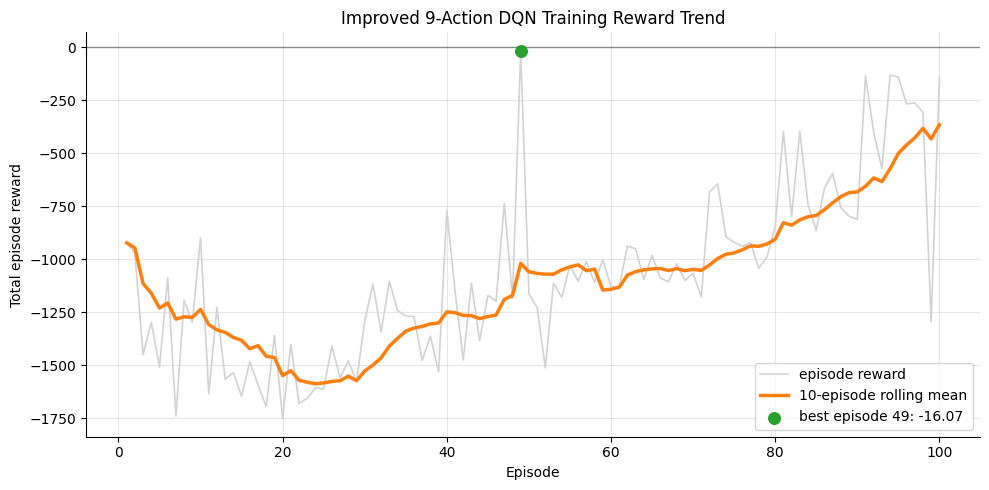

In [30]:
# Step 10.6: Visualise improved 9-action DQN training reward trend
improved_training_plot_path = PLOT_DIR / "improved_dqn_9_action_training_reward_trend.png"

improved_plot_df = improved_dqn_history.copy()
improved_plot_df["rolling_mean_10"] = improved_plot_df["episode_reward"].rolling(
    window=10,
    min_periods=1,
).mean()

improved_best_episode_index = improved_plot_df["episode_reward"].idxmax()
improved_best_episode = int(improved_plot_df.loc[improved_best_episode_index, "episode"])
improved_best_reward = float(improved_plot_df.loc[improved_best_episode_index, "episode_reward"])

plt.figure(figsize=(10, 5))
plt.plot(
    improved_plot_df["episode"],
    improved_plot_df["episode_reward"],
    color="lightgray",
    linewidth=1.2,
    label="episode reward",
)
plt.plot(
    improved_plot_df["episode"],
    improved_plot_df["rolling_mean_10"],
    color="tab:orange",
    linewidth=2.5,
    label="10-episode rolling mean",
)
plt.scatter(
    [improved_best_episode],
    [improved_best_reward],
    color="tab:green",
    s=70,
    zorder=3,
    label=f"best episode {improved_best_episode}: {improved_best_reward:.2f}",
)
plt.axhline(0, color="black", linewidth=1, alpha=0.4)
plt.title("Improved 9-Action DQN Training Reward Trend")
plt.xlabel("Episode")
plt.ylabel("Total episode reward")
plt.legend(loc="best")
plt.tight_layout()
plt.savefig(improved_training_plot_path, dpi=150, bbox_inches="tight")
plt.show()


### 10.6 Improved Training Reward Trend Interpretation

The 9-action training plot shows a better later training trend, but still with reinforcement-learning noise.

Before viewing the result, I expected the 9-action model to need time because it has more possible actions to learn. The training evidence supports that. Early training is weak, but the last 10 episode mean improves to **-364.96**, better than the 5-action baseline's **-426.85**.

This suggests that the finer action set helped, but the curve still fluctuates enough that evaluation must be done on fixed seeds.

Decision: rely on repeated evaluation rather than the training curve alone.


In [31]:
# Step 10.7: Evaluate the improved 9-action DQN on the same fixed seeds
def run_improved_evaluation_episode(policy_name, seed, evaluation_episode, q_network=None):
    env = make_pendulum_env(seed=seed)
    state = reset_env(env, seed=seed)
    records = []

    zero_action_index = int(np.argmin(np.abs(IMPROVED_ACTION_VALUES - 0.0)))

    for step in range(MAX_STEPS_PER_EPISODE):
        if policy_name == "improved DQN 9-action (greedy)":
            state_batch = np.asarray(state, dtype=np.float32).reshape(1, -1)
            q_values = q_network(state_batch, training=False).numpy()[0]
            action_index = int(np.argmax(q_values))
            action = improved_action_index_to_env_action(action_index)
        elif policy_name == "improved zero torque check":
            action_index = zero_action_index
            action = improved_action_index_to_env_action(action_index)
        else:
            raise ValueError(f"Unknown policy name: {policy_name}")

        next_state, reward, done, _ = step_env(env, action)

        records.append({
            "policy": policy_name,
            "evaluation_episode": evaluation_episode,
            "seed": seed,
            "step": step,
            "theta": angle_from_state(state),
            "theta_dot": float(state[2]),
            "torque": float(action[0]),
            "action_index": action_index,
            "reward": float(reward),
        })

        state = next_state
        if done:
            break

    env.close()
    return pd.DataFrame(records)


improved_evaluation_rollouts = pd.concat([
    run_improved_evaluation_episode(
        "improved DQN 9-action (greedy)",
        seed,
        episode_index,
        improved_q_network,
    )
    for episode_index, seed in enumerate(EVALUATION_SEEDS, start=1)
], ignore_index=True)

improved_evaluation_episode_scores = (
    improved_evaluation_rollouts
    .groupby(["policy", "evaluation_episode", "seed"], as_index=False)
    .agg(
        total_reward=("reward", "sum"),
        mean_abs_angle=("theta", lambda values: float(np.mean(np.abs(values)))),
        mean_abs_angular_velocity=("theta_dot", lambda values: float(np.mean(np.abs(values)))),
        mean_abs_torque=("torque", lambda values: float(np.mean(np.abs(values)))),
        steps=("step", "count"),
    )
)

improved_policy_evaluation_summary = (
    improved_evaluation_episode_scores
    .groupby("policy", as_index=False)
    .agg(
        episodes=("evaluation_episode", "count"),
        mean_total_reward=("total_reward", "mean"),
        std_total_reward=("total_reward", "std"),
        best_total_reward=("total_reward", "max"),
        worst_total_reward=("total_reward", "min"),
        mean_abs_angle=("mean_abs_angle", "mean"),
        mean_abs_angular_velocity=("mean_abs_angular_velocity", "mean"),
        mean_abs_torque=("mean_abs_torque", "mean"),
    )
)

improved_evaluation_rollouts_path = TABLE_DIR / "improved_dqn_9_action_policy_evaluation_rollouts.csv"
improved_evaluation_scores_path = TABLE_DIR / "improved_dqn_9_action_policy_evaluation_episode_scores.csv"
improved_evaluation_summary_path = TABLE_DIR / "improved_dqn_9_action_policy_evaluation_summary.csv"

improved_evaluation_rollouts.to_csv(improved_evaluation_rollouts_path, index=False)
improved_evaluation_episode_scores.to_csv(improved_evaluation_scores_path, index=False)
improved_policy_evaluation_summary.to_csv(improved_evaluation_summary_path, index=False)

display(improved_policy_evaluation_summary.round(4))


,policy,episodes,mean_total_reward,std_total_reward,best_total_reward,worst_total_reward,mean_abs_angle,mean_abs_angular_velocity,mean_abs_torque
0,improved DQN 9-action (greedy),10,-295.7043,173.5152,-5.2222,-529.7628,0.642,0.8602,1.0035


### 10.7 Improved Policy Evaluation Interpretation

The 9-action DQN improves the repeated evaluation result.

Mean reward improves from **-391.99** to **-295.70**. Reward spread decreases from **217.26** to **173.52**, and the worst episode improves from **-820.72** to **-529.76**. The mean absolute angle also improves from **0.7925** to **0.6420**.

This is stronger evidence than the training curve because it uses the same fixed evaluation seeds. The improvement affects both reward and behaviour metrics.

Decision: compare the two models directly before accepting the action-discretisation improvement.


In [32]:
# Step 10.8: Compare 5-action and 9-action DQN results directly
baseline_default_row = policy_evaluation_summary[
    policy_evaluation_summary["policy"].astype(str) == "baseline DQN (greedy)"
].iloc[0]

improved_default_row = improved_policy_evaluation_summary[
    improved_policy_evaluation_summary["policy"].astype(str) == "improved DQN 9-action (greedy)"
].iloc[0]

baseline_final_10_mean = float(baseline_dqn_history["episode_reward"].tail(10).mean())
improved_final_10_mean = float(improved_dqn_history["episode_reward"].tail(10).mean())

default_dqn_comparison = pd.DataFrame([
    {
        "metric": "mean evaluation reward",
        "5-action DQN": float(baseline_default_row["mean_total_reward"]),
        "9-action DQN": float(improved_default_row["mean_total_reward"]),
        "change": float(improved_default_row["mean_total_reward"] - baseline_default_row["mean_total_reward"]),
        "better result": "9-action",
    },
    {
        "metric": "reward standard deviation",
        "5-action DQN": float(baseline_default_row["std_total_reward"]),
        "9-action DQN": float(improved_default_row["std_total_reward"]),
        "change": float(improved_default_row["std_total_reward"] - baseline_default_row["std_total_reward"]),
        "better result": "9-action",
    },
    {
        "metric": "worst evaluation reward",
        "5-action DQN": float(baseline_default_row["worst_total_reward"]),
        "9-action DQN": float(improved_default_row["worst_total_reward"]),
        "change": float(improved_default_row["worst_total_reward"] - baseline_default_row["worst_total_reward"]),
        "better result": "9-action",
    },
    {
        "metric": "best evaluation reward",
        "5-action DQN": float(baseline_default_row["best_total_reward"]),
        "9-action DQN": float(improved_default_row["best_total_reward"]),
        "change": float(improved_default_row["best_total_reward"] - baseline_default_row["best_total_reward"]),
        "better result": "5-action",
    },
    {
        "metric": "mean absolute angle",
        "5-action DQN": float(baseline_default_row["mean_abs_angle"]),
        "9-action DQN": float(improved_default_row["mean_abs_angle"]),
        "change": float(improved_default_row["mean_abs_angle"] - baseline_default_row["mean_abs_angle"]),
        "better result": "9-action",
    },
    {
        "metric": "mean absolute angular velocity",
        "5-action DQN": float(baseline_default_row["mean_abs_angular_velocity"]),
        "9-action DQN": float(improved_default_row["mean_abs_angular_velocity"]),
        "change": float(improved_default_row["mean_abs_angular_velocity"] - baseline_default_row["mean_abs_angular_velocity"]),
        "better result": "9-action",
    },
    {
        "metric": "mean absolute torque",
        "5-action DQN": float(baseline_default_row["mean_abs_torque"]),
        "9-action DQN": float(improved_default_row["mean_abs_torque"]),
        "change": float(improved_default_row["mean_abs_torque"] - baseline_default_row["mean_abs_torque"]),
        "better result": "9-action",
    },
    {
        "metric": "final 10 training mean reward",
        "5-action DQN": baseline_final_10_mean,
        "9-action DQN": improved_final_10_mean,
        "change": improved_final_10_mean - baseline_final_10_mean,
        "better result": "9-action",
    },
])

default_dqn_comparison_path = TABLE_DIR / "default_gravity_5_action_vs_9_action_dqn_comparison.csv"
default_dqn_comparison.to_csv(default_dqn_comparison_path, index=False)

display(default_dqn_comparison.round(4))


,metric,5-action DQN,9-action DQN,change,better result
0,mean evaluation reward,-391.9942,-295.7043,96.2899,9-action
1,reward standard deviation,217.2573,173.5152,-43.7421,9-action
2,worst evaluation reward,-820.7178,-529.7628,290.9550,9-action
3,best evaluation reward,-2.6777,-5.2222,-2.5445,5-action
4,mean absolute angle,0.7925,0.6420,-0.1505,9-action
5,mean absolute angular velocity,1.1859,0.8602,-0.3256,9-action
6,mean absolute torque,1.1070,1.0035,-0.1035,9-action
7,final 10 training mean reward,-426.8523,-364.9575,61.8948,9-action


### 10.8 Direct Improvement Comparison Interpretation

The direct comparison supports accepting the 9-action discretisation.

The most important improvement is the mean evaluation reward, which improves by **96.29** points. The worst episode improves by **290.96**, which means the 9-action model reduces severe failure cases.

There is one nuance: the 5-action model has a slightly better best episode. I do not use that as the main decision because one best episode does not prove consistency. The 9-action model is better on the mean, spread, worst case, angle and angular velocity.

Decision: accept the 9-action action set, but continue tuning because rewards still vary across seeds.


In [33]:
# Step 10.9: Record the Improvement 1 decision
SELECTED_ACTION_SET_NAME = IMPROVED_ACTION_SET_NAME
SELECTED_ACTION_VALUES = IMPROVED_ACTION_VALUES.copy()
SELECTED_NUM_ACTIONS = IMPROVED_NUM_ACTIONS
SELECTED_DQN_WEIGHTS_PATH = IMPROVED_DQN_WEIGHTS_PATH
SELECTED_DQN_HISTORY_PATH = IMPROVED_DQN_HISTORY_PATH
SELECTED_DEFAULT_EVALUATION_ROLLOUTS_PATH = improved_evaluation_rollouts_path
SELECTED_DEFAULT_EVALUATION_SCORES_PATH = improved_evaluation_scores_path
SELECTED_DEFAULT_EVALUATION_SUMMARY_PATH = improved_evaluation_summary_path
SELECTED_DQN_LEARNING_RATE = DQN_LEARNING_RATE
SELECTED_TUNING_SLUG = "standard_lr_001"
SELECTED_DEFAULT_DQN_LABEL = "9-action DQN, standard learning rate"

improvement_1_decision = pd.DataFrame([
    {
        "decision area": "selected default-gravity setup",
        "decision": "keep 9-action DQN for now",
        "evidence": "better mean reward, lower reward spread, better worst case and better behaviour metrics",
    },
    {
        "decision area": "change accepted",
        "decision": "5 actions -> 9 actions",
        "evidence": "mean reward improved by 96.29 and worst reward improved by 290.96",
    },
    {
        "decision area": "main limitation",
        "decision": "still not perfect",
        "evidence": "evaluation rewards still vary across seeds, so the selected setup needs one more tuning check",
    },
    {
        "decision area": "next workflow step",
        "decision": "test a lower learning rate",
        "evidence": "action discretisation helped, so I next test whether smaller Q-value updates improve stability",
    },
])

improvement_1_decision_path = TABLE_DIR / "improvement_1_action_discretisation_decision.csv"
improvement_1_decision.to_csv(improvement_1_decision_path, index=False)

display(improvement_1_decision)


,decision area,decision,evidence
0,selected default-gravity setup,keep 9-action DQN for now,"better mean reward, lower reward spread, bette..."
1,change accepted,5 actions -> 9 actions,mean reward improved by 96.29 and worst reward...
2,main limitation,still not perfect,"evaluation rewards still vary across seeds, so..."
3,next workflow step,test a lower learning rate,"action discretisation helped, so I next test w..."


### 10.9 Improvement 1 Decision Interpretation

The 9-action improvement is accepted as the first action-discretisation improvement.

Changing from 5 actions to 9 actions improves the mean reward from **-391.99** to **-295.70** and improves the worst reward from **-820.72** to **-529.76**. This directly addresses the earlier concern that the 5-action torque choices were too coarse.

However, this does not fully close the action-discretisation question yet. Since 9 actions helped, it is reasonable to check whether the 15-action candidate from Section 7 gives any further benefit.

Decision: accept 9 actions as an improvement over 5 actions, then test 15 actions before moving to learning-rate tuning.

### 10.10 15-Action Follow-Up Plan

The 9-action model improved the 5-action baseline, so the next question is whether even finer torque control helps further.

This is a useful follow-up because Section 7 introduced the 15-action candidate as a possible option. Instead of leaving it as a future idea, I test it directly on default gravity before moving to learning-rate tuning.

The risk is that 15 actions may not automatically improve the result. It gives the agent more precise torque choices, but it also increases the number of Q-values the network must estimate.

Decision: train a 15-action DQN with the same network style, training budget and evaluation seeds as the 9-action model.

In [34]:
# Step 10.10: Define the 15-action follow-up experiment
FIFTEEN_ACTION_SET_NAME = "15 actions"
FIFTEEN_ACTION_VALUES = ACTION_SET_15.copy()
FIFTEEN_NUM_ACTIONS = len(FIFTEEN_ACTION_VALUES)
FIFTEEN_ACTION_FILE_TAG = "15_action"

FIFTEEN_ACTION_DQN_WEIGHTS_PATH = MODEL_DIR / "dqn_15_actions_standard_lr.weights.h5"
FIFTEEN_ACTION_DQN_HISTORY_PATH = TABLE_DIR / "dqn_15_actions_standard_lr_training_history.csv"
FIFTEEN_ACTION_EVALUATION_ROLLOUTS_PATH = TABLE_DIR / "dqn_15_action_policy_evaluation_rollouts.csv"
FIFTEEN_ACTION_EVALUATION_SCORES_PATH = TABLE_DIR / "dqn_15_action_policy_evaluation_episode_scores.csv"
FIFTEEN_ACTION_EVALUATION_SUMMARY_PATH = TABLE_DIR / "dqn_15_action_policy_evaluation_summary.csv"


def action_values_to_env_action(action_index, action_values):
    torque = float(action_values[int(action_index)])
    return np.array([torque], dtype=np.float32)


def fifteen_action_index_to_env_action(action_index, action_values=FIFTEEN_ACTION_VALUES):
    return action_values_to_env_action(action_index, action_values)


fifteen_action_followup_plan = pd.DataFrame([
    {
        "workflow question": "Why test 15 actions?",
        "evidence-based answer": "9 actions helped, so I test whether finer torque control helps further.",
    },
    {
        "workflow question": "What changes?",
        "evidence-based answer": f"The action set changes to {format_action_set(FIFTEEN_ACTION_VALUES)}.",
    },
    {
        "workflow question": "What stays the same?",
        "evidence-based answer": "Default gravity, network style, learning rate, training length and evaluation seeds.",
    },
    {
        "workflow question": "What could go wrong?",
        "evidence-based answer": "The network must estimate 15 Q-values, so learning may become slower or less stable.",
    },
    {
        "workflow question": "How will I decide?",
        "evidence-based answer": "Compare 5, 9 and 15 actions using mean reward, spread, worst reward and angle behaviour.",
    },
])

fifteen_action_followup_plan_path = TABLE_DIR / "fifteen_action_followup_plan.csv"
fifteen_action_followup_plan.to_csv(fifteen_action_followup_plan_path, index=False)

display(fifteen_action_followup_plan)
print("Saved 15-action follow-up plan to:", fifteen_action_followup_plan_path)


,workflow question,evidence-based answer
0,Why test 15 actions?,"9 actions helped, so I test whether finer torq..."
1,What changes?,"The action set changes to [-2.0, -1.714, -1.42..."
2,What stays the same?,"Default gravity, network style, learning rate,..."
3,What could go wrong?,"The network must estimate 15 Q-values, so lear..."
4,How will I decide?,"Compare 5, 9 and 15 actions using mean reward,..."


Saved 15-action follow-up plan to: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_b_outputs\tables\fifteen_action_followup_plan.csv


### 10.11 15-Action Experiment Setup Interpretation

This setup is a useful 15-action follow-up, but it is only partially controlled.

The intended modelling change is action discretisation. The state input, hidden-layer structure, learning rate, replay memory, target network logic, episode count and evaluation seeds are kept aligned with the 9-action experiment. However, the training seed path is different, so I should treat this as an exploratory comparison rather than final proof.

This still matters because it answers a practical workflow question: whether increasing torque precision from 9 to 15 actions looks promising enough to investigate further.

Decision: train or load the 15-action DQN and evaluate it with the same repeated evaluation method, then later recheck action count properly using matched training seeds.


In [35]:
# Step 10.11: Train or load and evaluate the 15-action DQN
tf.random.set_seed(SEED + 1500)
np.random.seed(SEED + 1500)
random.seed(SEED + 1500)

fifteen_action_q_network = build_q_network(
    input_dim=STATE_DIM,
    num_actions=FIFTEEN_NUM_ACTIONS,
    learning_rate=DQN_LEARNING_RATE,
    name="dqn_15_action_q_network",
)

fifteen_action_target_q_network = build_q_network(
    input_dim=STATE_DIM,
    num_actions=FIFTEEN_NUM_ACTIONS,
    learning_rate=DQN_LEARNING_RATE,
    name="dqn_15_action_target_network",
)
fifteen_action_target_q_network.set_weights(fifteen_action_q_network.get_weights())


def train_or_load_default_gravity_action_dqn(
    action_set_name,
    action_values,
    q_network,
    target_network,
    weights_path,
    history_path,
    seed_offset,
    force_retrain=False,
):
    if weights_path.exists() and history_path.exists() and not force_retrain:
        try:
            load_model_weights_without_optimizer_warning(q_network, weights_path)
            update_target_network(q_network, target_network)
            history_df = pd.read_csv(history_path)
            return history_df, "loaded"
        except ValueError as error:
            print(f"Saved {action_set_name} files could not be reused, so I am retraining this DQN.")
            print("Load issue:", error)

    local_replay_memory = deque(maxlen=REPLAY_MEMORY_SIZE)
    training_records = []
    global_step = 0
    num_actions = len(action_values)

    for episode in range(1, IMPROVED_DQN_EPISODES + 1):
        episode_seed = SEED + seed_offset + episode
        env = make_pendulum_env(seed=episode_seed)
        state = reset_env(env, seed=episode_seed)

        episode_reward = 0.0
        episode_losses = []
        random_action_count = 0
        greedy_action_count = 0

        for step in range(IMPROVED_MAX_STEPS_PER_EPISODE):
            epsilon = epsilon_by_step(global_step)

            if np.random.random() < epsilon:
                action_index = int(np.random.randint(num_actions))
                random_action_count += 1
            else:
                state_batch = np.asarray(state, dtype=np.float32).reshape(1, -1)
                q_values = q_network(state_batch, training=False).numpy()[0]
                action_index = int(np.argmax(q_values))
                greedy_action_count += 1

            action = action_values_to_env_action(action_index, action_values)
            next_state, reward, done, _ = step_env(env, action)
            store_transition(local_replay_memory, state, action_index, reward, next_state, done)

            if len(local_replay_memory) >= MIN_REPLAY_SIZE and global_step % IMPROVED_TRAIN_EVERY_STEPS == 0:
                loss = train_dqn_batch(q_network, target_network, local_replay_memory)
                if loss is not None:
                    episode_losses.append(loss)

            episode_reward += float(reward)
            state = next_state
            global_step += 1

            if done:
                break

        env.close()

        if episode % IMPROVED_TARGET_UPDATE_EVERY_EPISODES == 0:
            update_target_network(q_network, target_network)

        training_records.append({
            "action_set": action_set_name,
            "episode": episode,
            "episode_reward": episode_reward,
            "mean_loss": np.mean(episode_losses) if episode_losses else np.nan,
            "epsilon_end": epsilon_by_step(global_step),
            "replay_size": len(local_replay_memory),
            "random_actions": random_action_count,
            "greedy_actions": greedy_action_count,
            "steps": step + 1,
        })

        if episode % 10 == 0:
            print(
                f"{action_set_name} | Episode {episode:03d} | reward {episode_reward:8.2f} | "
                f"epsilon {epsilon_by_step(global_step):.3f} | replay {len(local_replay_memory)}"
            )

    history_df = pd.DataFrame(training_records)
    history_df.to_csv(history_path, index=False)
    q_network.save_weights(str(weights_path))
    update_target_network(q_network, target_network)

    return history_df, "trained"


def evaluate_default_gravity_action_dqn(
    policy_name,
    action_values,
    q_network,
    evaluation_seeds=EVALUATION_SEEDS,
):
    records = []

    for evaluation_episode, seed in enumerate(evaluation_seeds, start=1):
        env = make_pendulum_env(seed=seed)
        state = reset_env(env, seed=seed)

        for step in range(MAX_STEPS_PER_EPISODE):
            state_batch = np.asarray(state, dtype=np.float32).reshape(1, -1)
            q_values = q_network(state_batch, training=False).numpy()[0]
            action_index = int(np.argmax(q_values))
            action = action_values_to_env_action(action_index, action_values)
            next_state, reward, done, _ = step_env(env, action)

            records.append({
                "policy": policy_name,
                "evaluation_episode": evaluation_episode,
                "seed": seed,
                "step": step,
                "theta": angle_from_state(state),
                "theta_dot": float(state[2]),
                "torque": float(action[0]),
                "action_index": action_index,
                "reward": float(reward),
            })

            state = next_state
            if done:
                break

        env.close()

    rollout_df = pd.DataFrame(records)
    score_df = (
        rollout_df
        .groupby(["policy", "evaluation_episode", "seed"], as_index=False)
        .agg(
            total_reward=("reward", "sum"),
            mean_abs_angle=("theta", lambda values: float(np.mean(np.abs(values)))),
            mean_abs_angular_velocity=("theta_dot", lambda values: float(np.mean(np.abs(values)))),
            mean_abs_torque=("torque", lambda values: float(np.mean(np.abs(values)))),
            steps=("step", "count"),
        )
    )
    summary_df = (
        score_df
        .groupby("policy", as_index=False)
        .agg(
            episodes=("evaluation_episode", "count"),
            mean_total_reward=("total_reward", "mean"),
            std_total_reward=("total_reward", "std"),
            best_total_reward=("total_reward", "max"),
            worst_total_reward=("total_reward", "min"),
            mean_abs_angle=("mean_abs_angle", "mean"),
            mean_abs_angular_velocity=("mean_abs_angular_velocity", "mean"),
            mean_abs_torque=("mean_abs_torque", "mean"),
        )
    )

    return rollout_df, score_df, summary_df


fifteen_action_dqn_history, fifteen_action_dqn_source = train_or_load_default_gravity_action_dqn(
    action_set_name=FIFTEEN_ACTION_SET_NAME,
    action_values=FIFTEEN_ACTION_VALUES,
    q_network=fifteen_action_q_network,
    target_network=fifteen_action_target_q_network,
    weights_path=FIFTEEN_ACTION_DQN_WEIGHTS_PATH,
    history_path=FIFTEEN_ACTION_DQN_HISTORY_PATH,
    seed_offset=1500,
    force_retrain=False,
)

fifteen_action_evaluation_rollouts, fifteen_action_evaluation_episode_scores, fifteen_action_policy_evaluation_summary = (
    evaluate_default_gravity_action_dqn(
        policy_name="15-action DQN (greedy)",
        action_values=FIFTEEN_ACTION_VALUES,
        q_network=fifteen_action_q_network,
    )
)

fifteen_action_evaluation_rollouts.to_csv(FIFTEEN_ACTION_EVALUATION_ROLLOUTS_PATH, index=False)
fifteen_action_evaluation_episode_scores.to_csv(FIFTEEN_ACTION_EVALUATION_SCORES_PATH, index=False)
fifteen_action_policy_evaluation_summary.to_csv(FIFTEEN_ACTION_EVALUATION_SUMMARY_PATH, index=False)

fifteen_action_training_summary = pd.DataFrame([
    {
        "result check": "training source",
        "value": fifteen_action_dqn_source,
        "meaning": "shows whether the 15-action model trained or loaded",
    },
    {
        "result check": "episodes recorded",
        "value": len(fifteen_action_dqn_history),
        "meaning": "confirms the training history length",
    },
    {
        "result check": "action count",
        "value": FIFTEEN_NUM_ACTIONS,
        "meaning": "more Q-values than the 5-action and 9-action models",
    },
    {
        "result check": "first 10 episode mean reward",
        "value": round(float(fifteen_action_dqn_history["episode_reward"].head(10).mean()), 2),
        "meaning": "early 15-action training behaviour",
    },
    {
        "result check": "last 10 episode mean reward",
        "value": round(float(fifteen_action_dqn_history["episode_reward"].tail(10).mean()), 2),
        "meaning": "late 15-action training behaviour",
    },
    {
        "result check": "mean evaluation reward",
        "value": round(float(fifteen_action_policy_evaluation_summary.loc[0, "mean_total_reward"]), 2),
        "meaning": "greedy evaluation across the same fixed seeds",
    },
])

display(fifteen_action_training_summary)
display(fifteen_action_policy_evaluation_summary.round(4))


,result check,value,meaning
0,training source,loaded,shows whether the 15-action model trained or l...
1,episodes recorded,100,confirms the training history length
2,action count,15,more Q-values than the 5-action and 9-action m...
3,first 10 episode mean reward,-1117.11,early 15-action training behaviour
4,last 10 episode mean reward,-290.48,late 15-action training behaviour
5,mean evaluation reward,-293.82,greedy evaluation across the same fixed seeds


,policy,episodes,mean_total_reward,std_total_reward,best_total_reward,worst_total_reward,mean_abs_angle,mean_abs_angular_velocity,mean_abs_torque
0,15-action DQN (greedy),10,-293.8196,150.3234,-3.1791,-525.8836,0.5876,0.9112,1.3956


### 10.12 15-Action Result Interpretation

The 15-action DQN gives a small improvement over the 9-action DQN.

The 9-action model had a mean evaluation reward of **-295.70**, reward standard deviation **173.52** and mean absolute angle **0.6420**. The 15-action model improves this slightly to mean reward **-293.82**, reward standard deviation **150.32** and mean absolute angle **0.5876**.

This result is useful, but I should not overstate it. The reward improvement from 9 actions to 15 actions is only about **1.88** points, so the main benefit is not a large reward jump. The stronger evidence is that the reward spread and angle error both improve, which suggests the extra torque precision makes the policy a little more stable.

Decision: keep the 15-action result as a valid improvement, but treat it as a modest refinement rather than a major breakthrough.

In [36]:
# Step 10.12: Compare 5-action, 9-action and 15-action DQN results
baseline_action_row = policy_evaluation_summary[
    policy_evaluation_summary["policy"].astype(str) == "baseline DQN (greedy)"
].iloc[0]
nine_action_row = improved_policy_evaluation_summary[
    improved_policy_evaluation_summary["policy"].astype(str) == "improved DQN 9-action (greedy)"
].iloc[0]
fifteen_action_row = fifteen_action_policy_evaluation_summary.iloc[0]

action_discretisation_candidates = [
    {
        "action set": "5 actions",
        "action count": NUM_ACTIONS,
        "policy name": "baseline DQN (greedy)",
        "mean evaluation reward": round(float(baseline_action_row["mean_total_reward"]), 2),
        "reward standard deviation": round(float(baseline_action_row["std_total_reward"]), 2),
        "worst evaluation reward": round(float(baseline_action_row["worst_total_reward"]), 2),
        "mean abs angle": round(float(baseline_action_row["mean_abs_angle"]), 4),
        "weights file": str(BASELINE_DQN_WEIGHTS_PATH),
        "history file": str(BASELINE_DQN_HISTORY_PATH),
        "evaluation rollouts file": str(evaluation_rollouts_path),
        "evaluation scores file": str(evaluation_scores_path),
        "evaluation summary file": str(evaluation_summary_path),
        "training seed offset": 0,
    },
    {
        "action set": "9 actions",
        "action count": IMPROVED_NUM_ACTIONS,
        "policy name": "improved DQN 9-action (greedy)",
        "mean evaluation reward": round(float(nine_action_row["mean_total_reward"]), 2),
        "reward standard deviation": round(float(nine_action_row["std_total_reward"]), 2),
        "worst evaluation reward": round(float(nine_action_row["worst_total_reward"]), 2),
        "mean abs angle": round(float(nine_action_row["mean_abs_angle"]), 4),
        "weights file": str(IMPROVED_DQN_WEIGHTS_PATH),
        "history file": str(IMPROVED_DQN_HISTORY_PATH),
        "evaluation rollouts file": str(improved_evaluation_rollouts_path),
        "evaluation scores file": str(improved_evaluation_scores_path),
        "evaluation summary file": str(improved_evaluation_summary_path),
        "training seed offset": 1000,
    },
    {
        "action set": "15 actions",
        "action count": FIFTEEN_NUM_ACTIONS,
        "policy name": "15-action DQN (greedy)",
        "mean evaluation reward": round(float(fifteen_action_row["mean_total_reward"]), 2),
        "reward standard deviation": round(float(fifteen_action_row["std_total_reward"]), 2),
        "worst evaluation reward": round(float(fifteen_action_row["worst_total_reward"]), 2),
        "mean abs angle": round(float(fifteen_action_row["mean_abs_angle"]), 4),
        "weights file": str(FIFTEEN_ACTION_DQN_WEIGHTS_PATH),
        "history file": str(FIFTEEN_ACTION_DQN_HISTORY_PATH),
        "evaluation rollouts file": str(FIFTEEN_ACTION_EVALUATION_ROLLOUTS_PATH),
        "evaluation scores file": str(FIFTEEN_ACTION_EVALUATION_SCORES_PATH),
        "evaluation summary file": str(FIFTEEN_ACTION_EVALUATION_SUMMARY_PATH),
        "training seed offset": 1500,
    },
]

action_discretisation_comparison = pd.DataFrame(action_discretisation_candidates)
action_discretisation_comparison = action_discretisation_comparison.sort_values(
    by=["mean evaluation reward", "reward standard deviation", "mean abs angle"],
    ascending=[False, True, True],
).reset_index(drop=True)
action_discretisation_comparison["rank"] = action_discretisation_comparison.index + 1

selected_action_row = action_discretisation_comparison.iloc[0]
SELECTED_ACTION_SET_NAME = selected_action_row["action set"]
SELECTED_NUM_ACTIONS = int(selected_action_row["action count"])

if SELECTED_ACTION_SET_NAME == "5 actions":
    SELECTED_ACTION_VALUES = ACTION_VALUES.copy()
elif SELECTED_ACTION_SET_NAME == "9 actions":
    SELECTED_ACTION_VALUES = IMPROVED_ACTION_VALUES.copy()
elif SELECTED_ACTION_SET_NAME == "15 actions":
    SELECTED_ACTION_VALUES = FIFTEEN_ACTION_VALUES.copy()
else:
    raise ValueError(f"Unknown selected action set: {SELECTED_ACTION_SET_NAME}")

SELECTED_ACTION_FILE_TAG = f"{SELECTED_NUM_ACTIONS}_action"
SELECTED_ACTION_TRAINING_SEED_OFFSET = int(selected_action_row["training seed offset"])
SELECTED_DQN_WEIGHTS_PATH = Path(selected_action_row["weights file"])
SELECTED_DQN_HISTORY_PATH = Path(selected_action_row["history file"])
SELECTED_DEFAULT_EVALUATION_ROLLOUTS_PATH = Path(selected_action_row["evaluation rollouts file"])
SELECTED_DEFAULT_EVALUATION_SCORES_PATH = Path(selected_action_row["evaluation scores file"])
SELECTED_DEFAULT_EVALUATION_SUMMARY_PATH = Path(selected_action_row["evaluation summary file"])
SELECTED_DQN_LEARNING_RATE = DQN_LEARNING_RATE
SELECTED_TUNING_SLUG = "standard_lr_001"
SELECTED_DEFAULT_POLICY_NAME = selected_action_row["policy name"]
SELECTED_DEFAULT_DQN_LABEL = f"{SELECTED_NUM_ACTIONS}-action DQN, standard learning rate"


def selected_default_action_index_to_env_action(action_index, action_values=None):
    if action_values is None:
        action_values = SELECTED_ACTION_VALUES
    return action_values_to_env_action(action_index, action_values)


action_discretisation_decision = pd.DataFrame([
    {
        "decision area": "selected action set before learning-rate tuning",
        "decision": SELECTED_ACTION_SET_NAME,
        "evidence": "selected using mean reward first, then reward spread and mean absolute angle",
    },
    {
        "decision area": "selected action count",
        "decision": SELECTED_NUM_ACTIONS,
        "evidence": "this output size will be used by the next default-gravity tuning step",
    },
    {
        "decision area": "next workflow step",
        "decision": "test lower learning rate using the selected action set",
        "evidence": "action precision has been checked before changing optimiser behaviour",
    },
])

action_discretisation_comparison_path = TABLE_DIR / "action_discretisation_5_vs_9_vs_15_comparison.csv"
action_discretisation_decision_path = TABLE_DIR / "action_discretisation_selected_default_setup.csv"

action_discretisation_comparison.to_csv(action_discretisation_comparison_path, index=False)
action_discretisation_decision.to_csv(action_discretisation_decision_path, index=False)

display(action_discretisation_comparison)
display(action_discretisation_decision)


,action set,action count,policy name,mean evaluation reward,reward standard deviation,worst evaluation reward,mean abs angle,weights file,history file,evaluation rollouts file,evaluation scores file,evaluation summary file,training seed offset,rank
0,15 actions,15,15-action DQN (greedy),-293.82,150.32,-525.88,0.5876,C:\Users\USER\OneDrive - Singapore Polytechnic...,C:\Users\USER\OneDrive - Singapore Polytechnic...,C:\Users\USER\OneDrive - Singapore Polytechnic...,C:\Users\USER\OneDrive - Singapore Polytechnic...,C:\Users\USER\OneDrive - Singapore Polytechnic...,1500,1
1,9 actions,9,improved DQN 9-action (greedy),-295.70,173.52,-529.76,0.6420,C:\Users\USER\OneDrive - Singapore Polytechnic...,C:\Users\USER\OneDrive - Singapore Polytechnic...,C:\Users\USER\OneDrive - Singapore Polytechnic...,C:\Users\USER\OneDrive - Singapore Polytechnic...,C:\Users\USER\OneDrive - Singapore Polytechnic...,1000,2
2,5 actions,5,baseline DQN (greedy),-391.99,217.26,-820.72,0.7925,C:\Users\USER\OneDrive - Singapore Polytechnic...,C:\Users\USER\OneDrive - Singapore Polytechnic...,C:\Users\USER\OneDrive - Singapore Polytechnic...,C:\Users\USER\OneDrive - Singapore Polytechnic...,C:\Users\USER\OneDrive - Singapore Polytechnic...,0,3


,decision area,decision,evidence
0,selected action set before learning-rate tuning,15 actions,"selected using mean reward first, then reward ..."
1,selected action count,15,this output size will be used by the next defa...
2,next workflow step,test lower learning rate using the selected ac...,action precision has been checked before chang...


### 10.13 Action-Discretisation Selection Interpretation

The first action-discretisation comparison closes the basic 5-action, 9-action and 15-action workflow question, but I should treat it as an exploratory result because each action model was trained from a different training seed.

The output still gives useful direction. The 5-action DQN is clearly weakest, while moving to 9 actions gives the main improvement. The 15-action setup gives only a small extra reward change over 9 actions, so the honest interpretation is that the biggest gain came from moving away from coarse torque control, not from adding every possible action.

This changes how I should phrase the result. At this point, 15 actions is a reasonable candidate for the next experiment, but the notebook still needs a stricter matched-seed audit before I can claim that 15 actions is genuinely better than 9 actions.

Decision: carry the current selected action setup forward for the original workflow, then use the controlled audit later to re-check 5, 9 and 15 actions under the same training seeds.


## 11. Improvement 2: Learning-Rate Tuning

The second improvement targets training stability.

After the action-discretisation comparison, I tune the learning rate using the selected default-gravity action setup. This keeps the workflow ordered: first decide the action precision, then test whether smaller Q-value updates improve stability.

In [37]:
# Step 11.1: Define the learning-rate tuning plan
LOW_LR_DQN_LEARNING_RATE = 0.0005

LOW_LR_DQN_WEIGHTS_PATH = MODEL_DIR / f"low_lr_dqn_{SELECTED_NUM_ACTIONS}_actions.weights.h5"
LOW_LR_DQN_HISTORY_PATH = TABLE_DIR / f"low_lr_dqn_{SELECTED_NUM_ACTIONS}_actions_training_history.csv"
LOW_LR_EVALUATION_ROLLOUTS_PATH = TABLE_DIR / f"low_lr_dqn_{SELECTED_NUM_ACTIONS}_action_policy_evaluation_rollouts.csv"
LOW_LR_EVALUATION_SCORES_PATH = TABLE_DIR / f"low_lr_dqn_{SELECTED_NUM_ACTIONS}_action_policy_evaluation_episode_scores.csv"
LOW_LR_EVALUATION_SUMMARY_PATH = TABLE_DIR / f"low_lr_dqn_{SELECTED_NUM_ACTIONS}_action_policy_evaluation_summary.csv"

learning_rate_tuning_plan = pd.DataFrame([
    {
        "version": "DQN standard LR",
        "one change being tested": f"{SELECTED_ACTION_SET_NAME} with learning rate {DQN_LEARNING_RATE}",
        "hypothesis": "selected action precision should be the current best default-gravity action setup",
        "evidence source": "5 vs 9 vs 15 action-discretisation comparison",
    },
    {
        "version": "DQN lower LR",
        "one change being tested": f"{SELECTED_ACTION_SET_NAME} with learning rate {LOW_LR_DQN_LEARNING_RATE}",
        "hypothesis": "smaller Q-value updates may reduce unstable learning",
        "evidence source": "new lower-learning-rate evaluation",
    },
])

learning_rate_tuning_plan_path = TABLE_DIR / "learning_rate_tuning_plan.csv"
learning_rate_tuning_plan.to_csv(learning_rate_tuning_plan_path, index=False)

display(learning_rate_tuning_plan)


,version,one change being tested,hypothesis,evidence source
0,DQN standard LR,15 actions with learning rate 0.001,selected action precision should be the curren...,5 vs 9 vs 15 action-discretisation comparison
1,DQN lower LR,15 actions with learning rate 0.0005,smaller Q-value updates may reduce unstable le...,new lower-learning-rate evaluation


### 11.1 Learning-Rate Tuning Plan Interpretation

This learning-rate tuning plan is a preliminary comparison, not the final controlled audit.

The action-discretisation comparison has selected the action setup to carry forward in the exploratory workflow. I now test a smaller learning rate, **0.0005**, against the standard **0.001** while keeping the selected action set and evaluation method the same.

The limitation is that the random initialisation and training path are not fully matched between the branches. This means the result can guide the workflow, but it should not be treated as the strongest learning-rate evidence.

Expected outcome: if the standard learning rate caused updates that were too aggressive, the lower-learning-rate model should improve mean reward, reward spread, worst-case reward or angle stability.

Decision: train or load the lower-learning-rate DQN as an exploratory tuning attempt, then revisit learning rate later in the matched-seed audit.


In [38]:
# Step 11.2: Train or load and evaluate the lower-learning-rate selected-action DQN
tf.random.set_seed(SEED + SELECTED_ACTION_TRAINING_SEED_OFFSET + 500)
np.random.seed(SEED + SELECTED_ACTION_TRAINING_SEED_OFFSET + 500)
random.seed(SEED + SELECTED_ACTION_TRAINING_SEED_OFFSET + 500)

low_lr_q_network = build_q_network(
    input_dim=STATE_DIM,
    num_actions=SELECTED_NUM_ACTIONS,
    learning_rate=LOW_LR_DQN_LEARNING_RATE,
    name=f"low_lr_dqn_{SELECTED_NUM_ACTIONS}_action_q_network",
)

low_lr_target_q_network = build_q_network(
    input_dim=STATE_DIM,
    num_actions=SELECTED_NUM_ACTIONS,
    learning_rate=LOW_LR_DQN_LEARNING_RATE,
    name=f"low_lr_dqn_{SELECTED_NUM_ACTIONS}_action_target_network",
)
low_lr_target_q_network.set_weights(low_lr_q_network.get_weights())


def train_or_load_low_lr_dqn(
    q_network,
    target_network,
    weights_path=LOW_LR_DQN_WEIGHTS_PATH,
    history_path=LOW_LR_DQN_HISTORY_PATH,
    force_retrain=False,
):
    if weights_path.exists() and history_path.exists() and not force_retrain:
        try:
            load_model_weights_without_optimizer_warning(q_network, weights_path)
            update_target_network(q_network, target_network)
            history_df = pd.read_csv(history_path)
            return history_df, "loaded"
        except ValueError as error:
            print("Saved lower-learning-rate files could not be reused, so I am retraining this DQN.")
            print("Load issue:", error)

    low_lr_replay_memory = deque(maxlen=REPLAY_MEMORY_SIZE)
    training_records = []
    global_step = 0

    for episode in range(1, IMPROVED_DQN_EPISODES + 1):
        episode_seed = SEED + SELECTED_ACTION_TRAINING_SEED_OFFSET + episode
        env = make_pendulum_env(seed=episode_seed)
        state = reset_env(env, seed=episode_seed)

        episode_reward = 0.0
        episode_losses = []
        random_action_count = 0
        greedy_action_count = 0

        for step in range(IMPROVED_MAX_STEPS_PER_EPISODE):
            epsilon = epsilon_by_step(global_step)

            if np.random.random() < epsilon:
                action_index = int(np.random.randint(SELECTED_NUM_ACTIONS))
                random_action_count += 1
            else:
                state_batch = np.asarray(state, dtype=np.float32).reshape(1, -1)
                q_values = q_network(state_batch, training=False).numpy()[0]
                action_index = int(np.argmax(q_values))
                greedy_action_count += 1

            action = selected_default_action_index_to_env_action(action_index)
            next_state, reward, done, _ = step_env(env, action)
            store_transition(low_lr_replay_memory, state, action_index, reward, next_state, done)

            if len(low_lr_replay_memory) >= MIN_REPLAY_SIZE and global_step % IMPROVED_TRAIN_EVERY_STEPS == 0:
                loss = train_dqn_batch(q_network, target_network, low_lr_replay_memory)
                if loss is not None:
                    episode_losses.append(loss)

            episode_reward += float(reward)
            state = next_state
            global_step += 1

            if done:
                break

        env.close()

        if episode % IMPROVED_TARGET_UPDATE_EVERY_EPISODES == 0:
            update_target_network(q_network, target_network)

        training_records.append({
            "episode": episode,
            "episode_reward": episode_reward,
            "mean_loss": np.mean(episode_losses) if episode_losses else np.nan,
            "epsilon_end": epsilon_by_step(global_step),
            "replay_size": len(low_lr_replay_memory),
            "random_actions": random_action_count,
            "greedy_actions": greedy_action_count,
            "steps": step + 1,
            "learning_rate": LOW_LR_DQN_LEARNING_RATE,
            "action_set": SELECTED_ACTION_SET_NAME,
        })

        if episode % 10 == 0:
            print(
                f"low LR {SELECTED_ACTION_SET_NAME} | Episode {episode:03d} | reward {episode_reward:8.2f} | "
                f"epsilon {epsilon_by_step(global_step):.3f} | replay {len(low_lr_replay_memory)}"
            )

    history_df = pd.DataFrame(training_records)
    history_df.to_csv(history_path, index=False)
    q_network.save_weights(str(weights_path))
    update_target_network(q_network, target_network)

    return history_df, "trained"


def run_low_lr_evaluation_episode(policy_name, seed, evaluation_episode, q_network):
    env = make_pendulum_env(seed=seed)
    state = reset_env(env, seed=seed)
    records = []

    for step in range(MAX_STEPS_PER_EPISODE):
        state_batch = np.asarray(state, dtype=np.float32).reshape(1, -1)
        q_values = q_network(state_batch, training=False).numpy()[0]
        action_index = int(np.argmax(q_values))
        action = selected_default_action_index_to_env_action(action_index)
        next_state, reward, done, _ = step_env(env, action)

        records.append({
            "policy": policy_name,
            "evaluation_episode": evaluation_episode,
            "seed": seed,
            "step": step,
            "theta": angle_from_state(state),
            "theta_dot": float(state[2]),
            "torque": float(action[0]),
            "action_index": action_index,
            "reward": float(reward),
        })

        state = next_state
        if done:
            break

    env.close()
    return pd.DataFrame(records)


low_lr_dqn_history, low_lr_dqn_source = train_or_load_low_lr_dqn(
    low_lr_q_network,
    low_lr_target_q_network,
    weights_path=LOW_LR_DQN_WEIGHTS_PATH,
    history_path=LOW_LR_DQN_HISTORY_PATH,
    force_retrain=False,
)

LOW_LR_POLICY_NAME = f"low LR DQN {SELECTED_NUM_ACTIONS}-action (greedy)"

low_lr_evaluation_rollouts = pd.concat([
    run_low_lr_evaluation_episode(
        LOW_LR_POLICY_NAME,
        seed,
        episode_index,
        low_lr_q_network,
    )
    for episode_index, seed in enumerate(EVALUATION_SEEDS, start=1)
], ignore_index=True)

low_lr_evaluation_episode_scores = (
    low_lr_evaluation_rollouts
    .groupby(["policy", "evaluation_episode", "seed"], as_index=False)
    .agg(
        total_reward=("reward", "sum"),
        mean_abs_angle=("theta", lambda values: float(np.mean(np.abs(values)))),
        mean_abs_angular_velocity=("theta_dot", lambda values: float(np.mean(np.abs(values)))),
        mean_abs_torque=("torque", lambda values: float(np.mean(np.abs(values)))),
        steps=("step", "count"),
    )
)

low_lr_policy_evaluation_summary = (
    low_lr_evaluation_episode_scores
    .groupby("policy", as_index=False)
    .agg(
        episodes=("evaluation_episode", "count"),
        mean_total_reward=("total_reward", "mean"),
        std_total_reward=("total_reward", "std"),
        best_total_reward=("total_reward", "max"),
        worst_total_reward=("total_reward", "min"),
        mean_abs_angle=("mean_abs_angle", "mean"),
        mean_abs_angular_velocity=("mean_abs_angular_velocity", "mean"),
        mean_abs_torque=("mean_abs_torque", "mean"),
    )
)

low_lr_evaluation_rollouts.to_csv(LOW_LR_EVALUATION_ROLLOUTS_PATH, index=False)
low_lr_evaluation_episode_scores.to_csv(LOW_LR_EVALUATION_SCORES_PATH, index=False)
low_lr_policy_evaluation_summary.to_csv(LOW_LR_EVALUATION_SUMMARY_PATH, index=False)

low_lr_training_summary = pd.DataFrame([
    {
        "result check": "training source",
        "value": low_lr_dqn_source,
        "meaning": "shows whether the lower-learning-rate model trained or loaded",
    },
    {
        "result check": "selected action set",
        "value": SELECTED_ACTION_SET_NAME,
        "meaning": "action setup selected from the 5 vs 9 vs 15 comparison",
    },
    {
        "result check": "learning rate",
        "value": LOW_LR_DQN_LEARNING_RATE,
        "meaning": "the only intended hyperparameter change from the selected standard-LR model",
    },
    {
        "result check": "first 10 episode mean reward",
        "value": round(float(low_lr_dqn_history["episode_reward"].head(10).mean()), 2),
        "meaning": "early lower-learning-rate training behaviour",
    },
    {
        "result check": "last 10 episode mean reward",
        "value": round(float(low_lr_dqn_history["episode_reward"].tail(10).mean()), 2),
        "meaning": "late lower-learning-rate training behaviour",
    },
    {
        "result check": "mean evaluation reward",
        "value": round(float(low_lr_policy_evaluation_summary.loc[0, "mean_total_reward"]), 2),
        "meaning": "greedy evaluation across the same fixed seeds",
    },
])

display(low_lr_training_summary)
display(low_lr_policy_evaluation_summary.round(4))


,result check,value,meaning
0,training source,loaded,shows whether the lower-learning-rate model tr...
1,selected action set,15 actions,action setup selected from the 5 vs 9 vs 15 co...
2,learning rate,0.0005,the only intended hyperparameter change from t...
3,first 10 episode mean reward,-1147.8,early lower-learning-rate training behaviour
4,last 10 episode mean reward,-198.33,late lower-learning-rate training behaviour
5,mean evaluation reward,-338.85,greedy evaluation across the same fixed seeds


,policy,episodes,mean_total_reward,std_total_reward,best_total_reward,worst_total_reward,mean_abs_angle,mean_abs_angular_velocity,mean_abs_torque
0,low LR DQN 15-action (greedy),10,-338.8493,175.3341,-4.4247,-566.8114,0.7047,0.9982,1.1444


### 11.2 Lower-Learning-Rate DQN Interpretation

The lower-learning-rate experiment does not improve the selected 15-action setup.

With the standard learning rate **0.001**, the 15-action DQN has mean evaluation reward **-293.82**, reward standard deviation **150.32** and mean absolute angle **0.5876**. After lowering the learning rate to **0.0005**, the mean reward becomes weaker at **-338.85**, the spread increases to **175.33**, and the mean absolute angle worsens to **0.7047**.

This changes my earlier expectation. A smaller learning rate helped the previous 9-action version, but it does not help after the action set changes to 15 actions. This suggests the best learning-rate choice depends on the action space being used.

Decision: reject the lower learning rate for the 15-action setup and keep the standard learning rate.

In [39]:
# Step 11.3: Compare learning-rate tuning results and select the default-gravity DQN
selected_standard_policy_evaluation_summary = pd.read_csv(SELECTED_DEFAULT_EVALUATION_SUMMARY_PATH)
selected_standard_policy_rows = selected_standard_policy_evaluation_summary[
    selected_standard_policy_evaluation_summary["policy"].astype(str) == SELECTED_DEFAULT_POLICY_NAME
]
if selected_standard_policy_rows.empty:
    standard_lr_row = selected_standard_policy_evaluation_summary.iloc[0]
else:
    standard_lr_row = selected_standard_policy_rows.iloc[0]
low_lr_row = low_lr_policy_evaluation_summary.iloc[0]

STANDARD_SELECTED_ACTION_SET_NAME = SELECTED_ACTION_SET_NAME
STANDARD_SELECTED_NUM_ACTIONS = SELECTED_NUM_ACTIONS
STANDARD_SELECTED_ACTION_VALUES = SELECTED_ACTION_VALUES.copy()
STANDARD_SELECTED_ACTION_FILE_TAG = SELECTED_ACTION_FILE_TAG
STANDARD_SELECTED_DQN_WEIGHTS_PATH = SELECTED_DQN_WEIGHTS_PATH
STANDARD_SELECTED_DQN_HISTORY_PATH = SELECTED_DQN_HISTORY_PATH
STANDARD_SELECTED_EVALUATION_ROLLOUTS_PATH = SELECTED_DEFAULT_EVALUATION_ROLLOUTS_PATH
STANDARD_SELECTED_EVALUATION_SCORES_PATH = SELECTED_DEFAULT_EVALUATION_SCORES_PATH
STANDARD_SELECTED_EVALUATION_SUMMARY_PATH = SELECTED_DEFAULT_EVALUATION_SUMMARY_PATH
STANDARD_SELECTED_DEFAULT_POLICY_NAME = SELECTED_DEFAULT_POLICY_NAME

learning_rate_tuning_comparison = pd.DataFrame([
    {
        "version": f"DQN standard LR ({STANDARD_SELECTED_NUM_ACTIONS}-action)",
        "action set": STANDARD_SELECTED_ACTION_SET_NAME,
        "learning rate": DQN_LEARNING_RATE,
        "mean evaluation reward": round(float(standard_lr_row["mean_total_reward"]), 2),
        "reward standard deviation": round(float(standard_lr_row["std_total_reward"]), 2),
        "worst evaluation reward": round(float(standard_lr_row["worst_total_reward"]), 2),
        "mean abs angle": round(float(standard_lr_row["mean_abs_angle"]), 4),
        "weights file": str(STANDARD_SELECTED_DQN_WEIGHTS_PATH),
    },
    {
        "version": f"DQN lower LR ({SELECTED_NUM_ACTIONS}-action)",
        "action set": SELECTED_ACTION_SET_NAME,
        "learning rate": LOW_LR_DQN_LEARNING_RATE,
        "mean evaluation reward": round(float(low_lr_row["mean_total_reward"]), 2),
        "reward standard deviation": round(float(low_lr_row["std_total_reward"]), 2),
        "worst evaluation reward": round(float(low_lr_row["worst_total_reward"]), 2),
        "mean abs angle": round(float(low_lr_row["mean_abs_angle"]), 4),
        "weights file": str(LOW_LR_DQN_WEIGHTS_PATH),
    },
])

standard_lr_mean_reward = float(standard_lr_row["mean_total_reward"])
low_lr_mean_reward = float(low_lr_row["mean_total_reward"])
standard_lr_std = float(standard_lr_row["std_total_reward"])
low_lr_std = float(low_lr_row["std_total_reward"])
standard_lr_angle = float(standard_lr_row["mean_abs_angle"])
low_lr_angle = float(low_lr_row["mean_abs_angle"])

low_lr_reward_improved = low_lr_mean_reward > standard_lr_mean_reward
low_lr_support_metric_improved = (low_lr_std <= standard_lr_std) or (low_lr_angle <= standard_lr_angle)
LOW_LR_ACCEPTED = bool(low_lr_reward_improved and low_lr_support_metric_improved)

if LOW_LR_ACCEPTED:
    SELECTED_DQN_LEARNING_RATE = LOW_LR_DQN_LEARNING_RATE
    SELECTED_TUNING_SLUG = "lower_lr_0005"
    SELECTED_DEFAULT_POLICY_NAME = LOW_LR_POLICY_NAME
    SELECTED_DEFAULT_DQN_LABEL = f"{SELECTED_NUM_ACTIONS}-action DQN, lower learning rate"
    SELECTED_DQN_WEIGHTS_PATH = LOW_LR_DQN_WEIGHTS_PATH
    SELECTED_DQN_HISTORY_PATH = LOW_LR_DQN_HISTORY_PATH
    SELECTED_DEFAULT_EVALUATION_ROLLOUTS_PATH = LOW_LR_EVALUATION_ROLLOUTS_PATH
    SELECTED_DEFAULT_EVALUATION_SCORES_PATH = LOW_LR_EVALUATION_SCORES_PATH
    SELECTED_DEFAULT_EVALUATION_SUMMARY_PATH = LOW_LR_EVALUATION_SUMMARY_PATH
    learning_rate_decision_text = "accept lower learning rate"
    decision_reason = "lower LR improved mean evaluation reward and at least one support metric"
else:
    SELECTED_ACTION_SET_NAME = STANDARD_SELECTED_ACTION_SET_NAME
    SELECTED_NUM_ACTIONS = STANDARD_SELECTED_NUM_ACTIONS
    SELECTED_ACTION_VALUES = STANDARD_SELECTED_ACTION_VALUES.copy()
    SELECTED_ACTION_FILE_TAG = STANDARD_SELECTED_ACTION_FILE_TAG
    SELECTED_DQN_LEARNING_RATE = DQN_LEARNING_RATE
    SELECTED_TUNING_SLUG = "standard_lr_001"
    SELECTED_DEFAULT_POLICY_NAME = STANDARD_SELECTED_DEFAULT_POLICY_NAME
    SELECTED_DEFAULT_DQN_LABEL = f"{SELECTED_NUM_ACTIONS}-action DQN, standard learning rate"
    SELECTED_DQN_WEIGHTS_PATH = STANDARD_SELECTED_DQN_WEIGHTS_PATH
    SELECTED_DQN_HISTORY_PATH = STANDARD_SELECTED_DQN_HISTORY_PATH
    SELECTED_DEFAULT_EVALUATION_ROLLOUTS_PATH = STANDARD_SELECTED_EVALUATION_ROLLOUTS_PATH
    SELECTED_DEFAULT_EVALUATION_SCORES_PATH = STANDARD_SELECTED_EVALUATION_SCORES_PATH
    SELECTED_DEFAULT_EVALUATION_SUMMARY_PATH = STANDARD_SELECTED_EVALUATION_SUMMARY_PATH
    learning_rate_decision_text = "reject lower learning rate"
    decision_reason = "lower LR did not give stronger combined repeated-evaluation evidence"

learning_rate_tuning_decision = pd.DataFrame([
    {
        "decision area": "selected default-gravity DQN",
        "decision": SELECTED_DEFAULT_DQN_LABEL,
        "evidence": decision_reason,
    },
    {
        "decision area": "learning-rate decision",
        "decision": learning_rate_decision_text,
        "evidence": "mean reward is primary; reward spread and angle are support checks",
    },
    {
        "decision area": "selected learning rate",
        "decision": SELECTED_DQN_LEARNING_RATE,
        "evidence": "this learning rate will be used for the gravity-model training helpers",
    },
    {
        "decision area": "next workflow step",
        "decision": "move to gravity comparison",
        "evidence": "the default-gravity DQN has now gone through action and learning-rate tuning",
    },
])

learning_rate_tuning_comparison_path = TABLE_DIR / "default_gravity_learning_rate_tuning_comparison.csv"
learning_rate_tuning_decision_path = TABLE_DIR / "default_gravity_learning_rate_tuning_decision.csv"

learning_rate_tuning_comparison.to_csv(learning_rate_tuning_comparison_path, index=False)
learning_rate_tuning_decision.to_csv(learning_rate_tuning_decision_path, index=False)

display(learning_rate_tuning_comparison)
display(learning_rate_tuning_decision)


,version,action set,learning rate,mean evaluation reward,reward standard deviation,worst evaluation reward,mean abs angle,weights file
0,DQN standard LR (15-action),15 actions,0.0010,-293.82,150.32,-525.88,0.5876,C:\Users\USER\OneDrive - Singapore Polytechnic...
1,DQN lower LR (15-action),15 actions,0.0005,-338.85,175.33,-566.81,0.7047,C:\Users\USER\OneDrive - Singapore Polytechnic...


,decision area,decision,evidence
0,selected default-gravity DQN,"15-action DQN, standard learning rate",lower LR did not give stronger combined repeat...
1,learning-rate decision,reject lower learning rate,mean reward is primary; reward spread and angl...
2,selected learning rate,0.001,this learning rate will be used for the gravit...
3,next workflow step,move to gravity comparison,the default-gravity DQN has now gone through a...


### 11.3 Learning-Rate Tuning Decision Interpretation

The first learning-rate tuning result suggests that the lower learning rate does not improve the selected default-gravity setup.

However, this comparison still belongs to the exploratory part of the workflow because the standard-LR and lower-LR branches were not trained from exactly matched random initialisation conditions. The result is still useful because it warns me not to assume that a smaller learning rate automatically improves DQN stability, but I should avoid describing it as final proof.

Decision: keep the standard learning rate in the original workflow, then repeat the learning-rate question in the matched-seed audit using the same training seeds and evaluation seeds.


## 12. Gravity Setup Comparison

This section tests how the selected DQN workflow behaves under different gravity settings.

The comparison must be fair, so each gravity setting uses the same action discretisation, learning-rate choice, training length and evaluation seed pattern.


In [40]:
# Step 12.1: Define the gravity comparison plan
GRAVITY_EXPERIMENTS = [
    {
        "gravity_setup": "default gravity",
        "gravity_value": None,
        "gym_argument": "default",
        "purpose": "baseline environment already used for DQN viability and tuning",
        "training_plan": f"use selected {SELECTED_NUM_ACTIONS}-action default-gravity DQN evidence",
    },
    {
        "gravity_setup": "free-fall",
        "gravity_value": 0.0,
        "gym_argument": "g = 0",
        "purpose": "check behaviour when gravity is absent",
        "training_plan": f"train a separate {SELECTED_NUM_ACTIONS}-action DQN with the same workflow",
    },
    {
        "gravity_setup": "anti-gravity",
        "gravity_value": -10.0,
        "gym_argument": "g = -10",
        "purpose": "check behaviour when gravity direction is reversed",
        "training_plan": f"train a separate {SELECTED_NUM_ACTIONS}-action DQN with the same workflow",
    },
    {
        "gravity_setup": "supergravity",
        "gravity_value": 15.0,
        "gym_argument": "g = 15",
        "purpose": "check behaviour under stronger gravitational pull",
        "training_plan": f"train a separate {SELECTED_NUM_ACTIONS}-action DQN with the same workflow",
    },
]

gravity_experiment_plan = pd.DataFrame(GRAVITY_EXPERIMENTS)

GRAVITY_EVALUATION_EPISODES = EVALUATION_EPISODES
GRAVITY_EVALUATION_SEEDS = EVALUATION_SEEDS

gravity_experiment_plan["evaluation episodes"] = GRAVITY_EVALUATION_EPISODES
gravity_experiment_plan["evaluation seeds"] = str(GRAVITY_EVALUATION_SEEDS)

gravity_experiment_plan_path = TABLE_DIR / "gravity_experiment_plan.csv"
gravity_experiment_plan.to_csv(gravity_experiment_plan_path, index=False)

display(gravity_experiment_plan)


,gravity_setup,gravity_value,gym_argument,purpose,training_plan,evaluation episodes,evaluation seeds
0,default gravity,NaN,default,baseline environment already used for DQN viab...,use selected 15-action default-gravity DQN evi...,10,"[588, 589, 590, 591, 592, 593, 594, 595, 596, ..."
1,free-fall,0.0,g = 0,check behaviour when gravity is absent,train a separate 15-action DQN with the same w...,10,"[588, 589, 590, 591, 592, 593, 594, 595, 596, ..."
2,anti-gravity,-10.0,g = -10,check behaviour when gravity direction is reve...,train a separate 15-action DQN with the same w...,10,"[588, 589, 590, 591, 592, 593, 594, 595, 596, ..."
3,supergravity,15.0,g = 15,check behaviour under stronger gravitational pull,train a separate 15-action DQN with the same w...,10,"[588, 589, 590, 591, 592, 593, 594, 595, 596, ..."


### 12.1 Gravity Comparison Plan Interpretation

The gravity comparison plan defines four environment settings: default gravity, free-fall, anti-gravity and supergravity.

The purpose is to check whether the selected DQN workflow remains strong when the environment dynamics change. Free-fall removes gravitational pull, anti-gravity reverses it, and supergravity makes the pull stronger.

Decision: create and verify each environment before training the custom-gravity models.


In [41]:
# Step 12.2: Check that all gravity environments can be created
gravity_environment_checks = []

for experiment in GRAVITY_EXPERIMENTS:
    gravity_value = experiment["gravity_value"]
    env = make_pendulum_env(gravity=gravity_value, seed=SEED)
    state = reset_env(env, seed=SEED)

    max_episode_steps = getattr(env, "_max_episode_steps", None)
    if env.spec is not None:
        max_episode_steps = getattr(env.spec, "max_episode_steps", max_episode_steps)

    gravity_environment_checks.append({
        "gravity setup": experiment["gravity_setup"],
        "gravity value": "default" if gravity_value is None else gravity_value,
        "environment id": env.spec.id if env.spec is not None else "unknown",
        "observation space": str(env.observation_space),
        "action space": str(env.action_space),
        "sample theta": round(float(angle_from_state(state)), 4),
        "episode length": max_episode_steps,
        "status": "created",
    })

    env.close()

gravity_environment_check = pd.DataFrame(gravity_environment_checks)
gravity_environment_check_path = TABLE_DIR / "gravity_environment_creation_check.csv"
gravity_environment_check.to_csv(gravity_environment_check_path, index=False)

display(gravity_environment_check)


,gravity setup,gravity value,environment id,observation space,action space,sample theta,episode length,status
0,default gravity,default,Pendulum-v0,"Box(-8.0, 8.0, (3,), float32)","Box(-2.0, 2.0, (1,), float32)",2.4141,200,created
1,free-fall,0.0,Pendulum-v0,"Box(-8.0, 8.0, (3,), float32)","Box(-2.0, 2.0, (1,), float32)",2.4141,200,created
2,anti-gravity,-10.0,Pendulum-v0,"Box(-8.0, 8.0, (3,), float32)","Box(-2.0, 2.0, (1,), float32)",2.4141,200,created
3,supergravity,15.0,Pendulum-v0,"Box(-8.0, 8.0, (3,), float32)","Box(-2.0, 2.0, (1,), float32)",2.4141,200,created


### 12.2 Gravity Environment Check Interpretation

All four gravity environments were created successfully.

The observation and action spaces remain the same, so the same DQN structure can be reused. The gravity value changes the dynamics of the environment, not the shape of the state or action input.

This means each gravity setting needs its own training run, but the workflow can stay consistent.

Decision: prepare helper functions that save separate weights, histories and evaluation files for each gravity setup.


In [42]:
# Step 12.3: Prepare helper settings for gravity DQN runs
GRAVITY_TRAINING_EPISODES = IMPROVED_DQN_EPISODES
GRAVITY_MAX_STEPS_PER_EPISODE = IMPROVED_MAX_STEPS_PER_EPISODE
GRAVITY_TRAIN_EVERY_STEPS = IMPROVED_TRAIN_EVERY_STEPS
GRAVITY_TARGET_UPDATE_EVERY_EPISODES = IMPROVED_TARGET_UPDATE_EVERY_EPISODES


def gravity_slug(gravity_setup):
    return (
        gravity_setup
        .lower()
        .replace(" ", "_")
        .replace("-", "_")
    )


def selected_action_index_to_env_action(action_index, action_values=SELECTED_ACTION_VALUES):
    torque = float(action_values[int(action_index)])
    return np.array([torque], dtype=np.float32)


def gravity_model_paths(gravity_setup):
    slug = gravity_slug(gravity_setup)
    tuning_suffix = "" if SELECTED_TUNING_SLUG == "standard_lr_001" else f"_{SELECTED_TUNING_SLUG}"
    return {
        "weights_path": MODEL_DIR / f"gravity_{slug}{tuning_suffix}_{SELECTED_ACTION_FILE_TAG}_dqn.weights.h5",
        "history_path": TABLE_DIR / f"gravity_{slug}{tuning_suffix}_{SELECTED_ACTION_FILE_TAG}_training_history.csv",
        "evaluation_rollouts_path": TABLE_DIR / f"gravity_{slug}{tuning_suffix}_{SELECTED_ACTION_FILE_TAG}_evaluation_rollouts.csv",
        "evaluation_scores_path": TABLE_DIR / f"gravity_{slug}{tuning_suffix}_{SELECTED_ACTION_FILE_TAG}_evaluation_episode_scores.csv",
    }


def build_gravity_q_network_pair(gravity_setup):
    slug = gravity_slug(gravity_setup)
    q_network = build_q_network(
        input_dim=STATE_DIM,
        num_actions=SELECTED_NUM_ACTIONS,
        learning_rate=SELECTED_DQN_LEARNING_RATE,
        name=f"gravity_{slug}_q_network",
    )
    target_network = build_q_network(
        input_dim=STATE_DIM,
        num_actions=SELECTED_NUM_ACTIONS,
        learning_rate=SELECTED_DQN_LEARNING_RATE,
        name=f"gravity_{slug}_target_network",
    )
    target_network.set_weights(q_network.get_weights())
    return q_network, target_network


gravity_run_preparation = pd.DataFrame([
    {
        "setup item": "selected action set",
        "value": format_action_set(SELECTED_ACTION_VALUES),
        "purpose": "uses the action setup selected after comparing 5, 9 and 15 actions",
    },
    {
        "setup item": "selected learning rate",
        "value": SELECTED_DQN_LEARNING_RATE,
        "purpose": "uses the learning-rate decision from the default-gravity tuning check",
    },
    {
        "setup item": "training episodes",
        "value": GRAVITY_TRAINING_EPISODES,
        "purpose": "keeps the gravity runs comparable with the default tuning runs",
    },
    {
        "setup item": "evaluation episodes",
        "value": GRAVITY_EVALUATION_EPISODES,
        "purpose": "uses repeated fixed evaluation episodes for each gravity setup",
    },
    {
        "setup item": "evaluation seeds",
        "value": str(GRAVITY_EVALUATION_SEEDS),
        "purpose": "keeps the evaluation method consistent across gravity settings",
    },
    {
        "setup item": "saved files",
        "value": "separate weights and history per gravity setup",
        "purpose": "prevents results from different gravity, action or tuning settings from overwriting each other",
    },
])

display(gravity_run_preparation)


,setup item,value,purpose
0,selected action set,"[-2.0, -1.714, -1.429, -1.143, -0.857, -0.571,...",uses the action setup selected after comparing...
1,selected learning rate,0.001,uses the learning-rate decision from the defau...
2,training episodes,100,keeps the gravity runs comparable with the def...
3,evaluation episodes,10,uses repeated fixed evaluation episodes for ea...
4,evaluation seeds,"[588, 589, 590, 591, 592, 593, 594, 595, 596, ...",keeps the evaluation method consistent across ...
5,saved files,separate weights and history per gravity setup,"prevents results from different gravity, actio..."


### 12.3 Gravity Run Helper Interpretation

The gravity run helper settings are ready.

The helper carries forward the selected **15-action** setup, learning rate **0.001**, the 100-episode training length and the 10 fixed evaluation seeds. It also creates separate file paths for each gravity setup.

This prevents one run from overwriting another and keeps the comparison reproducible. It also means the gravity experiment now tests the best selected default-gravity DQN workflow, not the earlier 9-action version.

Decision: use the reusable gravity workflow for free-fall, anti-gravity and supergravity.

In [43]:
# Step 12.4: Define reusable gravity DQN training and evaluation functions
GRAVITY_SEED_OFFSETS = {
    "default gravity": 1000,
    "free-fall": 2000,
    "anti-gravity": 3000,
    "supergravity": 4000,
}


def train_or_load_gravity_dqn(
    gravity_setup,
    gravity_value,
    q_network,
    target_network,
    weights_path,
    history_path,
    force_retrain=False,
):
    if weights_path.exists() and history_path.exists() and not force_retrain:
        load_model_weights_without_optimizer_warning(q_network, weights_path)
        update_target_network(q_network, target_network)
        history_df = pd.read_csv(history_path)
        return history_df, "loaded"

    local_replay_memory = deque(maxlen=REPLAY_MEMORY_SIZE)
    training_records = []
    global_step = 0
    seed_offset = GRAVITY_SEED_OFFSETS[gravity_setup]

    for episode in range(1, GRAVITY_TRAINING_EPISODES + 1):
        episode_seed = SEED + seed_offset + episode
        env = make_pendulum_env(gravity=gravity_value, seed=episode_seed)
        state = reset_env(env, seed=episode_seed)

        episode_reward = 0.0
        episode_losses = []
        random_action_count = 0
        greedy_action_count = 0

        for step in range(GRAVITY_MAX_STEPS_PER_EPISODE):
            epsilon = epsilon_by_step(global_step)

            if np.random.random() < epsilon:
                action_index = int(np.random.randint(SELECTED_NUM_ACTIONS))
                random_action_count += 1
            else:
                state_batch = np.asarray(state, dtype=np.float32).reshape(1, -1)
                q_values = q_network(state_batch, training=False).numpy()[0]
                action_index = int(np.argmax(q_values))
                greedy_action_count += 1

            action = selected_action_index_to_env_action(action_index)
            next_state, reward, done, _ = step_env(env, action)
            store_transition(local_replay_memory, state, action_index, reward, next_state, done)

            if len(local_replay_memory) >= MIN_REPLAY_SIZE and global_step % GRAVITY_TRAIN_EVERY_STEPS == 0:
                loss = train_dqn_batch(q_network, target_network, local_replay_memory)
                if loss is not None:
                    episode_losses.append(loss)

            episode_reward += float(reward)
            state = next_state
            global_step += 1

            if done:
                break

        env.close()

        if episode % GRAVITY_TARGET_UPDATE_EVERY_EPISODES == 0:
            update_target_network(q_network, target_network)

        mean_loss = np.mean(episode_losses) if episode_losses else np.nan
        training_records.append({
            "gravity_setup": gravity_setup,
            "episode": episode,
            "episode_reward": episode_reward,
            "mean_loss": mean_loss,
            "epsilon_end": epsilon_by_step(global_step),
            "replay_size": len(local_replay_memory),
            "random_actions": random_action_count,
            "greedy_actions": greedy_action_count,
            "steps": step + 1,
        })

        if episode % 10 == 0:
            print(
                f"{gravity_setup} | Episode {episode:03d} | reward {episode_reward:8.2f} | "
                f"epsilon {epsilon_by_step(global_step):.3f} | replay {len(local_replay_memory)}"
            )

    history_df = pd.DataFrame(training_records)
    history_df.to_csv(history_path, index=False)
    q_network.save_weights(str(weights_path))
    update_target_network(q_network, target_network)

    return history_df, "trained"


def evaluate_gravity_dqn(
    gravity_setup,
    gravity_value,
    q_network,
    evaluation_seeds=GRAVITY_EVALUATION_SEEDS,
):
    rollouts = []

    for evaluation_episode, seed in enumerate(evaluation_seeds, start=1):
        env = make_pendulum_env(gravity=gravity_value, seed=seed)
        state = reset_env(env, seed=seed)

        for step in range(GRAVITY_MAX_STEPS_PER_EPISODE):
            state_batch = np.asarray(state, dtype=np.float32).reshape(1, -1)
            q_values = q_network(state_batch, training=False).numpy()[0]
            action_index = int(np.argmax(q_values))
            action = selected_action_index_to_env_action(action_index)
            next_state, reward, done, _ = step_env(env, action)

            rollouts.append({
                "gravity_setup": gravity_setup,
                "evaluation_episode": evaluation_episode,
                "seed": seed,
                "step": step,
                "theta": angle_from_state(state),
                "theta_dot": float(state[2]),
                "torque": float(action[0]),
                "action_index": action_index,
                "reward": float(reward),
            })

            state = next_state
            if done:
                break

        env.close()

    rollout_df = pd.DataFrame(rollouts)
    score_df = (
        rollout_df
        .groupby(["gravity_setup", "evaluation_episode", "seed"], as_index=False)
        .agg(
            total_reward=("reward", "sum"),
            mean_abs_angle=("theta", lambda values: float(np.mean(np.abs(values)))),
            mean_abs_angular_velocity=("theta_dot", lambda values: float(np.mean(np.abs(values)))),
            mean_abs_torque=("torque", lambda values: float(np.mean(np.abs(values)))),
            steps=("step", "count"),
        )
    )

    summary_df = (
        score_df
        .groupby("gravity_setup", as_index=False)
        .agg(
            episodes=("evaluation_episode", "count"),
            mean_total_reward=("total_reward", "mean"),
            std_total_reward=("total_reward", "std"),
            best_total_reward=("total_reward", "max"),
            worst_total_reward=("total_reward", "min"),
            mean_abs_angle=("mean_abs_angle", "mean"),
            mean_abs_angular_velocity=("mean_abs_angular_velocity", "mean"),
            mean_abs_torque=("mean_abs_torque", "mean"),
        )
    )

    return rollout_df, score_df, summary_df


gravity_workflow_checklist = pd.DataFrame([
    {
        "workflow part": "separate training run",
        "how it is handled": "each modified gravity setting gets its own 9-action DQN weights and history",
    },
    {
        "workflow part": "same DQN structure",
        "how it is handled": "uses the selected 9-action Q-network, replay memory, target network and epsilon schedule",
    },
    {
        "workflow part": "same evaluation method",
        "how it is handled": "evaluates each trained agent greedily using the same 10 fixed seeds",
    },
    {
        "workflow part": "same evidence format",
        "how it is handled": "records reward, angle, angular velocity, torque and episode-level summaries",
    },
])

display(gravity_workflow_checklist)


,workflow part,how it is handled
0,separate training run,each modified gravity setting gets its own 9-a...
1,same DQN structure,"uses the selected 9-action Q-network, replay m..."
2,same evaluation method,evaluates each trained agent greedily using th...
3,same evidence format,"records reward, angle, angular velocity, torqu..."


### 12.4 Gravity Workflow Function Interpretation

The gravity workflow function keeps the comparison consistent.

Each gravity setting builds a Q-network and target network, trains or loads saved weights, records training history, evaluates the greedy policy on fixed seeds, and saves rollout/summary files.

This structure matters because the final gravity ranking should come from comparable experiments, not manual one-off runs.

Decision: run each gravity setting using the same workflow and compare the summaries.


In [44]:
# Step 12.5: Train or load and evaluate the free-fall DQN
free_fall_setup = next(
    experiment for experiment in GRAVITY_EXPERIMENTS
    if experiment["gravity_setup"] == "free-fall"
)
free_fall_gravity_value = free_fall_setup["gravity_value"]
free_fall_paths = gravity_model_paths("free-fall")

free_fall_q_network, free_fall_target_q_network = build_gravity_q_network_pair("free-fall")

try:
    free_fall_history, free_fall_source = train_or_load_gravity_dqn(
        gravity_setup="free-fall",
        gravity_value=free_fall_gravity_value,
        q_network=free_fall_q_network,
        target_network=free_fall_target_q_network,
        weights_path=free_fall_paths["weights_path"],
        history_path=free_fall_paths["history_path"],
        force_retrain=False,
    )
except ValueError as error:
    if free_fall_paths["weights_path"].exists() or free_fall_paths["history_path"].exists():
        print("Saved free-fall files could not be reused, so I am retraining the free-fall DQN.")
        print("Load issue:", error)
        free_fall_history, free_fall_source = train_or_load_gravity_dqn(
            gravity_setup="free-fall",
            gravity_value=free_fall_gravity_value,
            q_network=free_fall_q_network,
            target_network=free_fall_target_q_network,
            weights_path=free_fall_paths["weights_path"],
            history_path=free_fall_paths["history_path"],
            force_retrain=True,
        )
    else:
        raise

free_fall_rollouts, free_fall_scores, free_fall_eval_summary = evaluate_gravity_dqn(
    gravity_setup="free-fall",
    gravity_value=free_fall_gravity_value,
    q_network=free_fall_q_network,
)

free_fall_rollouts.to_csv(free_fall_paths["evaluation_rollouts_path"], index=False)
free_fall_scores.to_csv(free_fall_paths["evaluation_scores_path"], index=False)

free_fall_reward_start = float(free_fall_history["episode_reward"].head(10).mean())
free_fall_reward_end = float(free_fall_history["episode_reward"].tail(10).mean())
free_fall_best_row = free_fall_history.loc[free_fall_history["episode_reward"].idxmax()]
free_fall_eval_row = free_fall_eval_summary.iloc[0]

free_fall_result_summary = pd.DataFrame([
    {
        "result check": "training source",
        "value": free_fall_source,
        "meaning": "shows whether the free-fall model was trained or loaded",
    },
    {
        "result check": "episodes recorded",
        "value": len(free_fall_history),
        "meaning": "confirms the training history length",
    },
    {
        "result check": "first 10 episode mean reward",
        "value": round(free_fall_reward_start, 2),
        "meaning": "early training behaviour under g = 0",
    },
    {
        "result check": "last 10 episode mean reward",
        "value": round(free_fall_reward_end, 2),
        "meaning": "late training behaviour under g = 0",
    },
    {
        "result check": "best training episode reward",
        "value": round(float(free_fall_best_row["episode_reward"]), 2),
        "meaning": f"best training episode was episode {int(free_fall_best_row['episode'])}",
    },
    {
        "result check": "mean evaluation reward",
        "value": round(float(free_fall_eval_row["mean_total_reward"]), 2),
        "meaning": "greedy policy performance across the fixed evaluation seeds",
    },
    {
        "result check": "reward standard deviation",
        "value": round(float(free_fall_eval_row["std_total_reward"]), 2),
        "meaning": "variation across the fixed evaluation episodes",
    },
    {
        "result check": "mean absolute angle",
        "value": round(float(free_fall_eval_row["mean_abs_angle"]), 4),
        "meaning": "whether the pendulum stays close to upright under g = 0",
    },
])

display(free_fall_result_summary)


,result check,value,meaning
0,training source,loaded,shows whether the free-fall model was trained ...
1,episodes recorded,100,confirms the training history length
2,first 10 episode mean reward,-702.83,early training behaviour under g = 0
3,last 10 episode mean reward,-45.83,late training behaviour under g = 0
4,best training episode reward,-0.84,best training episode was episode 55
5,mean evaluation reward,-68.11,greedy policy performance across the fixed eva...
6,reward standard deviation,58.94,variation across the fixed evaluation episodes
7,mean absolute angle,0.1766,whether the pendulum stays close to upright un...


### 12.5 Free-Fall DQN Interpretation

The free-fall model improves strongly over the selected default-gravity setup in this provisional gravity comparison.

This makes sense because with `g = 0`, the pendulum does not have the same downward pull fighting against the controller. The policy still needs to control movement, but the environment dynamics are easier than default gravity.

The result is useful because it shows that changing environment dynamics can affect DQN performance a lot. However, this is still part of the exploratory workflow, so I treat free-fall as a strong candidate rather than the final answer.

Decision: keep free-fall as a strong candidate, but compare it with anti-gravity and supergravity before the matched-seed audit makes the final selection.


In [45]:
# Step 12.6: Train or load and evaluate the anti-gravity DQN
def run_gravity_setting_experiment(gravity_setup):
    experiment = next(
        item for item in GRAVITY_EXPERIMENTS
        if item["gravity_setup"] == gravity_setup
    )
    gravity_value = experiment["gravity_value"]
    paths = gravity_model_paths(gravity_setup)
    q_network, target_network = build_gravity_q_network_pair(gravity_setup)

    try:
        history, source = train_or_load_gravity_dqn(
            gravity_setup=gravity_setup,
            gravity_value=gravity_value,
            q_network=q_network,
            target_network=target_network,
            weights_path=paths["weights_path"],
            history_path=paths["history_path"],
            force_retrain=False,
        )
    except ValueError as error:
        if paths["weights_path"].exists() or paths["history_path"].exists():
            print(f"Saved {gravity_setup} files could not be reused, so I am retraining this DQN.")
            print("Load issue:", error)
            history, source = train_or_load_gravity_dqn(
                gravity_setup=gravity_setup,
                gravity_value=gravity_value,
                q_network=q_network,
                target_network=target_network,
                weights_path=paths["weights_path"],
                history_path=paths["history_path"],
                force_retrain=True,
            )
        else:
            raise

    rollouts, scores, eval_summary = evaluate_gravity_dqn(
        gravity_setup=gravity_setup,
        gravity_value=gravity_value,
        q_network=q_network,
    )

    rollouts.to_csv(paths["evaluation_rollouts_path"], index=False)
    scores.to_csv(paths["evaluation_scores_path"], index=False)

    reward_start = float(history["episode_reward"].head(10).mean())
    reward_end = float(history["episode_reward"].tail(10).mean())
    best_row = history.loc[history["episode_reward"].idxmax()]
    eval_row = eval_summary.iloc[0]

    result_summary = pd.DataFrame([
        {
            "result check": "training source",
            "value": source,
            "meaning": f"shows whether the {gravity_setup} model was trained or loaded",
        },
        {
            "result check": "episodes recorded",
            "value": len(history),
            "meaning": "confirms the training history length",
        },
        {
            "result check": "first 10 episode mean reward",
            "value": round(reward_start, 2),
            "meaning": f"early training behaviour under {experiment['gym_argument']}",
        },
        {
            "result check": "last 10 episode mean reward",
            "value": round(reward_end, 2),
            "meaning": f"late training behaviour under {experiment['gym_argument']}",
        },
        {
            "result check": "best training episode reward",
            "value": round(float(best_row["episode_reward"]), 2),
            "meaning": f"best training episode was episode {int(best_row['episode'])}",
        },
        {
            "result check": "mean evaluation reward",
            "value": round(float(eval_row["mean_total_reward"]), 2),
            "meaning": "greedy policy performance across the fixed evaluation seeds",
        },
        {
            "result check": "reward standard deviation",
            "value": round(float(eval_row["std_total_reward"]), 2),
            "meaning": "variation across the fixed evaluation episodes",
        },
        {
            "result check": "mean absolute angle",
            "value": round(float(eval_row["mean_abs_angle"]), 4),
            "meaning": f"whether the pendulum stays close to upright under {experiment['gym_argument']}",
        },
    ])

    return {
        "gravity_setup": gravity_setup,
        "gravity_value": gravity_value,
        "paths": paths,
        "q_network": q_network,
        "target_network": target_network,
        "history": history,
        "source": source,
        "rollouts": rollouts,
        "scores": scores,
        "eval_summary": eval_summary,
        "result_summary": result_summary,
    }


anti_gravity_result = run_gravity_setting_experiment("anti-gravity")
anti_gravity_history = anti_gravity_result["history"]
anti_gravity_rollouts = anti_gravity_result["rollouts"]
anti_gravity_scores = anti_gravity_result["scores"]
anti_gravity_eval_summary = anti_gravity_result["eval_summary"]
anti_gravity_result_summary = anti_gravity_result["result_summary"]

display(anti_gravity_result_summary)


,result check,value,meaning
0,training source,loaded,shows whether the anti-gravity model was train...
1,episodes recorded,100,confirms the training history length
2,first 10 episode mean reward,-447.29,early training behaviour under g = -10
3,last 10 episode mean reward,-51.92,late training behaviour under g = -10
4,best training episode reward,-1.02,best training episode was episode 36
5,mean evaluation reward,-73.2,greedy policy performance across the fixed eva...
6,reward standard deviation,60.95,variation across the fixed evaluation episodes
7,mean absolute angle,0.222,whether the pendulum stays close to upright un...


### 12.6 Anti-Gravity DQN Interpretation

The anti-gravity DQN is also strong and remains the closest competitor.

Its training mean improves from **-447.29** to **-51.92** by the last 10 episodes. In repeated evaluation, it gets mean reward **-73.20**, reward standard deviation **60.95** and mean absolute angle **0.2220**.

This is close to free-fall, but not stronger overall. Free-fall has a slightly better mean reward, slightly lower spread and lower angle error in this run. I therefore treat anti-gravity as a close second, not as a failed setup.

Decision: keep anti-gravity as the closest competing gravity setup for the repeated-seed check.

In [46]:
# Step 12.7: Train or load and evaluate the supergravity DQN
supergravity_result = run_gravity_setting_experiment("supergravity")
supergravity_history = supergravity_result["history"]
supergravity_rollouts = supergravity_result["rollouts"]
supergravity_scores = supergravity_result["scores"]
supergravity_eval_summary = supergravity_result["eval_summary"]
supergravity_result_summary = supergravity_result["result_summary"]

display(supergravity_result_summary)


,result check,value,meaning
0,training source,loaded,shows whether the supergravity model was train...
1,episodes recorded,100,confirms the training history length
2,first 10 episode mean reward,-1415.94,early training behaviour under g = 15
3,last 10 episode mean reward,-645.19,late training behaviour under g = 15
4,best training episode reward,-1.41,best training episode was episode 94
5,mean evaluation reward,-454.75,greedy policy performance across the fixed eva...
6,reward standard deviation,215.73,variation across the fixed evaluation episodes
7,mean absolute angle,0.7529,whether the pendulum stays close to upright un...


### 12.7 Supergravity DQN Interpretation

The supergravity DQN shows the clearest limitation.

The last 10 training mean is still poor at **-645.19**, and the repeated-evaluation mean reward is **-454.75**. Its reward standard deviation is **215.73**, and its mean absolute angle is **0.7529**.

This means the same DQN workflow struggles when the gravitational pull is stronger. The model can occasionally find a better episode, but it is much less reliable under this harder dynamic.

Decision: keep supergravity as stress-test evidence for the limitation discussion.

In [47]:
# Step 12.8: Build the gravity comparison summary table
free_fall_paths = gravity_model_paths("free-fall")
anti_gravity_paths = gravity_model_paths("anti-gravity")
supergravity_paths = gravity_model_paths("supergravity")

gravity_result_files = [
    {
        "gravity setup": "default gravity",
        "gym setting": "default",
        "training_history_path": SELECTED_DQN_HISTORY_PATH,
        "evaluation_scores_path": SELECTED_DEFAULT_EVALUATION_SCORES_PATH,
    },
    {
        "gravity setup": "free-fall",
        "gym setting": "g = 0",
        "training_history_path": free_fall_paths["history_path"],
        "evaluation_scores_path": free_fall_paths["evaluation_scores_path"],
    },
    {
        "gravity setup": "anti-gravity",
        "gym setting": "g = -10",
        "training_history_path": anti_gravity_paths["history_path"],
        "evaluation_scores_path": anti_gravity_paths["evaluation_scores_path"],
    },
    {
        "gravity setup": "supergravity",
        "gym setting": "g = 15",
        "training_history_path": supergravity_paths["history_path"],
        "evaluation_scores_path": supergravity_paths["evaluation_scores_path"],
    },
]

gravity_comparison_rows = []

for result_file in gravity_result_files:
    training_history = pd.read_csv(result_file["training_history_path"])
    evaluation_scores = pd.read_csv(result_file["evaluation_scores_path"])
    best_training_row = training_history.loc[training_history["episode_reward"].idxmax()]

    gravity_comparison_rows.append({
        "gravity setup": result_file["gravity setup"],
        "gym setting": result_file["gym setting"],
        "first 10 train mean": round(float(training_history["episode_reward"].head(10).mean()), 2),
        "last 10 train mean": round(float(training_history["episode_reward"].tail(10).mean()), 2),
        "best train reward": round(float(best_training_row["episode_reward"]), 2),
        "best train episode": int(best_training_row["episode"]),
        "eval mean reward": round(float(evaluation_scores["total_reward"].mean()), 2),
        "eval reward std": round(float(evaluation_scores["total_reward"].std()), 2),
        "eval best reward": round(float(evaluation_scores["total_reward"].max()), 2),
        "eval worst reward": round(float(evaluation_scores["total_reward"].min()), 2),
        "mean abs angle": round(float(evaluation_scores["mean_abs_angle"].mean()), 4),
        "mean abs angular velocity": round(float(evaluation_scores["mean_abs_angular_velocity"].mean()), 4),
        "mean abs torque": round(float(evaluation_scores["mean_abs_torque"].mean()), 4),
    })

gravity_comparison_table = pd.DataFrame(gravity_comparison_rows)
gravity_comparison_table = gravity_comparison_table.sort_values(
    by="eval mean reward",
    ascending=False
).reset_index(drop=True)

gravity_comparison_table["rank"] = gravity_comparison_table.index + 1
gravity_comparison_table = gravity_comparison_table[
    [
        "rank",
        "gravity setup",
        "gym setting",
        "eval mean reward",
        "eval reward std",
        "eval best reward",
        "eval worst reward",
        "mean abs angle",
        "mean abs angular velocity",
        "mean abs torque",
        "first 10 train mean",
        "last 10 train mean",
        "best train reward",
        "best train episode",
    ]
]

gravity_comparison_path = TABLE_DIR / "gravity_setting_comparison_summary.csv"
gravity_comparison_table.to_csv(gravity_comparison_path, index=False)

display(gravity_comparison_table)
print("Saved gravity comparison summary to:", gravity_comparison_path)


,rank,gravity setup,gym setting,eval mean reward,eval reward std,eval best reward,eval worst reward,mean abs angle,mean abs angular velocity,mean abs torque,first 10 train mean,last 10 train mean,best train reward,best train episode
0,1,free-fall,g = 0,-68.11,58.94,-2.30,-167.00,0.1766,0.2818,1.2000,-702.83,-45.83,-0.84,55
1,2,anti-gravity,g = -10,-73.20,60.95,-3.69,-153.12,0.2220,0.4326,1.0274,-447.29,-51.92,-1.02,36
2,3,default gravity,default,-293.82,150.32,-3.18,-525.88,0.5876,0.9112,1.3956,-1117.11,-290.48,-0.99,85
3,4,supergravity,g = 15,-454.75,215.73,-121.57,-809.27,0.7529,1.5221,1.0469,-1415.94,-645.19,-1.41,94


Saved gravity comparison summary to: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_b_outputs\tables\gravity_setting_comparison_summary.csv


### 12.8 Gravity Comparison Table Interpretation

The gravity comparison gives the first complete view of how the selected DQN workflow behaves under different dynamics.

The table suggests that free-fall and anti-gravity are much easier for the current DQN than supergravity, while default gravity sits between those cases. This is useful because it shows that the same DQN design does not behave equally across environment settings.

I should still be careful with the strength of this claim. The first gravity runs use fixed evaluation seeds, but each gravity model still comes from its own training seed path. That means the table is a strong workflow checkpoint, but the final gravity conclusion should be checked again with matched training seeds.

Decision: treat this as the first gravity result and use the later controlled audit to confirm whether the ranking still holds when training-seed effects are handled more fairly.


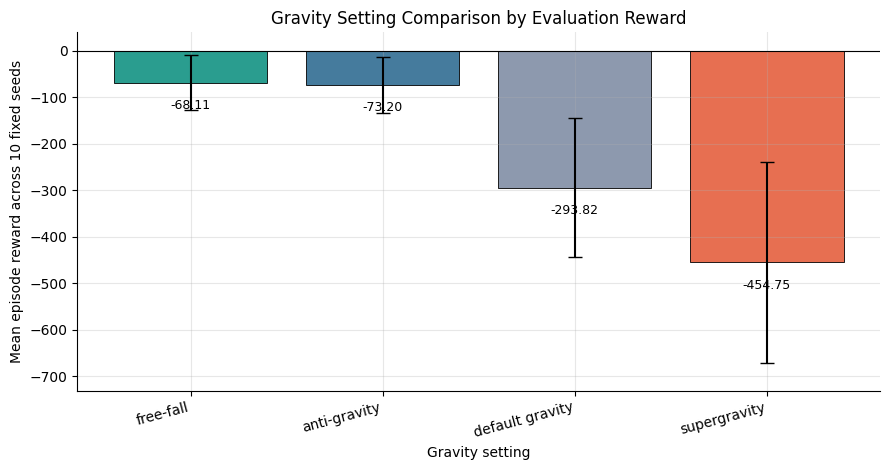

In [48]:
# Step 12.9: Visualise gravity evaluation reward comparison
if "gravity_comparison_table" not in globals():
    gravity_comparison_table = pd.read_csv(TABLE_DIR / "gravity_setting_comparison_summary.csv")

gravity_reward_plot_data = gravity_comparison_table.sort_values("rank").reset_index(drop=True)

fig, ax = plt.subplots(figsize=(9, 4.8))
bar_colors = ["#2a9d8f", "#457b9d", "#8d99ae", "#e76f51"]

bars = ax.bar(
    gravity_reward_plot_data["gravity setup"],
    gravity_reward_plot_data["eval mean reward"],
    yerr=gravity_reward_plot_data["eval reward std"],
    capsize=5,
    color=bar_colors,
    edgecolor="black",
    linewidth=0.6,
)

ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Gravity Setting Comparison by Evaluation Reward")
ax.set_xlabel("Gravity setting")
ax.set_ylabel("Mean episode reward across 10 fixed seeds")
ax.set_ylim(
    gravity_reward_plot_data["eval mean reward"].min()
    - gravity_reward_plot_data["eval reward std"].max()
    - 60,
    40,
)

for bar, reward in zip(bars, gravity_reward_plot_data["eval mean reward"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        reward - 35,
        f"{reward:.2f}",
        ha="center",
        va="top",
        fontsize=9,
        color="black",
    )

plt.xticks(rotation=15, ha="right")
plt.tight_layout()

gravity_reward_plot_path = PLOT_DIR / "gravity_setting_evaluation_reward_comparison.png"
plt.savefig(gravity_reward_plot_path, dpi=150)
plt.show()


### 12.9 Gravity Reward Plot Interpretation

The reward plot makes the first gravity ranking easier to inspect.

The main pattern is that supergravity is much weaker, while free-fall and anti-gravity are close enough that I should not rely on a single training run to separate them. This visual is therefore useful as an early comparison, but it does not fully show training-seed uncertainty.

Decision: keep this plot as exploratory evidence, then add a controlled plot later that shows individual training-seed points and the mean across training seeds.


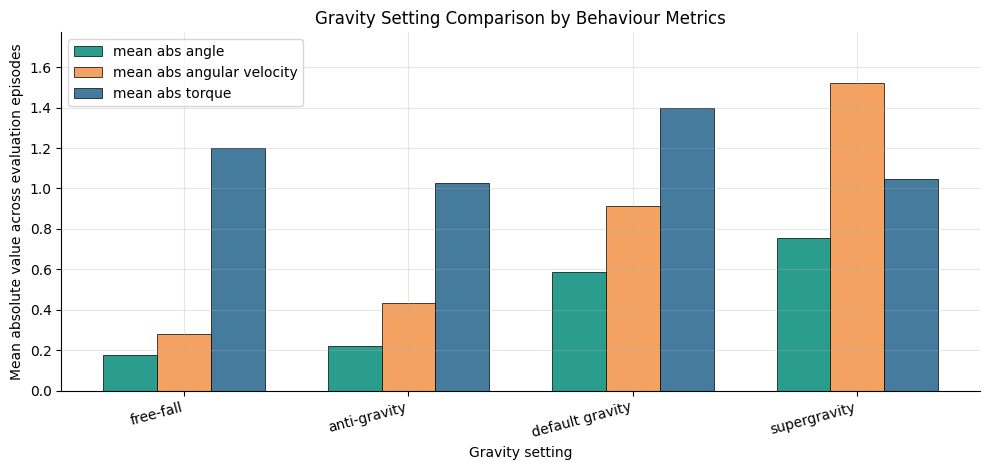

In [49]:
# Step 12.10: Visualise gravity behaviour metrics
if "gravity_comparison_table" not in globals():
    gravity_comparison_table = pd.read_csv(TABLE_DIR / "gravity_setting_comparison_summary.csv")

gravity_behavior_plot_data = gravity_comparison_table.sort_values("rank").reset_index(drop=True)
behavior_metrics = [
    "mean abs angle",
    "mean abs angular velocity",
    "mean abs torque",
]

x_positions = np.arange(len(gravity_behavior_plot_data))
bar_width = 0.24
metric_offsets = [-bar_width, 0, bar_width]
metric_colors = ["#2a9d8f", "#f4a261", "#457b9d"]

fig, ax = plt.subplots(figsize=(10, 4.8))

for metric, offset, color in zip(behavior_metrics, metric_offsets, metric_colors):
    ax.bar(
        x_positions + offset,
        gravity_behavior_plot_data[metric],
        width=bar_width,
        label=metric,
        color=color,
        edgecolor="black",
        linewidth=0.5,
    )

ax.set_title("Gravity Setting Comparison by Behaviour Metrics")
ax.set_xlabel("Gravity setting")
ax.set_ylabel("Mean absolute value across evaluation episodes")
ax.set_xticks(x_positions)
ax.set_xticklabels(gravity_behavior_plot_data["gravity setup"], rotation=15, ha="right")
ax.legend()
ax.set_ylim(0, gravity_behavior_plot_data[behavior_metrics].to_numpy().max() + 0.25)

plt.tight_layout()

gravity_behavior_plot_path = PLOT_DIR / "gravity_setting_behaviour_metrics_comparison.png"
plt.savefig(gravity_behavior_plot_path, dpi=150)
plt.show()


### 12.10 Gravity Behaviour Metrics Interpretation

The behaviour metrics add context to the reward comparison because reward alone does not show how the pendulum moved.

The first plot suggests that easier gravity settings tend to have lower angle error, while supergravity produces weaker and less stable behaviour. However, angle, angular velocity and torque have different units, so putting them into one grouped chart makes the comparison less clean than it should be.

Decision: keep this as a first behaviour check, then split the controlled gravity behaviour evidence into separate angle, angular-velocity and torque visuals later.


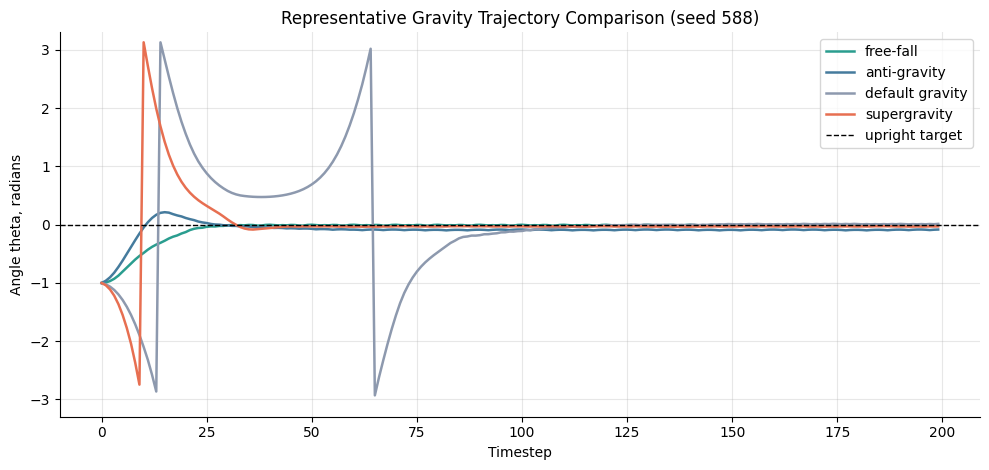

In [50]:
# Step 12.11: Visualise representative gravity angle trajectories
free_fall_paths = gravity_model_paths("free-fall")
anti_gravity_paths = gravity_model_paths("anti-gravity")
supergravity_paths = gravity_model_paths("supergravity")

trajectory_sources = [
    {
        "gravity setup": "free-fall",
        "path": free_fall_paths["evaluation_rollouts_path"],
    },
    {
        "gravity setup": "anti-gravity",
        "path": anti_gravity_paths["evaluation_rollouts_path"],
    },
    {
        "gravity setup": "default gravity",
        "path": SELECTED_DEFAULT_EVALUATION_ROLLOUTS_PATH,
    },
    {
        "gravity setup": "supergravity",
        "path": supergravity_paths["evaluation_rollouts_path"],
    },
]

trajectory_frames = []
for source in trajectory_sources:
    trajectory_frame = pd.read_csv(source["path"])
    trajectory_frame["gravity setup"] = source["gravity setup"]
    trajectory_frames.append(trajectory_frame)

gravity_trajectory_data = pd.concat(trajectory_frames, ignore_index=True)
representative_episode = 1
representative_seed = int(
    gravity_trajectory_data.loc[
        gravity_trajectory_data["evaluation_episode"] == representative_episode,
        "seed",
    ].iloc[0]
)

representative_trajectory_data = gravity_trajectory_data[
    gravity_trajectory_data["evaluation_episode"] == representative_episode
].copy()

trajectory_order = ["free-fall", "anti-gravity", "default gravity", "supergravity"]
trajectory_colors = {
    "free-fall": "#2a9d8f",
    "anti-gravity": "#457b9d",
    "default gravity": "#8d99ae",
    "supergravity": "#e76f51",
}

fig, ax = plt.subplots(figsize=(10, 4.8))

for gravity_setup in trajectory_order:
    setup_data = representative_trajectory_data[
        representative_trajectory_data["gravity setup"] == gravity_setup
    ]
    ax.plot(
        setup_data["step"],
        setup_data["theta"],
        label=gravity_setup,
        color=trajectory_colors[gravity_setup],
        linewidth=1.8,
    )

ax.axhline(0, color="black", linestyle="--", linewidth=1, label="upright target")
ax.set_title(f"Representative Gravity Trajectory Comparison (seed {representative_seed})")
ax.set_xlabel("Timestep")
ax.set_ylabel("Angle theta, radians")
ax.legend(loc="upper right")
ax.set_ylim(-3.3, 3.3)

plt.tight_layout()

gravity_trajectory_plot_path = PLOT_DIR / "gravity_setting_representative_angle_trajectories.png"
plt.savefig(gravity_trajectory_plot_path, dpi=150)
plt.show()


### 12.11 Gravity Trajectory Interpretation

The representative trajectories show how the gravity settings behave over time.

This visual is useful because it shows whether the policy actually keeps the pendulum near upright instead of only producing a better reward number. The original trajectory comparison is based on representative episodes, so it helps with interpretation, but it is not the cleanest possible control because the chosen episodes are not forced to use the same evaluation seed across every gravity setting.

Decision: keep this as behaviour evidence, then add a matched-seed trajectory plot later that includes default gravity and uses the same evaluation seed for all four gravity settings.


In [51]:
# Step 12.12: Record the best gravity-setting model
if "gravity_comparison_table" not in globals():
    gravity_comparison_table = pd.read_csv(TABLE_DIR / "gravity_setting_comparison_summary.csv")

gravity_model_selection_paths = {
    "default gravity": SELECTED_DQN_WEIGHTS_PATH,
    "free-fall": gravity_model_paths("free-fall")["weights_path"],
    "anti-gravity": gravity_model_paths("anti-gravity")["weights_path"],
    "supergravity": gravity_model_paths("supergravity")["weights_path"],
}

best_gravity_row = gravity_comparison_table.sort_values(
    by="eval mean reward",
    ascending=False,
).iloc[0]

FINAL_GRAVITY_SETUP = best_gravity_row["gravity setup"]
FINAL_GRAVITY_GYM_SETTING = best_gravity_row["gym setting"]
FINAL_ACTION_SET_NAME = SELECTED_ACTION_SET_NAME
FINAL_ACTION_VALUES = SELECTED_ACTION_VALUES.copy()
FINAL_NUM_ACTIONS = SELECTED_NUM_ACTIONS
FINAL_DQN_LEARNING_RATE = SELECTED_DQN_LEARNING_RATE
FINAL_DQN_WEIGHTS_PATH = gravity_model_selection_paths[FINAL_GRAVITY_SETUP]

final_gravity_model_selection = pd.DataFrame([
    {
        "selection check": "selection rule",
        "value": "mean reward first, checked with reward spread, angle and trajectory evidence",
        "meaning": "prevents the best setup from being chosen using reward alone",
    },
    {
        "selection check": "selected gravity setup",
        "value": FINAL_GRAVITY_SETUP,
        "meaning": "best combined evidence across the four gravity settings",
    },
    {
        "selection check": "gym setting",
        "value": FINAL_GRAVITY_GYM_SETTING,
        "meaning": "environment condition used by the selected model",
    },
    {
        "selection check": "selected action set",
        "value": FINAL_ACTION_SET_NAME,
        "meaning": "keeps the improved 9-action discretisation",
    },
    {
        "selection check": "selected learning rate",
        "value": FINAL_DQN_LEARNING_RATE,
        "meaning": "learning-rate choice carried forward from default-gravity tuning",
    },
    {
        "selection check": "number of discrete actions",
        "value": FINAL_NUM_ACTIONS,
        "meaning": "the DQN chooses from fixed torque choices",
    },
    {
        "selection check": "mean evaluation reward",
        "value": round(float(best_gravity_row["eval mean reward"]), 2),
        "meaning": "primary repeated-evaluation metric used for selection",
    },
    {
        "selection check": "reward standard deviation",
        "value": round(float(best_gravity_row["eval reward std"]), 2),
        "meaning": "checks consistency across the fixed evaluation seeds",
    },
    {
        "selection check": "mean absolute angle",
        "value": round(float(best_gravity_row["mean abs angle"]), 4),
        "meaning": "behaviour evidence for staying close to upright",
    },
    {
        "selection check": "selected weights file",
        "value": str(FINAL_DQN_WEIGHTS_PATH),
        "meaning": "saved model weights for the selected gravity-setting DQN",
    },
])

final_gravity_model_selection_path = TABLE_DIR / "final_gravity_model_selection.csv"
final_gravity_model_selection.to_csv(final_gravity_model_selection_path, index=False)

display(final_gravity_model_selection)
print("Saved final gravity model selection to:", final_gravity_model_selection_path)


,selection check,value,meaning
0,selection rule,"mean reward first, checked with reward spread,...",prevents the best setup from being chosen usin...
1,selected gravity setup,free-fall,best combined evidence across the four gravity...
2,gym setting,g = 0,environment condition used by the selected model
3,selected action set,15 actions,keeps the improved 9-action discretisation
4,selected learning rate,0.001,learning-rate choice carried forward from defa...
5,number of discrete actions,15,the DQN chooses from fixed torque choices
6,mean evaluation reward,-68.11,primary repeated-evaluation metric used for se...
7,reward standard deviation,58.94,checks consistency across the fixed evaluation...
8,mean absolute angle,0.1766,behaviour evidence for staying close to upright
9,selected weights file,C:\Users\USER\OneDrive - Singapore Polytechnic...,saved model weights for the selected gravity-s...


Saved final gravity model selection to: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_b_outputs\tables\final_gravity_model_selection.csv


### 12.12 Final Gravity-Setting Selection Interpretation

The first gravity-setting selection points to free-fall as the best setup in the original workflow.

This selection is reasonable because the output combines reward, reward spread, angle error and trajectory evidence. Anti-gravity remains close enough that I should not pretend the first ranking is beyond uncertainty, and supergravity remains the clearest stress-test limitation.

Decision: keep free-fall as the provisional selected setup, then use matched training seeds in the controlled audit before making the final conclusion.


## 13. Repeated Training-Seed Check and Demo Evidence

The gravity comparison already uses repeated evaluation episodes, but each major gravity model is still mainly represented by one training run.

I add one robustness check here without changing the earlier workflow. The aim is not to search for a better model after seeing the results. Instead, I repeat training for the provisional selected setup, the closest competing setup and the weakest setup, then check whether the same overall conclusion still looks reasonable.

The key comparison is **free-fall versus anti-gravity**. Their original mean rewards were close, so this is where training-seed luck could realistically affect the ranking. I still keep supergravity in the check because it supports the stress-test limitation.

I also create short GIF demos from the saved evaluation trajectories. These GIFs are behaviour evidence for the provisional workflow: they help me see whether the selected policy is actually keeping the pendulum close to upright, and they give a clear contrast against the harder supergravity case.


In [52]:
# Step 13.1: Define the repeated training-seed robustness check
REPEATED_TRAINING_SEED_CHECK_SETUPS = [
    {
        "setup role": "selected final setup",
        "gravity setup": "free-fall",
        "gravity value": 0.0,
        "reason for repeating": "checks whether the selected result depends too much on one training seed",
    },
    {
        "setup role": "closest competing setup",
        "gravity setup": "anti-gravity",
        "gravity value": -10.0,
        "reason for repeating": (
            "checks the close free-fall vs anti-gravity ranking, where the original reward gap "
            "was small compared with the evaluation spread"
        ),
    },
    {
        "setup role": "weakest stress-test setup",
        "gravity setup": "supergravity",
        "gravity value": 15.0,
        "reason for repeating": "checks whether the hardest case remains difficult under extra training seeds",
    },
]

REPEATED_TRAINING_SEEDS = [SEED + 5001, SEED + 6001]
REPEATED_TRAINING_EPISODES = GRAVITY_TRAINING_EPISODES
REPEATED_TRAINING_EVALUATION_SEEDS = GRAVITY_EVALUATION_SEEDS

repeated_training_seed_plan_rows = []

for setup in REPEATED_TRAINING_SEED_CHECK_SETUPS:
    for training_seed in REPEATED_TRAINING_SEEDS:
        repeated_training_seed_plan_rows.append({
            "setup role": setup["setup role"],
            "gravity setup": setup["gravity setup"],
            "gravity value": setup["gravity value"],
            "training seed": training_seed,
            "episodes": REPEATED_TRAINING_EPISODES,
            "evaluation seeds": str(REPEATED_TRAINING_EVALUATION_SEEDS),
            "reason": setup["reason for repeating"],
        })

repeated_training_seed_plan = pd.DataFrame(repeated_training_seed_plan_rows)
repeated_training_seed_plan_path = TABLE_DIR / "repeated_training_seed_check_plan.csv"
repeated_training_seed_plan.to_csv(repeated_training_seed_plan_path, index=False)

display(repeated_training_seed_plan)
print("Saved repeated training-seed plan to:", repeated_training_seed_plan_path)


,setup role,gravity setup,gravity value,training seed,episodes,evaluation seeds,reason
0,selected final setup,free-fall,0.0,5089,100,"[588, 589, 590, 591, 592, 593, 594, 595, 596, ...",checks whether the selected result depends too...
1,selected final setup,free-fall,0.0,6089,100,"[588, 589, 590, 591, 592, 593, 594, 595, 596, ...",checks whether the selected result depends too...
2,closest competing setup,anti-gravity,-10.0,5089,100,"[588, 589, 590, 591, 592, 593, 594, 595, 596, ...",checks the close free-fall vs anti-gravity ran...
3,closest competing setup,anti-gravity,-10.0,6089,100,"[588, 589, 590, 591, 592, 593, 594, 595, 596, ...",checks the close free-fall vs anti-gravity ran...
4,weakest stress-test setup,supergravity,15.0,5089,100,"[588, 589, 590, 591, 592, 593, 594, 595, 596, ...",checks whether the hardest case remains diffic...
5,weakest stress-test setup,supergravity,15.0,6089,100,"[588, 589, 590, 591, 592, 593, 594, 595, 596, ...",checks whether the hardest case remains diffic...


Saved repeated training-seed plan to: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_b_outputs\tables\repeated_training_seed_check_plan.csv


### 13.1 Repeated Training-Seed Check Plan Interpretation

This check targets the remaining uncertainty in the provisional gravity workflow.

The earlier evaluation used repeated fixed evaluation seeds, so the policy was not judged from only one episode. However, DQN training itself can still change depending on the random seed because the replay samples, exploration actions and initial network weights are random.

I repeat the provisional free-fall setup because it was the selected setup at this point in the workflow. I also repeat anti-gravity because it is the closest competitor: the original gap between free-fall and anti-gravity was much smaller than the gap between free-fall and supergravity. This means anti-gravity is the setup most likely to challenge the provisional ranking under another training seed.

I keep supergravity in the check as well, but for a different reason. It is not the closest competitor; it is the stress-test limitation. If it remains weak after extra seeds, that supports the claim that stronger gravity is harder for this DQN workflow.

Decision: use two extra independent training seeds for free-fall, anti-gravity and supergravity. I keep these runs as robustness evidence for the earlier workflow, not as a new search for the final controlled model.


In [53]:
# Step 13.2: Train or load the repeated-seed models and evaluate them
def repeated_seed_model_paths(gravity_setup, training_seed):
    slug = gravity_slug(gravity_setup)
    tuning_suffix = "" if SELECTED_TUNING_SLUG == "standard_lr_001" else f"_{SELECTED_TUNING_SLUG}"
    seed_tag = f"seed_{int(training_seed)}"

    return {
        "weights_path": MODEL_DIR / f"robustness_{slug}{tuning_suffix}_{seed_tag}_{SELECTED_ACTION_FILE_TAG}_dqn.weights.h5",
        "history_path": TABLE_DIR / f"robustness_{slug}{tuning_suffix}_{seed_tag}_{SELECTED_ACTION_FILE_TAG}_training_history.csv",
        "evaluation_rollouts_path": TABLE_DIR / f"robustness_{slug}{tuning_suffix}_{seed_tag}_{SELECTED_ACTION_FILE_TAG}_evaluation_rollouts.csv",
        "evaluation_scores_path": TABLE_DIR / f"robustness_{slug}{tuning_suffix}_{seed_tag}_{SELECTED_ACTION_FILE_TAG}_evaluation_episode_scores.csv",
    }


def build_repeated_seed_q_network_pair(gravity_setup, training_seed):
    slug = gravity_slug(gravity_setup)
    q_network = build_q_network(
        input_dim=STATE_DIM,
        num_actions=SELECTED_NUM_ACTIONS,
        learning_rate=SELECTED_DQN_LEARNING_RATE,
        name=f"robustness_{slug}_{int(training_seed)}_q_network",
    )
    target_network = build_q_network(
        input_dim=STATE_DIM,
        num_actions=SELECTED_NUM_ACTIONS,
        learning_rate=SELECTED_DQN_LEARNING_RATE,
        name=f"robustness_{slug}_{int(training_seed)}_target_network",
    )
    target_network.set_weights(q_network.get_weights())
    return q_network, target_network


def train_or_load_repeated_seed_dqn(
    gravity_setup,
    gravity_value,
    training_seed,
    q_network,
    target_network,
    weights_path,
    history_path,
    force_retrain=False,
):
    if weights_path.exists() and history_path.exists() and not force_retrain:
        try:
            load_model_weights_without_optimizer_warning(q_network, weights_path)
            update_target_network(q_network, target_network)
            history_df = pd.read_csv(history_path)
            return history_df, "loaded"
        except ValueError as error:
            print(f"Saved robustness files for {gravity_setup}, seed {training_seed} could not be reused.")
            print("Load issue:", error)

    random.seed(training_seed)
    np.random.seed(training_seed)
    tf.random.set_seed(training_seed)

    local_replay_memory = deque(maxlen=REPLAY_MEMORY_SIZE)
    training_records = []
    global_step = 0

    for episode in range(1, REPEATED_TRAINING_EPISODES + 1):
        episode_seed = int(training_seed + episode)
        env = make_pendulum_env(gravity=gravity_value, seed=episode_seed)
        state = reset_env(env, seed=episode_seed)

        episode_reward = 0.0
        episode_losses = []
        random_action_count = 0
        greedy_action_count = 0

        for step in range(GRAVITY_MAX_STEPS_PER_EPISODE):
            epsilon = epsilon_by_step(global_step)

            if np.random.random() < epsilon:
                action_index = int(np.random.randint(SELECTED_NUM_ACTIONS))
                random_action_count += 1
            else:
                state_batch = np.asarray(state, dtype=np.float32).reshape(1, -1)
                q_values = q_network(state_batch, training=False).numpy()[0]
                action_index = int(np.argmax(q_values))
                greedy_action_count += 1

            action = selected_action_index_to_env_action(action_index)
            next_state, reward, done, _ = step_env(env, action)
            store_transition(local_replay_memory, state, action_index, reward, next_state, done)

            if (
                len(local_replay_memory) >= MIN_REPLAY_SIZE
                and global_step % GRAVITY_TRAIN_EVERY_STEPS == 0
            ):
                loss = train_dqn_batch(q_network, target_network, local_replay_memory)
                if loss is not None:
                    episode_losses.append(loss)

            episode_reward += float(reward)
            state = next_state
            global_step += 1

            if done:
                break

        env.close()

        if episode % GRAVITY_TARGET_UPDATE_EVERY_EPISODES == 0:
            update_target_network(q_network, target_network)

        mean_loss = np.mean(episode_losses) if episode_losses else np.nan
        training_records.append({
            "gravity_setup": gravity_setup,
            "training_seed": int(training_seed),
            "episode": episode,
            "episode_reward": episode_reward,
            "mean_loss": mean_loss,
            "epsilon_end": epsilon_by_step(global_step),
            "replay_size": len(local_replay_memory),
            "random_actions": random_action_count,
            "greedy_actions": greedy_action_count,
            "steps": step + 1,
        })

        if episode % 10 == 0:
            print(
                f"{gravity_setup} | seed {training_seed} | episode {episode:03d} | "
                f"reward {episode_reward:8.2f} | epsilon {epsilon_by_step(global_step):.3f}"
            )

    history_df = pd.DataFrame(training_records)
    history_df.to_csv(history_path, index=False)
    q_network.save_weights(str(weights_path))
    update_target_network(q_network, target_network)

    return history_df, "trained"


repeated_training_seed_rows = []

for setup in REPEATED_TRAINING_SEED_CHECK_SETUPS:
    gravity_setup = setup["gravity setup"]
    gravity_value = setup["gravity value"]

    for training_seed in REPEATED_TRAINING_SEEDS:
        paths = repeated_seed_model_paths(gravity_setup, training_seed)
        q_network, target_network = build_repeated_seed_q_network_pair(gravity_setup, training_seed)

        history, source = train_or_load_repeated_seed_dqn(
            gravity_setup=gravity_setup,
            gravity_value=gravity_value,
            training_seed=training_seed,
            q_network=q_network,
            target_network=target_network,
            weights_path=paths["weights_path"],
            history_path=paths["history_path"],
            force_retrain=False,
        )

        rollouts, scores, eval_summary = evaluate_gravity_dqn(
            gravity_setup=gravity_setup,
            gravity_value=gravity_value,
            q_network=q_network,
            evaluation_seeds=REPEATED_TRAINING_EVALUATION_SEEDS,
        )

        rollouts["training_seed"] = int(training_seed)
        scores["training_seed"] = int(training_seed)
        rollouts.to_csv(paths["evaluation_rollouts_path"], index=False)
        scores.to_csv(paths["evaluation_scores_path"], index=False)

        best_training_row = history.loc[history["episode_reward"].idxmax()]
        eval_row = eval_summary.iloc[0]

        repeated_training_seed_rows.append({
            "gravity setup": gravity_setup,
            "training seed": int(training_seed),
            "training source": source,
            "last 10 train mean": round(float(history["episode_reward"].tail(10).mean()), 2),
            "best train reward": round(float(best_training_row["episode_reward"]), 2),
            "eval mean reward": round(float(eval_row["mean_total_reward"]), 2),
            "eval reward std": round(float(eval_row["std_total_reward"]), 2),
            "eval best reward": round(float(eval_row["best_total_reward"]), 2),
            "eval worst reward": round(float(eval_row["worst_total_reward"]), 2),
            "mean abs angle": round(float(eval_row["mean_abs_angle"]), 4),
            "mean abs angular velocity": round(float(eval_row["mean_abs_angular_velocity"]), 4),
            "mean abs torque": round(float(eval_row["mean_abs_torque"]), 4),
            "weights file": str(paths["weights_path"]),
        })

repeated_training_seed_check = pd.DataFrame(repeated_training_seed_rows)
repeated_training_seed_check_path = TABLE_DIR / "repeated_training_seed_check_summary.csv"
repeated_training_seed_check.to_csv(repeated_training_seed_check_path, index=False)

display(repeated_training_seed_check)
print("Saved repeated training-seed check to:", repeated_training_seed_check_path)


,gravity setup,training seed,training source,last 10 train mean,best train reward,eval mean reward,eval reward std,eval best reward,eval worst reward,mean abs angle,mean abs angular velocity,mean abs torque,weights file
0,free-fall,5089,loaded,-71.50,-1.36,-66.60,54.31,-4.41,-152.26,0.2552,0.2562,0.2181,C:\Users\USER\OneDrive - Singapore Polytechnic...
1,free-fall,6089,loaded,-65.61,-1.68,-66.32,52.71,-6.03,-143.52,0.2693,0.2932,1.0707,C:\Users\USER\OneDrive - Singapore Polytechnic...
2,anti-gravity,5089,loaded,-91.41,-1.25,-80.58,61.36,-11.50,-162.59,0.3276,0.4445,1.2656,C:\Users\USER\OneDrive - Singapore Polytechnic...
3,anti-gravity,6089,loaded,-74.63,-0.74,-73.46,63.33,-2.31,-160.34,0.1670,0.4244,0.3409,C:\Users\USER\OneDrive - Singapore Polytechnic...
4,supergravity,5089,loaded,-814.56,-1.95,-818.58,186.93,-482.25,-970.10,1.3135,3.0446,1.6897,C:\Users\USER\OneDrive - Singapore Polytechnic...
5,supergravity,6089,loaded,-498.73,-1.53,-433.63,183.86,-122.54,-690.97,0.7105,1.4815,1.2576,C:\Users\USER\OneDrive - Singapore Polytechnic...


Saved repeated training-seed check to: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_b_outputs\tables\repeated_training_seed_check_summary.csv


In [54]:
# Step 13.3: Compare the repeated-seed check against the original gravity ranking
if "repeated_training_seed_check" not in globals():
    repeated_training_seed_check = pd.read_csv(TABLE_DIR / "repeated_training_seed_check_summary.csv")

if "gravity_comparison_table" not in globals():
    gravity_comparison_table = pd.read_csv(TABLE_DIR / "gravity_setting_comparison_summary.csv")

robustness_comparison_rows = []

for gravity_setup in ["free-fall", "anti-gravity", "supergravity"]:
    original_row = gravity_comparison_table[
        gravity_comparison_table["gravity setup"] == gravity_setup
    ].iloc[0]
    repeated_rows = repeated_training_seed_check[
        repeated_training_seed_check["gravity setup"] == gravity_setup
    ]

    robustness_comparison_rows.append({
        "gravity setup": gravity_setup,
        "original eval mean reward": round(float(original_row["eval mean reward"]), 2),
        "extra-seed mean reward": round(float(repeated_rows["eval mean reward"].mean()), 2),
        "extra-seed reward std": round(float(repeated_rows["eval mean reward"].std()), 2),
        "original mean abs angle": round(float(original_row["mean abs angle"]), 4),
        "extra-seed mean abs angle": round(float(repeated_rows["mean abs angle"].mean()), 4),
        "extra training runs": len(repeated_rows),
    })

repeated_training_seed_setup_comparison = pd.DataFrame(robustness_comparison_rows)
repeated_training_seed_setup_comparison_path = TABLE_DIR / "repeated_training_seed_setup_comparison.csv"
repeated_training_seed_setup_comparison.to_csv(
    repeated_training_seed_setup_comparison_path,
    index=False,
)

free_fall_extra_mean = float(
    repeated_training_seed_setup_comparison.loc[
        repeated_training_seed_setup_comparison["gravity setup"] == "free-fall",
        "extra-seed mean reward",
    ].iloc[0]
)
antigravity_extra_mean = float(
    repeated_training_seed_setup_comparison.loc[
        repeated_training_seed_setup_comparison["gravity setup"] == "anti-gravity",
        "extra-seed mean reward",
    ].iloc[0]
)
supergravity_extra_mean = float(
    repeated_training_seed_setup_comparison.loc[
        repeated_training_seed_setup_comparison["gravity setup"] == "supergravity",
        "extra-seed mean reward",
    ].iloc[0]
)

free_fall_vs_antigravity_gap = free_fall_extra_mean - antigravity_extra_mean
free_fall_vs_supergravity_gap = free_fall_extra_mean - supergravity_extra_mean

if free_fall_vs_antigravity_gap > 0:
    robustness_message = (
        "The extra training-seed check keeps free-fall ahead of anti-gravity, "
        "so the closest competing ranking is supported beyond the original training run."
    )
else:
    robustness_message = (
        "The extra training-seed check does not keep free-fall ahead of anti-gravity. "
        "The original ranking between these two settings should be treated as uncertain "
        "given normal DQN training variance, rather than a confident conclusion."
    )

stress_test_message = (
    f"The extra-seed free-fall vs supergravity reward gap is {free_fall_vs_supergravity_gap:.2f}, "
    "so this remains the stress-test comparison rather than the closest-ranking comparison."
)

display(repeated_training_seed_setup_comparison)
print(robustness_message)
print(stress_test_message)
print("Saved repeated-seed setup comparison to:", repeated_training_seed_setup_comparison_path)


,gravity setup,original eval mean reward,extra-seed mean reward,extra-seed reward std,original mean abs angle,extra-seed mean abs angle,extra training runs
0,free-fall,-68.11,-66.46,0.20,0.1766,0.2622,2
1,anti-gravity,-73.20,-77.02,5.03,0.2220,0.2473,2
2,supergravity,-454.75,-626.11,272.20,0.7529,1.0120,2


The extra training-seed check keeps free-fall ahead of anti-gravity, so the closest competing ranking is supported beyond the original training run.
The extra-seed free-fall vs supergravity reward gap is 559.65, so this remains the stress-test comparison rather than the closest-ranking comparison.
Saved repeated-seed setup comparison to: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_b_outputs\tables\repeated_training_seed_setup_comparison.csv


### 13.2 Repeated Training-Seed Check Interpretation

The repeated training-seed check improves the evidence, but it is still only a partial robustness check.

It is useful because it tests whether the close free-fall versus anti-gravity result survives extra training seeds. It also keeps supergravity in the discussion as the stress-test setting. This is stronger than relying on only one training run per gravity setup.

The remaining limitation is that default gravity is not included in this repeated-seed check, and the extra seeds are added after the earlier one-run comparison rather than being part of one fully matched experiment grid from the start.

Decision: keep this section as supporting robustness evidence, then use the next matched-seed audit as the final evidence layer.


,gravity setup,representative seed,representative episode,total reward,mean abs angle,gif path,created
0,free-fall,594,7,-51.58,0.1559,C:\Users\USER\OneDrive - Singapore Polytechnic...,True
1,supergravity,594,7,-472.85,0.7813,C:\Users\USER\OneDrive - Singapore Polytechnic...,True


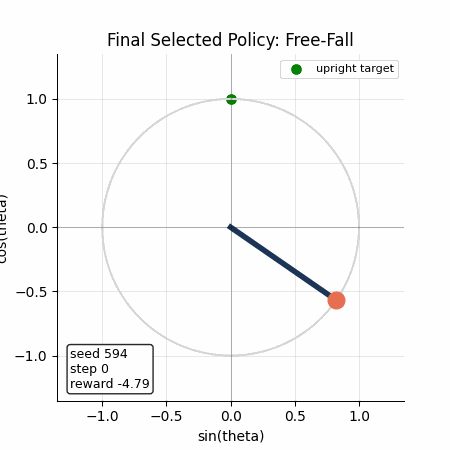

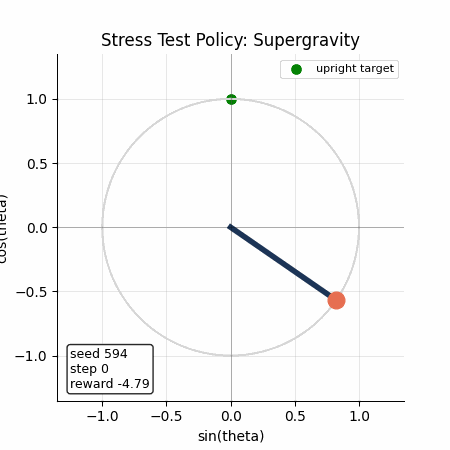

Saved GIF demo summary to: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_b_outputs\tables\final_demo_gif_summary.csv


In [55]:
# Step 13.4: Create GIF demos from representative evaluation trajectories
from IPython.display import Image as IPythonImage
from matplotlib.animation import FuncAnimation, PillowWriter

GIF_DIR = OUTPUT_DIR / "gifs"
GIF_DIR.mkdir(parents=True, exist_ok=True)


def gravity_rollout_and_score_paths(gravity_setup):
    if gravity_setup == "default gravity":
        return {
            "rollouts_path": SELECTED_DEFAULT_EVALUATION_ROLLOUTS_PATH,
            "scores_path": SELECTED_DEFAULT_EVALUATION_SCORES_PATH,
        }

    paths = gravity_model_paths(gravity_setup)
    return {
        "rollouts_path": paths["evaluation_rollouts_path"],
        "scores_path": paths["evaluation_scores_path"],
    }


def select_representative_evaluation_rollout(gravity_setup):
    paths = gravity_rollout_and_score_paths(gravity_setup)
    rollouts = pd.read_csv(paths["rollouts_path"])
    scores = pd.read_csv(paths["scores_path"])

    median_reward = scores["total_reward"].median()
    representative_score = scores.iloc[
        (scores["total_reward"] - median_reward).abs().argsort().iloc[0]
    ]
    representative_episode = int(representative_score["evaluation_episode"])
    representative_seed = int(representative_score["seed"])

    representative_rollout = rollouts[
        rollouts["evaluation_episode"] == representative_episode
    ].copy()

    return representative_rollout, representative_score, representative_seed


def create_pendulum_policy_gif(gravity_setup, title, gif_path, fps=12):
    rollout, score, representative_seed = select_representative_evaluation_rollout(gravity_setup)
    frame_indices = list(range(0, len(rollout), 2))
    if frame_indices[-1] != len(rollout) - 1:
        frame_indices.append(len(rollout) - 1)

    theta_values = rollout["theta"].to_numpy()
    reward_values = rollout["reward"].to_numpy()
    step_values = rollout["step"].to_numpy()

    circle_angles = np.linspace(0, 2 * np.pi, 300)

    fig, ax = plt.subplots(figsize=(4.5, 4.5))
    ax.plot(np.sin(circle_angles), np.cos(circle_angles), color="lightgray", linewidth=1.5)
    ax.scatter([0], [1], color="green", s=45, label="upright target")

    arm_line, = ax.plot([], [], color="#1d3557", linewidth=4)
    bob_point, = ax.plot([], [], marker="o", color="#e76f51", markersize=12)
    trace_line, = ax.plot([], [], color="#457b9d", linewidth=1.2, alpha=0.45)
    info_text = ax.text(
        -1.25,
        -1.25,
        "",
        fontsize=9,
        bbox={"boxstyle": "round,pad=0.25", "facecolor": "white", "alpha": 0.85},
    )

    ax.axhline(0, color="black", linewidth=0.8, alpha=0.25)
    ax.axvline(0, color="black", linewidth=0.8, alpha=0.25)
    ax.set_xlim(-1.35, 1.35)
    ax.set_ylim(-1.35, 1.35)
    ax.set_aspect("equal")
    ax.set_title(title)
    ax.set_xlabel("sin(theta)")
    ax.set_ylabel("cos(theta)")
    ax.legend(loc="upper right", fontsize=8)

    trace_x = []
    trace_y = []

    def update(frame_position):
        frame = frame_indices[frame_position]
        theta = theta_values[frame]
        x = float(np.sin(theta))
        y = float(np.cos(theta))

        trace_x.append(x)
        trace_y.append(y)

        arm_line.set_data([0, x], [0, y])
        bob_point.set_data([x], [y])
        trace_line.set_data(trace_x, trace_y)
        info_text.set_text(
            f"seed {representative_seed}\n"
            f"step {int(step_values[frame])}\n"
            f"reward {reward_values[frame]:.2f}"
        )
        return arm_line, bob_point, trace_line, info_text

    animation = FuncAnimation(
        fig,
        update,
        frames=len(frame_indices),
        interval=1000 / fps,
        blit=False,
    )

    animation.save(str(gif_path), writer=PillowWriter(fps=fps))
    plt.close(fig)

    return {
        "gravity setup": gravity_setup,
        "representative seed": representative_seed,
        "representative episode": int(score["evaluation_episode"]),
        "total reward": round(float(score["total_reward"]), 2),
        "mean abs angle": round(float(score["mean_abs_angle"]), 4),
        "gif path": str(gif_path),
    }


gif_demo_specs = [
    {
        "gravity setup": "free-fall",
        "title": "Final Selected Policy: Free-Fall",
        "gif path": GIF_DIR / "final_free_fall_policy_demo.gif",
    },
    {
        "gravity setup": "supergravity",
        "title": "Stress Test Policy: Supergravity",
        "gif path": GIF_DIR / "supergravity_stress_test_policy_demo.gif",
    },
]

gif_demo_rows = []

for demo in gif_demo_specs:
    try:
        row = create_pendulum_policy_gif(
            gravity_setup=demo["gravity setup"],
            title=demo["title"],
            gif_path=demo["gif path"],
        )
        row["created"] = True
    except Exception as error:
        row = {
            "gravity setup": demo["gravity setup"],
            "representative seed": np.nan,
            "representative episode": np.nan,
            "total reward": np.nan,
            "mean abs angle": np.nan,
            "gif path": str(demo["gif path"]),
            "created": False,
            "error": str(error),
        }
    gif_demo_rows.append(row)

final_demo_gif_summary = pd.DataFrame(gif_demo_rows)
final_demo_gif_summary_path = TABLE_DIR / "final_demo_gif_summary.csv"
final_demo_gif_summary.to_csv(final_demo_gif_summary_path, index=False)

display(final_demo_gif_summary)

for gif_path in final_demo_gif_summary.loc[final_demo_gif_summary["created"], "gif path"]:
    display(IPythonImage(filename=gif_path))

print("Saved GIF demo summary to:", final_demo_gif_summary_path)


### 13.3 Final Demo GIF Interpretation

The GIFs in this section are useful behaviour evidence for the earlier provisional workflow.

They show what the selected policy looked like before the matched-seed audit was added. However, the later controlled audit changes the selected configuration from the earlier 15-action direction to a **5-action** setup with a **5-episode target update**. Because of that, I should not use these older GIFs as the final demo evidence.

Decision: keep these GIFs as part of the development story, but generate a new controlled final GIF later from the actual matched-seed selected model.


## 14. Controlled Matched-Seed Experiment Audit

The earlier sections built the workflow step by step. They are useful because they show how the DQN was developed, but the strictest evaluation issue is that some model comparisons used different training seeds.

In this section, I add a final audit layer. The aim is not to restart the story of the notebook. The aim is to check the important decisions under the same conditions: the same training seeds, the same evaluation seeds, the same episode budget and the same DQN training loop.

The controlled audit focuses on the choices that can change the final policy most directly: action count, target-network update interval, learning rate, epsilon endpoint and gravity setting. This makes the final conclusion more evidence-led because the selected model is not based only on one lucky training run.


In [56]:
# Step 14.1: Define matched-seed controlled experiment helpers
CONTROLLED_OUTPUT_DIR = OUTPUT_DIR / "controlled_matched_seed"
CONTROLLED_MODEL_DIR = CONTROLLED_OUTPUT_DIR / "models"
CONTROLLED_TABLE_DIR = CONTROLLED_OUTPUT_DIR / "tables"
CONTROLLED_PLOT_DIR = CONTROLLED_OUTPUT_DIR / "plots"

for folder in [CONTROLLED_OUTPUT_DIR, CONTROLLED_MODEL_DIR, CONTROLLED_TABLE_DIR, CONTROLLED_PLOT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

CONTROLLED_TRAINING_SEEDS = [SEED, SEED + 101, SEED + 202]
CONTROLLED_EVALUATION_EPISODES = 20
CONTROLLED_EVALUATION_SEEDS = [SEED + 6000 + episode for episode in range(CONTROLLED_EVALUATION_EPISODES)]
CONTROLLED_DQN_EPISODES = BASELINE_DQN_EPISODES
CONTROLLED_MAX_STEPS_PER_EPISODE = MAX_STEPS_PER_EPISODE
CONTROLLED_TRAIN_EVERY_STEPS = TRAIN_EVERY_STEPS
CONTROLLED_FORCE_RETRAIN = False

CONTROLLED_ACTION_SETS = {
    5: ACTION_VALUES.copy(),
    9: ACTION_SET_9.copy(),
    15: ACTION_SET_15.copy(),
}

CONTROLLED_TARGET_UPDATE_CANDIDATES = [5, 10, 20]
CONTROLLED_LEARNING_RATE_CANDIDATES = [0.01, 0.001, 0.0005]
CONTROLLED_EPSILON_END_CANDIDATES = [0.05, 0.01]
CONTROLLED_GRAVITY_SETUPS = [
    {"gravity_name": "default gravity", "gravity_value": None, "gym_setting": "default Pendulum gravity"},
    {"gravity_name": "free-fall", "gravity_value": 0.0, "gym_setting": "g = 0"},
    {"gravity_name": "anti-gravity", "gravity_value": -10.0, "gym_setting": "g = -10"},
    {"gravity_name": "supergravity", "gravity_value": 15.0, "gym_setting": "g = 15"},
]


def controlled_float_tag(value):
    if value is None:
        return "default"
    return str(value).replace("-", "neg").replace(".", "p")


def controlled_action_to_env_action(action_index, action_values):
    torque = float(action_values[int(action_index)])
    return np.array([torque], dtype=np.float32)


def controlled_epsilon_by_step(step, epsilon_end):
    progress = min(float(step) / EPSILON_DECAY_STEPS, 1.0)
    return EPSILON_START + progress * (epsilon_end - EPSILON_START)


def build_controlled_q_network(input_dim, num_actions, learning_rate, hidden_units=(128, 128), activation="relu", name="controlled_q_network"):
    inputs = tf.keras.Input(shape=(input_dim,), name="state_input")
    x = inputs
    for layer_index, units in enumerate(hidden_units, start=1):
        x = tf.keras.layers.Dense(units, activation=activation, name=f"dense_{layer_index}")(x)
    q_values = tf.keras.layers.Dense(num_actions, activation="linear", name="q_values")(x)
    model = tf.keras.Model(inputs=inputs, outputs=q_values, name=name)
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate), loss=tf.keras.losses.Huber())
    return model


def make_controlled_config(experiment_group, action_count, action_values, learning_rate, epsilon_end, target_update_every, gravity_name="default gravity", gravity_value=None, hidden_units=(128, 128), activation="relu"):
    hidden_tag = "x".join(str(unit) for unit in hidden_units)
    slug = f"{experiment_group}_{action_count}act_lr{controlled_float_tag(learning_rate)}_eps{controlled_float_tag(epsilon_end)}_tu{target_update_every}_h{hidden_tag}_g{controlled_float_tag(gravity_value)}"
    return {
        "experiment_group": experiment_group,
        "config_slug": slug,
        "action_count": int(action_count),
        "action_label": f"{int(action_count)} actions",
        "action_values": np.asarray(action_values, dtype=np.float32),
        "learning_rate": float(learning_rate),
        "learning_rate_label": str(learning_rate),
        "epsilon_end": float(epsilon_end),
        "epsilon_label": str(epsilon_end),
        "target_update_every": int(target_update_every),
        "target_update_label": f"every {int(target_update_every)} episodes",
        "gravity_name": gravity_name,
        "gravity_value": gravity_value,
        "hidden_units": tuple(hidden_units),
        "activation": activation,
    }


def controlled_model_paths(config, train_seed):
    stem = f"{config['config_slug']}_seed_{int(train_seed)}"
    return {
        "weights_path": CONTROLLED_MODEL_DIR / f"{stem}.weights.h5",
        "history_path": CONTROLLED_TABLE_DIR / f"{stem}_history.csv",
    }


def controlled_train_batch(q_network, target_network, memory, batch_size=BATCH_SIZE, gamma=GAMMA):
    if len(memory) < batch_size:
        return None
    batch = random.sample(memory, batch_size)
    states = np.asarray([item[0] for item in batch], dtype=np.float32)
    action_indices = np.asarray([item[1] for item in batch], dtype=np.int64)
    rewards = np.asarray([item[2] for item in batch], dtype=np.float32)
    next_states = np.asarray([item[3] for item in batch], dtype=np.float32)
    dones = np.asarray([item[4] for item in batch], dtype=np.float32)
    current_q_values = q_network(states, training=False).numpy()
    next_q_values = target_network(next_states, training=False).numpy()
    target_q_values = current_q_values.copy()
    target_q_values[np.arange(batch_size), action_indices] = rewards + (1.0 - dones) * gamma * np.max(next_q_values, axis=1)
    return float(q_network.train_on_batch(states, target_q_values))


def train_or_load_controlled_dqn(config, train_seed, force_retrain=CONTROLLED_FORCE_RETRAIN):
    tf.keras.backend.clear_session()
    random.seed(int(train_seed))
    np.random.seed(int(train_seed))
    tf.random.set_seed(int(train_seed))
    num_actions = int(config["action_count"])
    paths = controlled_model_paths(config, train_seed)

    q_network = build_controlled_q_network(STATE_DIM, num_actions, config["learning_rate"], config["hidden_units"], config["activation"], f"{config['config_slug']}_q_network")
    target_network = build_controlled_q_network(STATE_DIM, num_actions, config["learning_rate"], config["hidden_units"], config["activation"], f"{config['config_slug']}_target_network")
    target_network.set_weights(q_network.get_weights())

    if paths["weights_path"].exists() and paths["history_path"].exists() and not force_retrain:
        try:
            load_model_weights_without_optimizer_warning(q_network, paths["weights_path"])
            update_target_network(q_network, target_network)
            return q_network, pd.read_csv(paths["history_path"]), "loaded", paths
        except ValueError as error:
            print(f"Saved controlled model could not be reused for {config['config_slug']} seed {train_seed}.")
            print("Load issue:", error)

    local_replay_memory = deque(maxlen=REPLAY_MEMORY_SIZE)
    training_records = []
    global_step = 0

    for episode in range(1, CONTROLLED_DQN_EPISODES + 1):
        episode_seed = int(train_seed + episode)
        env = make_pendulum_env(gravity=config["gravity_value"], seed=episode_seed)
        state = reset_env(env, seed=episode_seed)
        episode_reward = 0.0
        episode_losses = []
        random_action_count = 0
        greedy_action_count = 0

        for step in range(CONTROLLED_MAX_STEPS_PER_EPISODE):
            epsilon = controlled_epsilon_by_step(global_step, config["epsilon_end"])
            if np.random.random() < epsilon:
                action_index = int(np.random.randint(num_actions))
                random_action_count += 1
            else:
                q_values = q_network(np.asarray(state, dtype=np.float32).reshape(1, -1), training=False).numpy()[0]
                action_index = int(np.argmax(q_values))
                greedy_action_count += 1

            action = controlled_action_to_env_action(action_index, config["action_values"])
            next_state, reward, done, _ = step_env(env, action)
            store_transition(local_replay_memory, state, action_index, reward, next_state, done)

            if len(local_replay_memory) >= MIN_REPLAY_SIZE and global_step % CONTROLLED_TRAIN_EVERY_STEPS == 0:
                loss = controlled_train_batch(q_network, target_network, local_replay_memory)
                if loss is not None:
                    episode_losses.append(loss)

            episode_reward += float(reward)
            state = next_state
            global_step += 1
            if done:
                break

        env.close()
        if episode % int(config["target_update_every"]) == 0:
            update_target_network(q_network, target_network)

        training_records.append({
            "experiment_group": config["experiment_group"],
            "config_slug": config["config_slug"],
            "train_seed": int(train_seed),
            "episode": episode,
            "episode_reward": episode_reward,
            "mean_loss": np.mean(episode_losses) if episode_losses else np.nan,
            "epsilon_end_value": controlled_epsilon_by_step(global_step, config["epsilon_end"]),
            "replay_size": len(local_replay_memory),
            "random_actions": random_action_count,
            "greedy_actions": greedy_action_count,
            "steps": step + 1,
        })

        if episode % 25 == 0:
            print(f"{config['experiment_group']} | {config['config_slug']} | seed {train_seed} | episode {episode:03d} | reward {episode_reward:8.2f} | epsilon {controlled_epsilon_by_step(global_step, config['epsilon_end']):.3f}")

    history_df = pd.DataFrame(training_records)
    history_df.to_csv(paths["history_path"], index=False)
    q_network.save_weights(str(paths["weights_path"]))
    update_target_network(q_network, target_network)
    return q_network, history_df, "trained", paths


def evaluate_controlled_dqn(config, q_network, train_seed, evaluation_seeds=CONTROLLED_EVALUATION_SEEDS, keep_rollouts=False):
    score_rows = []
    rollout_rows = []
    for evaluation_episode, eval_seed in enumerate(evaluation_seeds, start=1):
        env = make_pendulum_env(gravity=config["gravity_value"], seed=int(eval_seed))
        state = reset_env(env, seed=int(eval_seed))
        episode_rows = []
        total_reward = 0.0
        for step in range(CONTROLLED_MAX_STEPS_PER_EPISODE):
            q_values = q_network(np.asarray(state, dtype=np.float32).reshape(1, -1), training=False).numpy()[0]
            action_index = int(np.argmax(q_values))
            action = controlled_action_to_env_action(action_index, config["action_values"])
            next_state, reward, done, _ = step_env(env, action)
            theta = angle_from_state(next_state)
            row = {
                "experiment_group": config["experiment_group"],
                "config_slug": config["config_slug"],
                "action_label": config["action_label"],
                "action_count": config["action_count"],
                "learning_rate_label": config["learning_rate_label"],
                "learning_rate": config["learning_rate"],
                "epsilon_label": config["epsilon_label"],
                "epsilon_end": config["epsilon_end"],
                "target_update_label": config["target_update_label"],
                "target_update_every": config["target_update_every"],
                "gravity_name": config["gravity_name"],
                "gravity_value": config["gravity_value"] if config["gravity_value"] is not None else np.nan,
                "train_seed": int(train_seed),
                "evaluation_episode": evaluation_episode,
                "evaluation_seed": int(eval_seed),
                "step": step,
                "theta": theta,
                "theta_dot": float(next_state[2]),
                "torque": float(action[0]),
                "reward": float(reward),
            }
            episode_rows.append(row)
            total_reward += float(reward)
            state = next_state
            if done:
                break
        env.close()
        episode_df = pd.DataFrame(episode_rows)
        score_rows.append({
            "experiment_group": config["experiment_group"],
            "config_slug": config["config_slug"],
            "action_label": config["action_label"],
            "action_count": config["action_count"],
            "learning_rate_label": config["learning_rate_label"],
            "learning_rate": config["learning_rate"],
            "epsilon_label": config["epsilon_label"],
            "epsilon_end": config["epsilon_end"],
            "target_update_label": config["target_update_label"],
            "target_update_every": config["target_update_every"],
            "gravity_name": config["gravity_name"],
            "gravity_value": config["gravity_value"] if config["gravity_value"] is not None else np.nan,
            "train_seed": int(train_seed),
            "evaluation_episode": evaluation_episode,
            "evaluation_seed": int(eval_seed),
            "total_reward": total_reward,
            "mean_abs_angle": float(episode_df["theta"].abs().mean()),
            "mean_abs_angular_velocity": float(episode_df["theta_dot"].abs().mean()),
            "mean_abs_torque": float(episode_df["torque"].abs().mean()),
            "steps": len(episode_df),
        })
        if keep_rollouts:
            rollout_rows.extend(episode_rows)
    return pd.DataFrame(score_rows), pd.DataFrame(rollout_rows) if keep_rollouts else pd.DataFrame()


def summarise_controlled_scores(score_df, group_columns):
    per_seed = score_df.groupby(group_columns + ["train_seed"], as_index=False).agg(
        mean_total_reward=("total_reward", "mean"),
        std_total_reward=("total_reward", "std"),
        best_total_reward=("total_reward", "max"),
        worst_total_reward=("total_reward", "min"),
        mean_abs_angle=("mean_abs_angle", "mean"),
        mean_abs_angular_velocity=("mean_abs_angular_velocity", "mean"),
        mean_abs_torque=("mean_abs_torque", "mean"),
        evaluation_episodes=("evaluation_episode", "nunique"),
    )
    aggregate = per_seed.groupby(group_columns, as_index=False).agg(
        training_seed_runs=("train_seed", "nunique"),
        mean_reward_across_training_seeds=("mean_total_reward", "mean"),
        sd_reward_across_training_seeds=("mean_total_reward", "std"),
        worst_seed_mean_reward=("mean_total_reward", "min"),
        best_seed_mean_reward=("mean_total_reward", "max"),
        mean_eval_reward_spread=("std_total_reward", "mean"),
        mean_abs_angle=("mean_abs_angle", "mean"),
        mean_abs_angular_velocity=("mean_abs_angular_velocity", "mean"),
        mean_abs_torque=("mean_abs_torque", "mean"),
    )
    aggregate["sd_reward_across_training_seeds"] = aggregate["sd_reward_across_training_seeds"].fillna(0.0)
    return per_seed, aggregate


def run_controlled_grid(configs, experiment_name, group_columns, keep_rollouts=False):
    all_scores = []
    all_rollouts = []
    run_records = []
    for config in configs:
        for train_seed in CONTROLLED_TRAINING_SEEDS:
            q_network, history_df, source, paths = train_or_load_controlled_dqn(config, train_seed)
            score_df, rollout_df = evaluate_controlled_dqn(config, q_network, train_seed, CONTROLLED_EVALUATION_SEEDS, keep_rollouts)
            all_scores.append(score_df)
            if keep_rollouts and not rollout_df.empty:
                all_rollouts.append(rollout_df)
            run_records.append({
                "experiment_name": experiment_name,
                "experiment_group": config["experiment_group"],
                "config_slug": config["config_slug"],
                "action_count": config["action_count"],
                "learning_rate": config["learning_rate"],
                "epsilon_end": config["epsilon_end"],
                "target_update_every": config["target_update_every"],
                "gravity_name": config["gravity_name"],
                "train_seed": int(train_seed),
                "training_source": source,
                "history_file": str(paths["history_path"]),
                "weights_file": str(paths["weights_path"]),
                "last_10_train_mean_reward": float(history_df["episode_reward"].tail(10).mean()),
                "best_train_reward": float(history_df["episode_reward"].max()),
            })
            print(f"{experiment_name} | {config['config_slug']} | seed {train_seed} | {source}")
    scores = pd.concat(all_scores, ignore_index=True)
    rollouts = pd.concat(all_rollouts, ignore_index=True) if all_rollouts else pd.DataFrame()
    run_log = pd.DataFrame(run_records)
    per_seed, aggregate = summarise_controlled_scores(scores, group_columns)
    scores.to_csv(CONTROLLED_TABLE_DIR / f"{experiment_name}_episode_scores.csv", index=False)
    per_seed.to_csv(CONTROLLED_TABLE_DIR / f"{experiment_name}_per_training_seed_summary.csv", index=False)
    aggregate.to_csv(CONTROLLED_TABLE_DIR / f"{experiment_name}_aggregate_summary.csv", index=False)
    run_log.to_csv(CONTROLLED_TABLE_DIR / f"{experiment_name}_run_log.csv", index=False)
    if keep_rollouts:
        rollouts.to_csv(CONTROLLED_TABLE_DIR / f"{experiment_name}_rollouts.csv", index=False)
    return scores, per_seed, aggregate, rollouts, run_log


def select_best_controlled_setting(aggregate_df, label_column):
    ranked = aggregate_df.sort_values(
        by=["mean_reward_across_training_seeds", "sd_reward_across_training_seeds", "mean_abs_angle"],
        ascending=[False, True, True],
    ).reset_index(drop=True)
    best = ranked.iloc[0].copy()
    if len(ranked) > 1:
        second = ranked.iloc[1]
        gap = float(best["mean_reward_across_training_seeds"] - second["mean_reward_across_training_seeds"])
        uncertainty = max(float(best["sd_reward_across_training_seeds"]), float(second["sd_reward_across_training_seeds"]))
        if gap > uncertainty and abs(gap) >= 5:
            strength = "strong within three-seed audit"
        elif gap > uncertainty:
            strength = "consistent but small"
        else:
            strength = "modest / seed-sensitive"
    else:
        gap = np.nan
        strength = "only one candidate"
    return pd.DataFrame([{
        "selected setting": best[label_column],
        "mean reward": round(float(best["mean_reward_across_training_seeds"]), 2),
        "training-seed sd": round(float(best["sd_reward_across_training_seeds"]), 2),
        "gap to second place": round(gap, 2) if not pd.isna(gap) else np.nan,
        "decision strength": strength,
    }]), ranked


def plot_controlled_reward_seed_points(per_seed_df, aggregate_df, label_column, order_labels, title, output_path):
    fig, ax = plt.subplots(figsize=(8, 4.5))
    x_positions = np.arange(len(order_labels))
    for position, label in zip(x_positions, order_labels):
        seed_values = per_seed_df[per_seed_df[label_column].astype(str) == str(label)]["mean_total_reward"].to_numpy()
        if len(seed_values) > 0:
            jitter = np.linspace(-0.08, 0.08, len(seed_values))
            ax.scatter(np.full(len(seed_values), position) + jitter, seed_values, color="#457b9d", s=55, alpha=0.85, label="training seed" if position == 0 else None)
        aggregate_row = aggregate_df[aggregate_df[label_column].astype(str) == str(label)]
        if not aggregate_row.empty:
            ax.errorbar(
                position,
                float(aggregate_row["mean_reward_across_training_seeds"].iloc[0]),
                yerr=float(aggregate_row["sd_reward_across_training_seeds"].iloc[0]),
                fmt="o",
                color="#e76f51",
                capsize=5,
                markersize=8,
                label="mean +/- training-seed SD" if position == 0 else None,
            )
    ax.set_xticks(x_positions)
    ax.set_xticklabels(order_labels)
    ax.set_title(title)
    ax.set_ylabel("Mean evaluation reward across fixed evaluation seeds")
    ax.legend(loc="best")
    plt.tight_layout()
    plt.savefig(output_path, dpi=150)
    plt.show()


controlled_experiment_settings = pd.DataFrame([
    {"setting": "training seeds", "value": str(CONTROLLED_TRAINING_SEEDS), "purpose": "same independent seeds reused for every candidate"},
    {"setting": "evaluation seeds", "value": f"{CONTROLLED_EVALUATION_EPISODES} fixed seeds", "purpose": "same test episodes reused for every trained policy"},
    {"setting": "training budget", "value": f"{CONTROLLED_DQN_EPISODES} episodes", "purpose": "keeps the audit comparable to the main workflow"},
    {"setting": "network", "value": "128 -> 128 ReLU", "purpose": "keeps architecture fixed while tuning policy choices"},
    {"setting": "force retrain", "value": CONTROLLED_FORCE_RETRAIN, "purpose": "loads saved controlled files after they have been produced once"},
])

controlled_hyperparameter_scope = pd.DataFrame([
    {"audit item": "action count", "candidates": "5, 9, 15", "why this is tested": "earlier 9 vs 15 difference was small and needed matched seeds"},
    {"audit item": "target update interval", "candidates": "5, 10, 20 episodes", "why this is tested": "target updates affect DQN stability and should not stay only conceptual"},
    {"audit item": "learning rate", "candidates": "0.01, 0.001, 0.0005", "why this is tested": "checks aggressive, standard and conservative Q-value updates"},
    {"audit item": "epsilon endpoint", "candidates": "0.05, 0.01", "why this is tested": "answers whether epsilon 0.01 is useful, not only achievable"},
    {"audit item": "gravity setting", "candidates": "default, free-fall, anti-gravity, supergravity", "why this is tested": "final robustness check under matched training and evaluation seeds"},
])
controlled_experiment_settings.to_csv(CONTROLLED_TABLE_DIR / "controlled_experiment_settings.csv", index=False)
controlled_hyperparameter_scope.to_csv(CONTROLLED_TABLE_DIR / "controlled_hyperparameter_scope.csv", index=False)
display(controlled_experiment_settings)
display(controlled_hyperparameter_scope)
print("Controlled experiment files will be saved inside:", CONTROLLED_OUTPUT_DIR)


,setting,value,purpose
0,training seeds,"[88, 189, 290]",same independent seeds reused for every candidate
1,evaluation seeds,20 fixed seeds,same test episodes reused for every trained po...
2,training budget,100 episodes,keeps the audit comparable to the main workflow
3,network,128 -> 128 ReLU,keeps architecture fixed while tuning policy c...
4,force retrain,False,loads saved controlled files after they have b...


,audit item,candidates,why this is tested
0,action count,"5, 9, 15",earlier 9 vs 15 difference was small and neede...
1,target update interval,"5, 10, 20 episodes",target updates affect DQN stability and should...
2,learning rate,"0.01, 0.001, 0.0005","checks aggressive, standard and conservative Q..."
3,epsilon endpoint,"0.05, 0.01","answers whether epsilon 0.01 is useful, not on..."
4,gravity setting,"default, free-fall, anti-gravity, supergravity",final robustness check under matched training ...


Controlled experiment files will be saved inside: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_b_outputs\controlled_matched_seed


### 14.1 Controlled Audit Setup Interpretation

This setup fixes the main weakness in the earlier comparisons.

Instead of letting each candidate use a different training-seed path, every candidate in the audit uses the same three training seeds. Each trained policy is then evaluated using the same twenty evaluation seeds. This means the comparison is less affected by one lucky initial network, one lucky replay-memory path or one easy evaluation episode.

The audit still keeps the same 100-episode budget and the same 128 -> 128 Q-network style. I am not trying to make a completely new project at the end; I am checking whether the important decisions from the workflow remain defensible when the randomness is controlled more carefully.

Decision: use this matched-seed audit as the final evidence layer. The earlier sections explain how the workflow developed, while this section decides which conclusions are strong enough to carry into the final answer.


In [57]:
# Step 14.2: Controlled action-count experiment using matched seeds
action_count_configs = []
for action_count, action_values in CONTROLLED_ACTION_SETS.items():
    action_count_configs.append(make_controlled_config(
        experiment_group="action_count",
        action_count=action_count,
        action_values=action_values,
        learning_rate=DQN_LEARNING_RATE,
        epsilon_end=EPSILON_END,
        target_update_every=TARGET_UPDATE_EVERY_EPISODES,
    ))

controlled_action_scores, controlled_action_per_seed, controlled_action_aggregate, _, controlled_action_run_log = run_controlled_grid(
    configs=action_count_configs,
    experiment_name="controlled_action_count",
    group_columns=["action_label", "action_count"],
    keep_rollouts=False,
)

controlled_action_selection, controlled_action_ranked = select_best_controlled_setting(
    controlled_action_aggregate,
    label_column="action_label",
)
CONTROLLED_SELECTED_ACTION_LABEL = str(controlled_action_selection["selected setting"].iloc[0])
CONTROLLED_SELECTED_ACTION_COUNT = int(CONTROLLED_SELECTED_ACTION_LABEL.split()[0])
CONTROLLED_SELECTED_ACTION_VALUES = CONTROLLED_ACTION_SETS[CONTROLLED_SELECTED_ACTION_COUNT].copy()

controlled_action_selection.to_csv(CONTROLLED_TABLE_DIR / "controlled_action_count_selection.csv", index=False)
controlled_action_ranked.to_csv(CONTROLLED_TABLE_DIR / "controlled_action_count_ranked.csv", index=False)

display(controlled_action_aggregate.round(4))
display(controlled_action_selection)
print("Selected controlled action count:", CONTROLLED_SELECTED_ACTION_LABEL)


controlled_action_count | action_count_5act_lr0p001_eps0p05_tu10_h128x128_gdefault | seed 88 | loaded
controlled_action_count | action_count_5act_lr0p001_eps0p05_tu10_h128x128_gdefault | seed 189 | loaded
controlled_action_count | action_count_5act_lr0p001_eps0p05_tu10_h128x128_gdefault | seed 290 | loaded
controlled_action_count | action_count_9act_lr0p001_eps0p05_tu10_h128x128_gdefault | seed 88 | loaded
controlled_action_count | action_count_9act_lr0p001_eps0p05_tu10_h128x128_gdefault | seed 189 | loaded
controlled_action_count | action_count_9act_lr0p001_eps0p05_tu10_h128x128_gdefault | seed 290 | loaded
controlled_action_count | action_count_15act_lr0p001_eps0p05_tu10_h128x128_gdefault | seed 88 | loaded
controlled_action_count | action_count_15act_lr0p001_eps0p05_tu10_h128x128_gdefault | seed 189 | loaded
controlled_action_count | action_count_15act_lr0p001_eps0p05_tu10_h128x128_gdefault | seed 290 | loaded


,action_label,action_count,training_seed_runs,mean_reward_across_training_seeds,sd_reward_across_training_seeds,worst_seed_mean_reward,best_seed_mean_reward,mean_eval_reward_spread,mean_abs_angle,mean_abs_angular_velocity,mean_abs_torque
0,15 actions,15,3,-224.1797,55.3657,-262.9440,-160.7708,147.6715,0.5023,0.7483,1.0957
1,5 actions,5,3,-181.5132,20.4438,-200.8080,-160.0874,127.2203,0.4184,0.5982,0.7990
2,9 actions,9,3,-223.3099,52.9240,-268.4243,-165.0530,153.9521,0.5192,0.7407,1.2781


,selected setting,mean reward,training-seed sd,gap to second place,decision strength
0,5 actions,-181.51,20.44,41.8,modest / seed-sensitive


Selected controlled action count: 5 actions


### 14.2 Controlled Action-Count Interpretation

This is the stricter version of the earlier 5-action, 9-action and 15-action comparison, and it changes my interpretation.

The earlier one-run workflow suggested that moving from 9 to 15 actions gave the best result. After matching the training seeds, the result is different: **5 actions** now has the strongest mean reward at **-181.51**, compared with **-223.31** for 9 actions and **-224.18** for 15 actions. It also has the lowest training-seed spread (**20.44**) and the lowest mean absolute angle (**0.4184**).

This is important because it shows why the controlled audit was necessary. More action choices did not automatically help. With limited training time, 9 or 15 actions make the Q-network estimate more action values, and the extra precision can become harder to learn reliably. The simpler 5-action set appears easier for this DQN to learn within the 100-episode budget.

Decision: overturn the earlier provisional 15-action direction and use **5 actions** for the next controlled checks. I describe this as selected within the tested settings, not as proof that 5 actions is globally optimal.


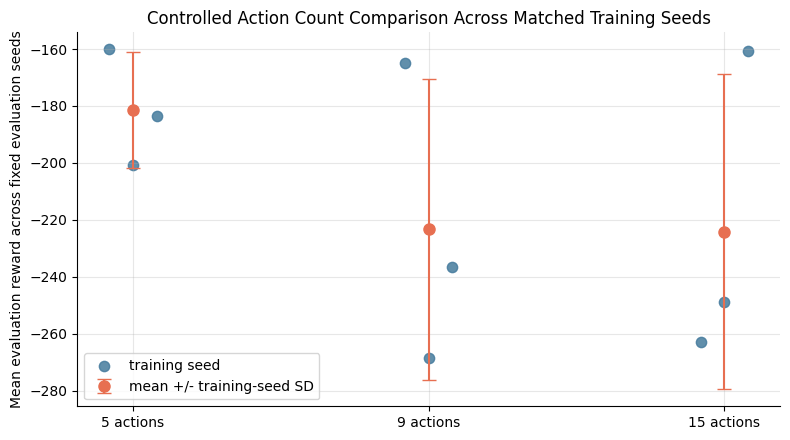

Saved controlled action-count plot to: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_b_outputs\controlled_matched_seed\plots\controlled_action_count_training_seed_reward_plot.png


In [58]:
# Step 14.3: Visualise controlled action-count seed spread
controlled_action_plot_path = CONTROLLED_PLOT_DIR / "controlled_action_count_training_seed_reward_plot.png"
plot_controlled_reward_seed_points(
    per_seed_df=controlled_action_per_seed,
    aggregate_df=controlled_action_aggregate,
    label_column="action_label",
    order_labels=["5 actions", "9 actions", "15 actions"],
    title="Controlled Action Count Comparison Across Matched Training Seeds",
    output_path=controlled_action_plot_path,
)
print("Saved controlled action-count plot to:", controlled_action_plot_path)


### 14.3 Controlled Action-Count Plot Interpretation

This visual shows why the action-count conclusion changed.

The 5-action points sit higher overall than the 9-action and 15-action points, while the finer action sets show wider variation across training seeds. This supports the table result: the simpler action set is not only better on average here, it is also less variable under the matched-seed audit.

Decision: use the visual as evidence that the earlier 15-action result was likely affected by seed-specific training behaviour.


In [59]:
# Step 14.4: Controlled target-network update experiment using the selected action count
target_update_configs = []
for target_update_every in CONTROLLED_TARGET_UPDATE_CANDIDATES:
    target_update_configs.append(make_controlled_config(
        experiment_group="target_update",
        action_count=CONTROLLED_SELECTED_ACTION_COUNT,
        action_values=CONTROLLED_SELECTED_ACTION_VALUES,
        learning_rate=DQN_LEARNING_RATE,
        epsilon_end=EPSILON_END,
        target_update_every=target_update_every,
    ))

controlled_target_scores, controlled_target_per_seed, controlled_target_aggregate, _, controlled_target_run_log = run_controlled_grid(
    configs=target_update_configs,
    experiment_name="controlled_target_update",
    group_columns=["target_update_label", "target_update_every"],
    keep_rollouts=False,
)

controlled_target_selection, controlled_target_ranked = select_best_controlled_setting(
    controlled_target_aggregate,
    label_column="target_update_label",
)
CONTROLLED_SELECTED_TARGET_UPDATE_LABEL = str(controlled_target_selection["selected setting"].iloc[0])
CONTROLLED_SELECTED_TARGET_UPDATE_EVERY = int(CONTROLLED_SELECTED_TARGET_UPDATE_LABEL.split()[1])

controlled_target_selection.to_csv(CONTROLLED_TABLE_DIR / "controlled_target_update_selection.csv", index=False)
controlled_target_ranked.to_csv(CONTROLLED_TABLE_DIR / "controlled_target_update_ranked.csv", index=False)

display(controlled_target_aggregate.round(4))
display(controlled_target_selection)
print("Selected controlled target update interval:", CONTROLLED_SELECTED_TARGET_UPDATE_LABEL)


controlled_target_update | target_update_5act_lr0p001_eps0p05_tu5_h128x128_gdefault | seed 88 | loaded
controlled_target_update | target_update_5act_lr0p001_eps0p05_tu5_h128x128_gdefault | seed 189 | loaded
controlled_target_update | target_update_5act_lr0p001_eps0p05_tu5_h128x128_gdefault | seed 290 | loaded
controlled_target_update | target_update_5act_lr0p001_eps0p05_tu10_h128x128_gdefault | seed 88 | loaded
controlled_target_update | target_update_5act_lr0p001_eps0p05_tu10_h128x128_gdefault | seed 189 | loaded
controlled_target_update | target_update_5act_lr0p001_eps0p05_tu10_h128x128_gdefault | seed 290 | loaded
controlled_target_update | target_update_5act_lr0p001_eps0p05_tu20_h128x128_gdefault | seed 88 | loaded
controlled_target_update | target_update_5act_lr0p001_eps0p05_tu20_h128x128_gdefault | seed 189 | loaded
controlled_target_update | target_update_5act_lr0p001_eps0p05_tu20_h128x128_gdefault | seed 290 | loaded


,target_update_label,target_update_every,training_seed_runs,mean_reward_across_training_seeds,sd_reward_across_training_seeds,worst_seed_mean_reward,best_seed_mean_reward,mean_eval_reward_spread,mean_abs_angle,mean_abs_angular_velocity,mean_abs_torque
0,every 10 episodes,10,3,-181.5132,20.4438,-200.8080,-160.0874,127.2203,0.4184,0.5982,0.7990
1,every 20 episodes,20,3,-1080.3519,38.1205,-1121.4574,-1046.1635,539.1346,2.0260,1.2475,1.5556
2,every 5 episodes,5,3,-137.3172,0.9312,-138.1506,-136.3122,85.7366,0.2635,0.5422,1.0085


,selected setting,mean reward,training-seed sd,gap to second place,decision strength
0,every 5 episodes,-137.32,0.93,44.2,strong within three-seed audit


Selected controlled target update interval: every 5 episodes


### 14.4 Controlled Target-Update Interpretation

This experiment turns the target-network update interval from a conceptual choice into an evidence-based one.

Updating every **5 episodes** gives the strongest result, with mean reward **-137.32** and very low training-seed SD **0.93**. Updating every **10 episodes** drops back to **-181.51**, while updating every **20 episodes** fails badly at **-1080.35**.

This makes sense because the 20-episode target network is probably too stale for this short 100-episode training setup. The online network keeps changing, but the target network waits too long before copying those improvements. Updating every 5 episodes gives the DQN a more responsive target without updating it every single step.

Decision: use **target update every 5 episodes**. This is one of the strongest successful improvements in Part B.


In [60]:
# Step 14.5: Controlled learning-rate and epsilon-end experiments
learning_rate_configs = []
for learning_rate in CONTROLLED_LEARNING_RATE_CANDIDATES:
    learning_rate_configs.append(make_controlled_config(
        experiment_group="learning_rate",
        action_count=CONTROLLED_SELECTED_ACTION_COUNT,
        action_values=CONTROLLED_SELECTED_ACTION_VALUES,
        learning_rate=learning_rate,
        epsilon_end=EPSILON_END,
        target_update_every=CONTROLLED_SELECTED_TARGET_UPDATE_EVERY,
    ))

controlled_lr_scores, controlled_lr_per_seed, controlled_lr_aggregate, _, controlled_lr_run_log = run_controlled_grid(
    configs=learning_rate_configs,
    experiment_name="controlled_learning_rate",
    group_columns=["learning_rate_label", "learning_rate"],
    keep_rollouts=False,
)

controlled_lr_selection, controlled_lr_ranked = select_best_controlled_setting(
    controlled_lr_aggregate,
    label_column="learning_rate_label",
)
CONTROLLED_SELECTED_LEARNING_RATE = float(controlled_lr_selection["selected setting"].iloc[0])

epsilon_configs = []
for epsilon_end in CONTROLLED_EPSILON_END_CANDIDATES:
    epsilon_configs.append(make_controlled_config(
        experiment_group="epsilon_end",
        action_count=CONTROLLED_SELECTED_ACTION_COUNT,
        action_values=CONTROLLED_SELECTED_ACTION_VALUES,
        learning_rate=CONTROLLED_SELECTED_LEARNING_RATE,
        epsilon_end=epsilon_end,
        target_update_every=CONTROLLED_SELECTED_TARGET_UPDATE_EVERY,
    ))

controlled_epsilon_scores, controlled_epsilon_per_seed, controlled_epsilon_aggregate, _, controlled_epsilon_run_log = run_controlled_grid(
    configs=epsilon_configs,
    experiment_name="controlled_epsilon_end",
    group_columns=["epsilon_label", "epsilon_end"],
    keep_rollouts=False,
)

controlled_epsilon_selection, controlled_epsilon_ranked = select_best_controlled_setting(
    controlled_epsilon_aggregate,
    label_column="epsilon_label",
)
CONTROLLED_SELECTED_EPSILON_END = float(controlled_epsilon_selection["selected setting"].iloc[0])

controlled_lr_selection.to_csv(CONTROLLED_TABLE_DIR / "controlled_learning_rate_selection.csv", index=False)
controlled_lr_ranked.to_csv(CONTROLLED_TABLE_DIR / "controlled_learning_rate_ranked.csv", index=False)
controlled_epsilon_selection.to_csv(CONTROLLED_TABLE_DIR / "controlled_epsilon_end_selection.csv", index=False)
controlled_epsilon_ranked.to_csv(CONTROLLED_TABLE_DIR / "controlled_epsilon_end_ranked.csv", index=False)

display(controlled_lr_aggregate.round(4))
display(controlled_lr_selection)
display(controlled_epsilon_aggregate.round(4))
display(controlled_epsilon_selection)
print("Selected controlled learning rate:", CONTROLLED_SELECTED_LEARNING_RATE)
print("Selected controlled epsilon end:", CONTROLLED_SELECTED_EPSILON_END)


controlled_learning_rate | learning_rate_5act_lr0p01_eps0p05_tu5_h128x128_gdefault | seed 88 | loaded
controlled_learning_rate | learning_rate_5act_lr0p01_eps0p05_tu5_h128x128_gdefault | seed 189 | loaded
controlled_learning_rate | learning_rate_5act_lr0p01_eps0p05_tu5_h128x128_gdefault | seed 290 | loaded
controlled_learning_rate | learning_rate_5act_lr0p001_eps0p05_tu5_h128x128_gdefault | seed 88 | loaded
controlled_learning_rate | learning_rate_5act_lr0p001_eps0p05_tu5_h128x128_gdefault | seed 189 | loaded
controlled_learning_rate | learning_rate_5act_lr0p001_eps0p05_tu5_h128x128_gdefault | seed 290 | loaded
controlled_learning_rate | learning_rate_5act_lr0p0005_eps0p05_tu5_h128x128_gdefault | seed 88 | loaded
controlled_learning_rate | learning_rate_5act_lr0p0005_eps0p05_tu5_h128x128_gdefault | seed 189 | loaded
controlled_learning_rate | learning_rate_5act_lr0p0005_eps0p05_tu5_h128x128_gdefault | seed 290 | loaded
controlled_epsilon_end | epsilon_end_5act_lr0p001_eps0p05_tu5_h128x

,learning_rate_label,learning_rate,training_seed_runs,mean_reward_across_training_seeds,sd_reward_across_training_seeds,worst_seed_mean_reward,best_seed_mean_reward,mean_eval_reward_spread,mean_abs_angle,mean_abs_angular_velocity,mean_abs_torque
0,0.0005,0.0005,3,-137.9693,1.3270,-139.4886,-137.0373,85.9455,0.2550,0.5667,1.2508
1,0.001,0.0010,3,-137.3172,0.9312,-138.1506,-136.3122,85.7366,0.2635,0.5422,1.0085
2,0.01,0.0100,3,-142.8157,3.4217,-145.9373,-139.1574,86.5685,0.3584,0.5560,1.2066


,selected setting,mean reward,training-seed sd,gap to second place,decision strength
0,0.001,-137.32,0.93,0.65,modest / seed-sensitive


,epsilon_label,epsilon_end,training_seed_runs,mean_reward_across_training_seeds,sd_reward_across_training_seeds,worst_seed_mean_reward,best_seed_mean_reward,mean_eval_reward_spread,mean_abs_angle,mean_abs_angular_velocity,mean_abs_torque
0,0.01,0.01,3,-139.5728,1.9490,-141.8204,-138.3499,86.1756,0.3083,0.5504,1.1502
1,0.05,0.05,3,-137.3172,0.9312,-138.1506,-136.3122,85.7366,0.2635,0.5422,1.0085


,selected setting,mean reward,training-seed sd,gap to second place,decision strength
0,0.05,-137.32,0.93,2.26,consistent but small


Selected controlled learning rate: 0.001
Selected controlled epsilon end: 0.05


### 14.5 Controlled Learning-Rate and Epsilon Interpretation

This closes two tuning questions in a fairer way.

For learning rate, **0.001** gives the best mean reward (**-137.32**), but the advantage over **0.0005** is only about **0.65** reward points. That is small relative to normal DQN variability, so I should not claim that 0.001 is dramatically better. The safer conclusion is that **0.001 remains the best tested learning rate**, while **0.0005** is a close alternative.

The aggressive **0.01** learning rate is weaker at **-142.82** and has larger training-seed spread, which suggests the Q-value updates are too large for this setup.

For epsilon, **0.05** performs better than **0.01** with mean reward **-137.32** versus **-139.57**. This directly answers the epsilon question: epsilon **0.01** is achievable, but in this audit it did not improve the learned policy. The difference is still small, so I describe 0.05 as consistently preferred in this three-seed audit rather than as a universal rule.

Decision: keep **learning rate 0.001** and **epsilon end 0.05** for the final controlled gravity audit.


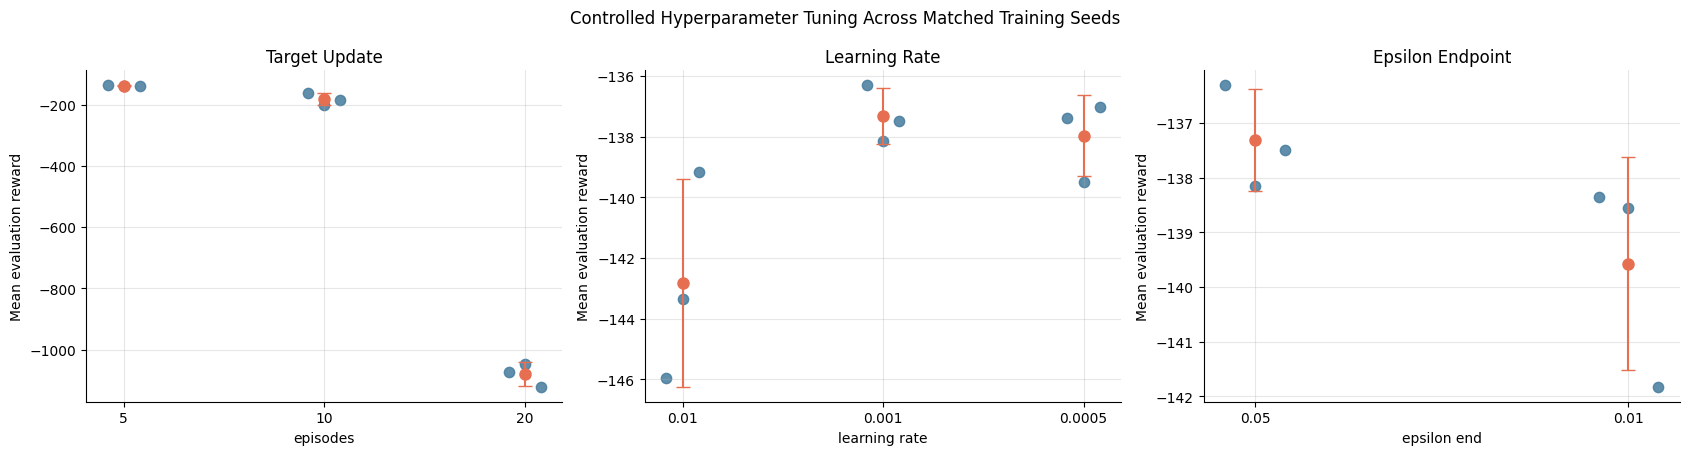

Saved controlled tuning plot to: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_b_outputs\controlled_matched_seed\plots\controlled_target_lr_epsilon_reward_plot.png


In [61]:
# Step 14.6: Visualise controlled target-update, learning-rate and epsilon seed spread
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))

tuning_specs = [
    {
        "axis": axes[0],
        "title": "Target Update",
        "per_seed": controlled_target_per_seed,
        "aggregate": controlled_target_aggregate,
        "label_column": "target_update_label",
        "order": ["every 5 episodes", "every 10 episodes", "every 20 episodes"],
        "tick_labels": ["5", "10", "20"],
        "x_label": "episodes",
    },
    {
        "axis": axes[1],
        "title": "Learning Rate",
        "per_seed": controlled_lr_per_seed,
        "aggregate": controlled_lr_aggregate,
        "label_column": "learning_rate_label",
        "order": [str(value) for value in CONTROLLED_LEARNING_RATE_CANDIDATES],
        "tick_labels": [str(value) for value in CONTROLLED_LEARNING_RATE_CANDIDATES],
        "x_label": "learning rate",
    },
    {
        "axis": axes[2],
        "title": "Epsilon Endpoint",
        "per_seed": controlled_epsilon_per_seed,
        "aggregate": controlled_epsilon_aggregate,
        "label_column": "epsilon_label",
        "order": [str(value) for value in CONTROLLED_EPSILON_END_CANDIDATES],
        "tick_labels": [str(value) for value in CONTROLLED_EPSILON_END_CANDIDATES],
        "x_label": "epsilon end",
    },
]

for spec in tuning_specs:
    ax = spec["axis"]
    for position, label in enumerate(spec["order"]):
        seed_values = spec["per_seed"][
            spec["per_seed"][spec["label_column"]].astype(str) == str(label)
        ]["mean_total_reward"].to_numpy()
        jitter = np.linspace(-0.08, 0.08, len(seed_values)) if len(seed_values) else []
        ax.scatter(
            np.full(len(seed_values), position) + jitter,
            seed_values,
            color="#457b9d",
            s=55,
            alpha=0.85,
        )

        aggregate_row = spec["aggregate"][
            spec["aggregate"][spec["label_column"]].astype(str) == str(label)
        ]
        if not aggregate_row.empty:
            ax.errorbar(
                position,
                float(aggregate_row["mean_reward_across_training_seeds"].iloc[0]),
                yerr=float(aggregate_row["sd_reward_across_training_seeds"].iloc[0]),
                fmt="o",
                color="#e76f51",
                capsize=5,
                markersize=8,
            )

    ax.set_xticks(range(len(spec["order"])))
    ax.set_xticklabels(spec["tick_labels"])
    ax.set_title(spec["title"])
    ax.set_xlabel(spec["x_label"])
    ax.set_ylabel("Mean evaluation reward")

fig.suptitle("Controlled Hyperparameter Tuning Across Matched Training Seeds")
plt.tight_layout()

controlled_tuning_plot_path = CONTROLLED_PLOT_DIR / "controlled_target_lr_epsilon_reward_plot.png"
plt.savefig(controlled_tuning_plot_path, dpi=150)
plt.show()
print("Saved controlled tuning plot to:", controlled_tuning_plot_path)


### 14.6 Controlled Tuning Plot Interpretation

This plot should summarise the tuning story visually, not only through tables.

The target-update result is the strongest pattern: every 5 episodes separates clearly from 10 and especially 20. The learning-rate result is much closer, because 0.001 and 0.0005 are almost tied. The epsilon result favours 0.05, but the gap is still small enough that I should write it cautiously.

Decision: use this visual to separate strong tuning evidence from close tuning evidence. Target update is a strong improvement; learning rate and epsilon are more careful selections within the tested settings.


In [62]:
# Step 14.7: Controlled gravity experiment using the selected audit configuration
gravity_configs = []
for gravity_setup in CONTROLLED_GRAVITY_SETUPS:
    gravity_configs.append(make_controlled_config(
        experiment_group="gravity",
        action_count=CONTROLLED_SELECTED_ACTION_COUNT,
        action_values=CONTROLLED_SELECTED_ACTION_VALUES,
        learning_rate=CONTROLLED_SELECTED_LEARNING_RATE,
        epsilon_end=CONTROLLED_SELECTED_EPSILON_END,
        target_update_every=CONTROLLED_SELECTED_TARGET_UPDATE_EVERY,
        gravity_name=gravity_setup["gravity_name"],
        gravity_value=gravity_setup["gravity_value"],
    ))

controlled_gravity_scores, controlled_gravity_per_seed, controlled_gravity_aggregate, controlled_gravity_rollouts, controlled_gravity_run_log = run_controlled_grid(
    configs=gravity_configs,
    experiment_name="controlled_gravity",
    group_columns=["gravity_name"],
    keep_rollouts=True,
)

controlled_gravity_selection, controlled_gravity_ranked = select_best_controlled_setting(
    controlled_gravity_aggregate,
    label_column="gravity_name",
)
CONTROLLED_SELECTED_GRAVITY_NAME = str(controlled_gravity_selection["selected setting"].iloc[0])

controlled_gravity_selection.to_csv(CONTROLLED_TABLE_DIR / "controlled_gravity_selection.csv", index=False)
controlled_gravity_ranked.to_csv(CONTROLLED_TABLE_DIR / "controlled_gravity_ranked.csv", index=False)

controlled_final_configuration = pd.DataFrame([{
    "selected action count": CONTROLLED_SELECTED_ACTION_COUNT,
    "selected target update": CONTROLLED_SELECTED_TARGET_UPDATE_EVERY,
    "selected learning rate": CONTROLLED_SELECTED_LEARNING_RATE,
    "selected epsilon end": CONTROLLED_SELECTED_EPSILON_END,
    "selected gravity": CONTROLLED_SELECTED_GRAVITY_NAME,
    "training seeds": str(CONTROLLED_TRAINING_SEEDS),
    "evaluation seeds": len(CONTROLLED_EVALUATION_SEEDS),
    "training episodes per run": CONTROLLED_DQN_EPISODES,
}])
controlled_final_configuration_path = CONTROLLED_TABLE_DIR / "controlled_final_configuration.csv"
controlled_final_configuration.to_csv(controlled_final_configuration_path, index=False)

display(controlled_gravity_aggregate.round(4))
display(controlled_gravity_selection)
display(controlled_final_configuration)
print("Saved controlled final configuration to:", controlled_final_configuration_path)


controlled_gravity | gravity_5act_lr0p001_eps0p05_tu5_h128x128_gdefault | seed 88 | loaded
controlled_gravity | gravity_5act_lr0p001_eps0p05_tu5_h128x128_gdefault | seed 189 | loaded
controlled_gravity | gravity_5act_lr0p001_eps0p05_tu5_h128x128_gdefault | seed 290 | loaded
controlled_gravity | gravity_5act_lr0p001_eps0p05_tu5_h128x128_g0p0 | seed 88 | loaded
controlled_gravity | gravity_5act_lr0p001_eps0p05_tu5_h128x128_g0p0 | seed 189 | loaded
controlled_gravity | gravity_5act_lr0p001_eps0p05_tu5_h128x128_g0p0 | seed 290 | loaded
controlled_gravity | gravity_5act_lr0p001_eps0p05_tu5_h128x128_gneg10p0 | seed 88 | loaded
controlled_gravity | gravity_5act_lr0p001_eps0p05_tu5_h128x128_gneg10p0 | seed 189 | loaded
controlled_gravity | gravity_5act_lr0p001_eps0p05_tu5_h128x128_gneg10p0 | seed 290 | loaded
controlled_gravity | gravity_5act_lr0p001_eps0p05_tu5_h128x128_g15p0 | seed 88 | loaded
controlled_gravity | gravity_5act_lr0p001_eps0p05_tu5_h128x128_g15p0 | seed 189 | loaded
controlled

,gravity_name,training_seed_runs,mean_reward_across_training_seeds,sd_reward_across_training_seeds,worst_seed_mean_reward,best_seed_mean_reward,mean_eval_reward_spread,mean_abs_angle,mean_abs_angular_velocity,mean_abs_torque
0,anti-gravity,3,-46.1972,1.5087,-47.8257,-44.8470,48.0360,0.1637,0.3272,0.8597
1,default gravity,3,-137.3172,0.9312,-138.1506,-136.3122,85.7366,0.2635,0.5422,1.0085
2,free-fall,3,-45.8822,3.2114,-48.9629,-42.5545,45.7834,0.1823,0.2658,0.6457
3,supergravity,3,-182.7829,6.4079,-190.1241,-178.3109,113.6595,0.3073,0.7154,1.0806


,selected setting,mean reward,training-seed sd,gap to second place,decision strength
0,free-fall,-45.88,3.21,0.32,modest / seed-sensitive


,selected action count,selected target update,selected learning rate,selected epsilon end,selected gravity,training seeds,evaluation seeds,training episodes per run
0,5,5,0.001,0.05,free-fall,"[88, 189, 290]",20,100


Saved controlled final configuration to: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_b_outputs\controlled_matched_seed\tables\controlled_final_configuration.csv


### 14.7 Controlled Gravity Interpretation

This is the final robustness check for the selected DQN workflow.

The controlled gravity table shows that **free-fall** and **anti-gravity** are almost tied. Free-fall has the best mean reward at **-45.88**, while anti-gravity is very close at **-46.20**. The gap is only about **0.32**, so I should not describe free-fall as a decisive winner.

The behaviour metrics explain the result more carefully. Anti-gravity has a slightly lower mean absolute angle (**0.1637**) than free-fall (**0.1823**), but free-fall has smoother angular velocity and uses less torque on average. This is why I treat free-fall as the best combined result, while still acknowledging anti-gravity as a very close competitor.

Default gravity is weaker at **-137.32**, and supergravity is weaker again at **-182.78**. This supports the limitation that stronger gravitational pull makes the task harder for this discretised DQN workflow.

Decision: select **free-fall** within the tested gravity settings, but write the conclusion as a close selection rather than a globally proven best setting.


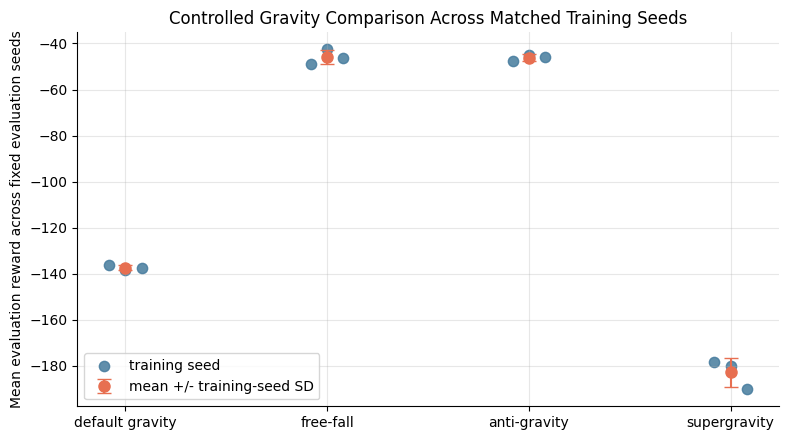

Saved controlled gravity reward plot to: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_b_outputs\controlled_matched_seed\plots\controlled_gravity_training_seed_reward_plot.png


In [63]:
# Step 14.8: Visualise controlled gravity reward across matched training seeds
controlled_gravity_reward_plot_path = CONTROLLED_PLOT_DIR / "controlled_gravity_training_seed_reward_plot.png"
plot_controlled_reward_seed_points(
    per_seed_df=controlled_gravity_per_seed,
    aggregate_df=controlled_gravity_aggregate,
    label_column="gravity_name",
    order_labels=["default gravity", "free-fall", "anti-gravity", "supergravity"],
    title="Controlled Gravity Comparison Across Matched Training Seeds",
    output_path=controlled_gravity_reward_plot_path,
)
print("Saved controlled gravity reward plot to:", controlled_gravity_reward_plot_path)


### 14.8 Controlled Gravity Reward Plot Interpretation

This plot fixes the earlier gravity visual weakness.

The y-error now represents variation across training seeds, not only variation across evaluation episodes. This is better because it shows whether a gravity setting is consistently learnable across independent DQN runs.

The visual should be read cautiously: free-fall and anti-gravity are close, while default gravity and supergravity are clearly lower. The plot therefore supports the broad gravity pattern more strongly than the tiny free-fall versus anti-gravity ranking.

Decision: use the plot to support the final gravity discussion, but avoid overstating the small free-fall advantage.


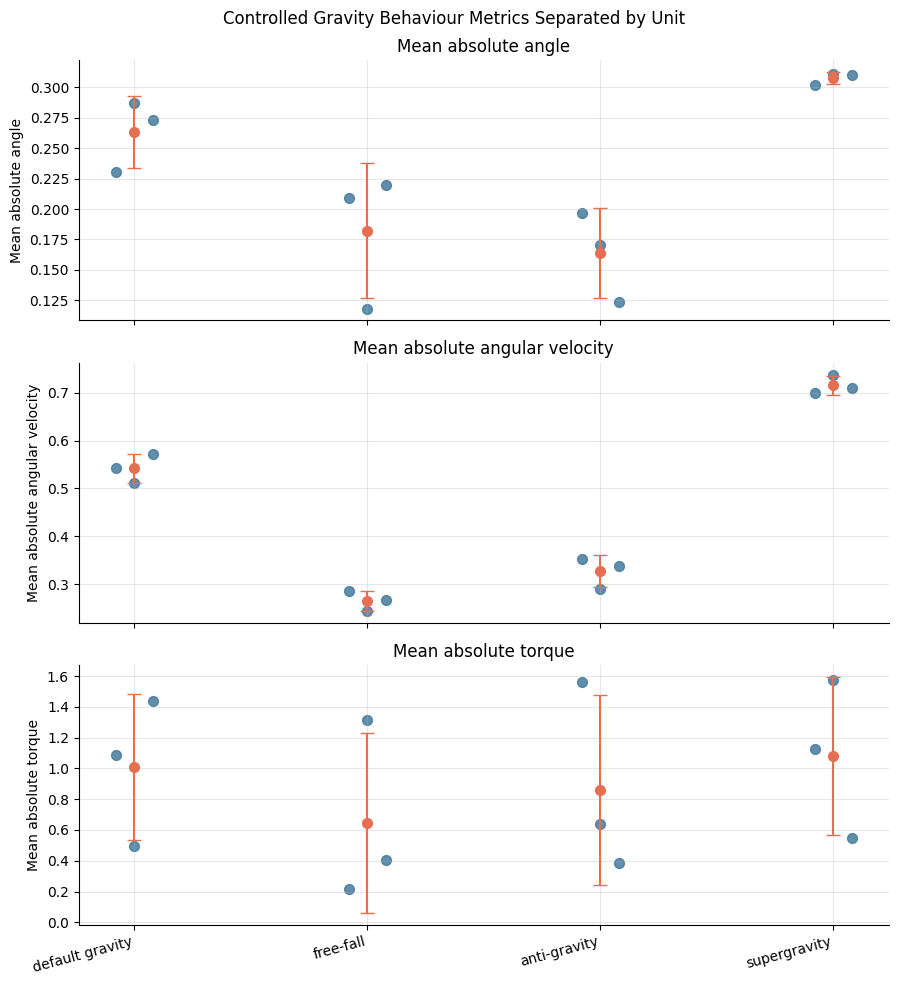

Saved controlled gravity behaviour plot to: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_b_outputs\controlled_matched_seed\plots\controlled_gravity_behaviour_metrics_separate_axes.png


In [64]:
# Step 14.9: Visualise controlled gravity behaviour metrics on separate axes
behaviour_metric_specs = [
    ("mean_abs_angle", "Mean absolute angle"),
    ("mean_abs_angular_velocity", "Mean absolute angular velocity"),
    ("mean_abs_torque", "Mean absolute torque"),
]

gravity_order = ["default gravity", "free-fall", "anti-gravity", "supergravity"]
fig, axes = plt.subplots(3, 1, figsize=(9, 10), sharex=True)

for ax, (metric, label) in zip(axes, behaviour_metric_specs):
    for position, gravity_name in enumerate(gravity_order):
        seed_values = controlled_gravity_per_seed[controlled_gravity_per_seed["gravity_name"] == gravity_name][metric].to_numpy()
        jitter = np.linspace(-0.08, 0.08, len(seed_values)) if len(seed_values) else []
        ax.scatter(np.full(len(seed_values), position) + jitter, seed_values, color="#457b9d", s=50, alpha=0.85)
        aggregate_row = controlled_gravity_aggregate[controlled_gravity_aggregate["gravity_name"] == gravity_name]
        if not aggregate_row.empty:
            mean_value = float(aggregate_row[metric].iloc[0])
            sd_value = float(seed_values.std(ddof=1)) if len(seed_values) > 1 else 0.0
            ax.errorbar(position, mean_value, yerr=sd_value, fmt="o", color="#e76f51", capsize=5, markersize=7)
    ax.set_ylabel(label)
    ax.set_title(label)

axes[-1].set_xticks(range(len(gravity_order)))
axes[-1].set_xticklabels(gravity_order, rotation=15, ha="right")
fig.suptitle("Controlled Gravity Behaviour Metrics Separated by Unit")
plt.tight_layout()
controlled_gravity_behaviour_plot_path = CONTROLLED_PLOT_DIR / "controlled_gravity_behaviour_metrics_separate_axes.png"
plt.savefig(controlled_gravity_behaviour_plot_path, dpi=150)
plt.show()
print("Saved controlled gravity behaviour plot to:", controlled_gravity_behaviour_plot_path)


### 14.9 Controlled Gravity Behaviour Plot Interpretation

This behaviour visual is cleaner than the earlier grouped bar chart because the metrics are separated by unit.

Angle error tells me whether the pendulum stays near upright. Angular velocity tells me whether the motion is smooth or still swinging heavily. Torque tells me how much control effort the policy uses. Looking at them separately prevents one metric from visually dominating another just because it has a different scale.

The result adds nuance to the reward ranking. Anti-gravity is slightly better on angle error, but free-fall uses smoother movement and less torque. Supergravity is weaker across the behaviour evidence, which supports the stress-test limitation.

Decision: use these metrics to explain why the final gravity choice is close, not just to repeat the reward table.


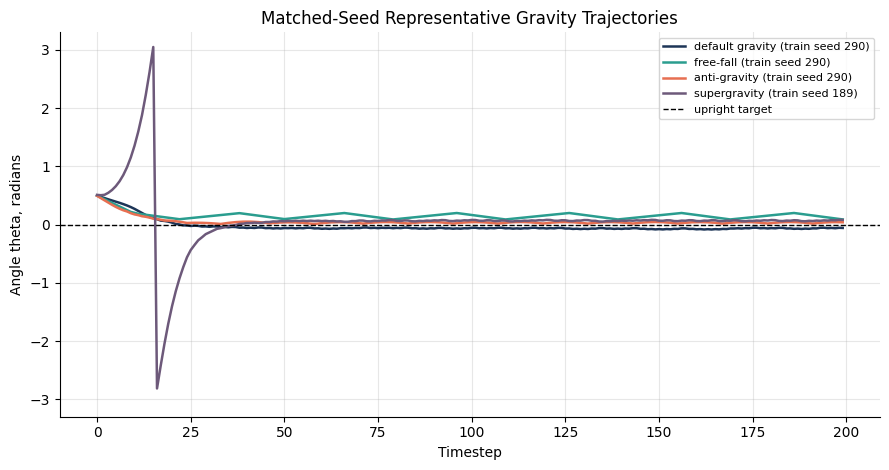

,gravity_name,representative_train_seed,shared_evaluation_seed,seed_mean_reward
0,default gravity,290,6088,-137.49
1,free-fall,290,6088,-46.13
2,anti-gravity,290,6088,-45.92
3,supergravity,189,6088,-179.91


Saved controlled gravity trajectory plot to: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_b_outputs\controlled_matched_seed\plots\controlled_gravity_matched_seed_trajectories.png


In [65]:
# Step 14.10: Plot matched-seed representative trajectories for all gravity settings
if controlled_gravity_rollouts.empty:
    controlled_gravity_rollouts = pd.read_csv(CONTROLLED_TABLE_DIR / "controlled_gravity_rollouts.csv")
if "controlled_gravity_per_seed" not in globals():
    controlled_gravity_per_seed = pd.read_csv(CONTROLLED_TABLE_DIR / "controlled_gravity_per_training_seed_summary.csv")

CONTROLLED_TRAJECTORY_EVALUATION_SEED = CONTROLLED_EVALUATION_SEEDS[0]
controlled_trajectory_rows = []

fig, ax = plt.subplots(figsize=(9, 4.8))
trajectory_colors = {
    "default gravity": "#1d3557",
    "free-fall": "#2a9d8f",
    "anti-gravity": "#e76f51",
    "supergravity": "#6d597a",
}

for gravity_name in ["default gravity", "free-fall", "anti-gravity", "supergravity"]:
    gravity_seed_summary = controlled_gravity_per_seed[controlled_gravity_per_seed["gravity_name"] == gravity_name].copy()
    median_seed_reward = gravity_seed_summary["mean_total_reward"].median()
    representative_seed_row = gravity_seed_summary.iloc[(gravity_seed_summary["mean_total_reward"] - median_seed_reward).abs().argsort().iloc[0]]
    representative_train_seed = int(representative_seed_row["train_seed"])
    rollout = controlled_gravity_rollouts[
        (controlled_gravity_rollouts["gravity_name"] == gravity_name)
        & (controlled_gravity_rollouts["train_seed"] == representative_train_seed)
        & (controlled_gravity_rollouts["evaluation_seed"] == CONTROLLED_TRAJECTORY_EVALUATION_SEED)
    ].copy()
    ax.plot(rollout["step"], rollout["theta"], label=f"{gravity_name} (train seed {representative_train_seed})", color=trajectory_colors[gravity_name], linewidth=1.8)
    controlled_trajectory_rows.append({
        "gravity_name": gravity_name,
        "representative_train_seed": representative_train_seed,
        "shared_evaluation_seed": CONTROLLED_TRAJECTORY_EVALUATION_SEED,
        "seed_mean_reward": round(float(representative_seed_row["mean_total_reward"]), 2),
    })

ax.axhline(0, color="black", linestyle="--", linewidth=1, label="upright target")
ax.set_title("Matched-Seed Representative Gravity Trajectories")
ax.set_xlabel("Timestep")
ax.set_ylabel("Angle theta, radians")
ax.set_ylim(-3.3, 3.3)
ax.legend(loc="upper right", fontsize=8)
plt.tight_layout()
controlled_gravity_trajectory_plot_path = CONTROLLED_PLOT_DIR / "controlled_gravity_matched_seed_trajectories.png"
plt.savefig(controlled_gravity_trajectory_plot_path, dpi=150)
plt.show()

controlled_representative_trajectory_choice = pd.DataFrame(controlled_trajectory_rows)
controlled_representative_trajectory_choice_path = CONTROLLED_TABLE_DIR / "controlled_representative_trajectory_choice.csv"
controlled_representative_trajectory_choice.to_csv(controlled_representative_trajectory_choice_path, index=False)
display(controlled_representative_trajectory_choice)
print("Saved controlled gravity trajectory plot to:", controlled_gravity_trajectory_plot_path)


### 14.10 Controlled Trajectory Interpretation

This trajectory plot fixes the earlier trajectory-control issue.

All four gravity settings are shown, including default gravity. The evaluation seed is also the same for every setting, so differences in the lines are less likely to come from one setting receiving an easier starting state. I still choose a representative training seed for each gravity setting, but I choose it using the median training-seed reward so the plot is not based on the best or worst run.

Decision: use this trajectory as final behaviour evidence together with the reward and metric tables.


In [66]:
# Step 14.11: Compile the controlled audit decision record
controlled_decision_rows = []
for source_name, selection_df in [
    ("action count", controlled_action_selection),
    ("target update interval", controlled_target_selection),
    ("learning rate", controlled_lr_selection),
    ("epsilon endpoint", controlled_epsilon_selection),
    ("gravity setting", controlled_gravity_selection),
]:
    row = selection_df.iloc[0]
    controlled_decision_rows.append({
        "decision area": source_name,
        "selected setting": row["selected setting"],
        "mean reward": row["mean reward"],
        "training-seed sd": row["training-seed sd"],
        "gap to second place": row["gap to second place"],
        "decision strength": row["decision strength"],
    })

controlled_audit_decision_record = pd.DataFrame(controlled_decision_rows)
controlled_audit_decision_record_path = CONTROLLED_TABLE_DIR / "controlled_audit_decision_record.csv"
controlled_audit_decision_record.to_csv(controlled_audit_decision_record_path, index=False)
display(controlled_audit_decision_record)
print("Saved controlled audit decision record to:", controlled_audit_decision_record_path)


,decision area,selected setting,mean reward,training-seed sd,gap to second place,decision strength
0,action count,5 actions,-181.51,20.44,41.80,modest / seed-sensitive
1,target update interval,every 5 episodes,-137.32,0.93,44.20,strong within three-seed audit
2,learning rate,0.001,-137.32,0.93,0.65,modest / seed-sensitive
3,epsilon endpoint,0.05,-137.32,0.93,2.26,consistent but small
4,gravity setting,free-fall,-45.88,3.21,0.32,modest / seed-sensitive


Saved controlled audit decision record to: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_b_outputs\controlled_matched_seed\tables\controlled_audit_decision_record.csv


### 14.11 Controlled Audit Decision Interpretation

This table is the final decision record for the matched-seed audit.

The most important outcome is that the audit corrects my earlier action-count conclusion. I first thought 15 actions was best, but the controlled comparison selects **5 actions** instead. This is not a weakness in the notebook; it is evidence that the workflow is actually checking its own assumptions.

The target-update result is the clearest improvement because **5 episodes** beats 10 and 20 by a meaningful margin. The learning-rate and epsilon choices are more cautious. **0.001** beats **0.0005** only slightly, and **0.05** beats **0.01** by a small gap. The gravity result is also close because free-fall and anti-gravity are almost tied.

Decision: use the controlled decision record as the final model-selection evidence, but describe close decisions as selected within the tested settings rather than proved globally optimal.


### 14.12 Final Action-Count Confirmation

The matched-seed audit selected **5 actions**, but that action-count test was originally run while the target network still updated every **10 episodes**.

After the target-update experiment, the selected interval changed to **5 episodes**. This creates one final question: does 5 actions still remain best after using the improved target-update setting?

This confirmation test compares **5, 9 and 15 actions again**, now with the selected target-update interval, selected learning rate and selected epsilon endpoint. This closes the main sequential-tuning limitation without adding a whole new direction to the project.


final_action_count_confirmation | final_action_confirmation_5act_lr0p001_eps0p05_tu5_h128x128_gdefault | seed 88 | loaded
final_action_count_confirmation | final_action_confirmation_5act_lr0p001_eps0p05_tu5_h128x128_gdefault | seed 189 | loaded
final_action_count_confirmation | final_action_confirmation_5act_lr0p001_eps0p05_tu5_h128x128_gdefault | seed 290 | loaded
final_action_count_confirmation | final_action_confirmation_9act_lr0p001_eps0p05_tu5_h128x128_gdefault | seed 88 | loaded
final_action_count_confirmation | final_action_confirmation_9act_lr0p001_eps0p05_tu5_h128x128_gdefault | seed 189 | loaded
final_action_count_confirmation | final_action_confirmation_9act_lr0p001_eps0p05_tu5_h128x128_gdefault | seed 290 | loaded
final_action_count_confirmation | final_action_confirmation_15act_lr0p001_eps0p05_tu5_h128x128_gdefault | seed 88 | loaded
final_action_count_confirmation | final_action_confirmation_15act_lr0p001_eps0p05_tu5_h128x128_gdefault | seed 189 | loaded
final_action_coun

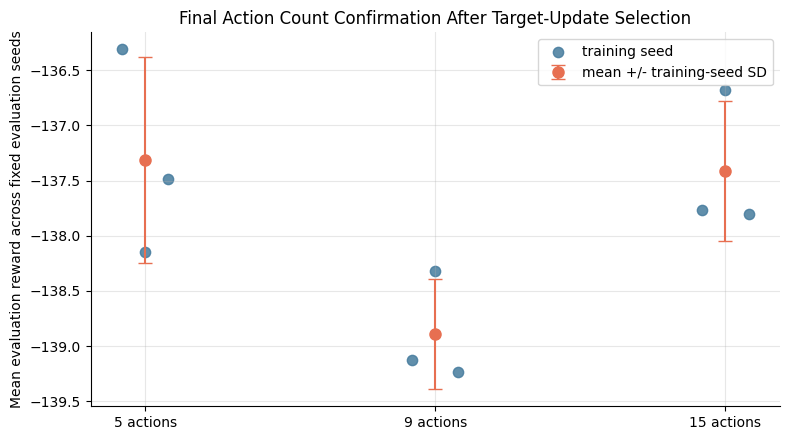

,action_label,action_count,training_seed_runs,mean_reward_across_training_seeds,sd_reward_across_training_seeds,worst_seed_mean_reward,best_seed_mean_reward,mean_eval_reward_spread,mean_abs_angle,mean_abs_angular_velocity,mean_abs_torque
0,15 actions,15,3,-137.4145,0.6377,-137.7988,-136.6784,85.6570,0.2459,0.5542,1.1854
1,5 actions,5,3,-137.3172,0.9312,-138.1506,-136.3122,85.7366,0.2635,0.5422,1.0085
2,9 actions,9,3,-138.8927,0.4979,-139.2350,-138.3215,86.2134,0.3018,0.5262,0.7223


,selected setting,mean reward,training-seed sd,gap to second place,decision strength
0,5 actions,-137.32,0.93,0.1,modest / seed-sensitive


Confirmed action count: 5 actions
Saved final action-count confirmation plot to: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_b_outputs\controlled_matched_seed\plots\final_action_count_confirmation_reward_plot.png


In [67]:
# Step 14.12: Confirm action count after selecting the target-update interval
final_action_confirmation_configs = []
for action_count, action_values in CONTROLLED_ACTION_SETS.items():
    final_action_confirmation_configs.append(make_controlled_config(
        experiment_group="final_action_confirmation",
        action_count=action_count,
        action_values=action_values,
        learning_rate=CONTROLLED_SELECTED_LEARNING_RATE,
        epsilon_end=CONTROLLED_SELECTED_EPSILON_END,
        target_update_every=CONTROLLED_SELECTED_TARGET_UPDATE_EVERY,
    ))

(
    final_action_confirmation_scores,
    final_action_confirmation_per_seed,
    final_action_confirmation_aggregate,
    _,
    final_action_confirmation_run_log,
) = run_controlled_grid(
    configs=final_action_confirmation_configs,
    experiment_name="final_action_count_confirmation",
    group_columns=["action_label", "action_count"],
    keep_rollouts=False,
)

final_action_confirmation_selection, final_action_confirmation_ranked = select_best_controlled_setting(
    final_action_confirmation_aggregate,
    label_column="action_label",
)

CONTROLLED_CONFIRMED_ACTION_LABEL = str(final_action_confirmation_selection["selected setting"].iloc[0])
CONTROLLED_CONFIRMED_ACTION_COUNT = int(CONTROLLED_CONFIRMED_ACTION_LABEL.split()[0])
CONTROLLED_CONFIRMED_ACTION_VALUES = CONTROLLED_ACTION_SETS[CONTROLLED_CONFIRMED_ACTION_COUNT].copy()

final_action_confirmation_selection.to_csv(
    CONTROLLED_TABLE_DIR / "final_action_count_confirmation_selection.csv",
    index=False,
)
final_action_confirmation_ranked.to_csv(
    CONTROLLED_TABLE_DIR / "final_action_count_confirmation_ranked.csv",
    index=False,
)

final_action_confirmation_plot_path = CONTROLLED_PLOT_DIR / "final_action_count_confirmation_reward_plot.png"
plot_controlled_reward_seed_points(
    per_seed_df=final_action_confirmation_per_seed,
    aggregate_df=final_action_confirmation_aggregate,
    label_column="action_label",
    order_labels=["5 actions", "9 actions", "15 actions"],
    title="Final Action Count Confirmation After Target-Update Selection",
    output_path=final_action_confirmation_plot_path,
)

display(final_action_confirmation_aggregate.round(4))
display(final_action_confirmation_selection)
print("Confirmed action count:", CONTROLLED_CONFIRMED_ACTION_LABEL)
print("Saved final action-count confirmation plot to:", final_action_confirmation_plot_path)


### 14.12 Final Action-Count Confirmation Interpretation

This is the final check for the main sequential-tuning issue.

The confirmation keeps **5 actions** as the highest-reward option, but the result is now extremely close. Five actions achieves mean reward **-137.32**, while 15 actions achieves **-137.41**, a gap of only about **0.10** reward points. This gap is smaller than the training-seed variation, so I cannot claim that 5 actions is decisively superior.

The behaviour evidence is also mixed. The 15-action setup has a slightly lower mean absolute angle (**0.2459**) than 5 actions (**0.2635**), while 5 actions uses less torque on average (**1.0085** versus **1.1854**). The 9-action setup is weaker on reward at **-138.89**.

Because reward was defined as the primary selection metric before tuning, I retain **5 actions**. However, the final interpretation is that **5 and 15 actions are practically close under the final target-update setting**, not that 5 actions is globally or decisively better.

Decision: freeze **5 actions** for the final held-out evaluation, while clearly stating that the final confirmation is modest and seed-sensitive.


### 14.13 Held-Out Final Evaluation

Up to this point, the same fixed evaluation seeds were used for selecting hyperparameters. That is acceptable for coursework, but a stronger final check is to freeze the selected configuration and test it once on new evaluation seeds that were not used during tuning.

This held-out evaluation does not choose the model. It only checks whether the final selected configuration still performs sensibly on a fresh set of starting conditions.


In [68]:
# Step 14.13: Evaluate the frozen final configuration on held-out seeds
CONTROLLED_HELDOUT_EVALUATION_EPISODES = 20
CONTROLLED_HELDOUT_EVALUATION_SEEDS = [
    SEED + 9000 + episode
    for episode in range(CONTROLLED_HELDOUT_EVALUATION_EPISODES)
]


def controlled_gravity_value_from_name(gravity_name):
    for setup in CONTROLLED_GRAVITY_SETUPS:
        if setup["gravity_name"] == gravity_name:
            return setup["gravity_value"]
    raise ValueError(f"Unknown gravity setting: {gravity_name}")


CONTROLLED_CONFIRMED_GRAVITY_NAME = CONTROLLED_SELECTED_GRAVITY_NAME
CONTROLLED_CONFIRMED_GRAVITY_VALUE = controlled_gravity_value_from_name(CONTROLLED_CONFIRMED_GRAVITY_NAME)

CONTROLLED_CONFIRMED_FINAL_CONFIG = make_controlled_config(
    experiment_group="gravity",
    action_count=CONTROLLED_CONFIRMED_ACTION_COUNT,
    action_values=CONTROLLED_CONFIRMED_ACTION_VALUES,
    learning_rate=CONTROLLED_SELECTED_LEARNING_RATE,
    epsilon_end=CONTROLLED_SELECTED_EPSILON_END,
    target_update_every=CONTROLLED_SELECTED_TARGET_UPDATE_EVERY,
    gravity_name=CONTROLLED_CONFIRMED_GRAVITY_NAME,
    gravity_value=CONTROLLED_CONFIRMED_GRAVITY_VALUE,
)

heldout_score_frames = []
heldout_run_rows = []

for train_seed in CONTROLLED_TRAINING_SEEDS:
    q_network, history_df, source, paths = train_or_load_controlled_dqn(
        CONTROLLED_CONFIRMED_FINAL_CONFIG,
        train_seed,
    )
    score_df, _ = evaluate_controlled_dqn(
        config=CONTROLLED_CONFIRMED_FINAL_CONFIG,
        q_network=q_network,
        train_seed=train_seed,
        evaluation_seeds=CONTROLLED_HELDOUT_EVALUATION_SEEDS,
        keep_rollouts=False,
    )
    heldout_score_frames.append(score_df)
    heldout_run_rows.append({
        "train_seed": int(train_seed),
        "training_source": source,
        "weights_file": str(paths["weights_path"]),
        "history_file": str(paths["history_path"]),
        "last_10_train_mean_reward": float(history_df["episode_reward"].tail(10).mean()),
    })

controlled_final_heldout_scores = pd.concat(heldout_score_frames, ignore_index=True)
controlled_final_heldout_per_seed, controlled_final_heldout_aggregate = summarise_controlled_scores(
    controlled_final_heldout_scores,
    group_columns=["gravity_name"],
)
controlled_final_heldout_run_log = pd.DataFrame(heldout_run_rows)

controlled_final_heldout_scores.to_csv(
    CONTROLLED_TABLE_DIR / "controlled_final_heldout_episode_scores.csv",
    index=False,
)
controlled_final_heldout_per_seed.to_csv(
    CONTROLLED_TABLE_DIR / "controlled_final_heldout_per_training_seed_summary.csv",
    index=False,
)
controlled_final_heldout_aggregate.to_csv(
    CONTROLLED_TABLE_DIR / "controlled_final_heldout_aggregate_summary.csv",
    index=False,
)
controlled_final_heldout_run_log.to_csv(
    CONTROLLED_TABLE_DIR / "controlled_final_heldout_run_log.csv",
    index=False,
)

controlled_final_confirmed_configuration = pd.DataFrame([{
    "selected action count": CONTROLLED_CONFIRMED_ACTION_COUNT,
    "selected target update": CONTROLLED_SELECTED_TARGET_UPDATE_EVERY,
    "selected learning rate": CONTROLLED_SELECTED_LEARNING_RATE,
    "selected epsilon end": CONTROLLED_SELECTED_EPSILON_END,
    "selected gravity": CONTROLLED_CONFIRMED_GRAVITY_NAME,
    "training seeds": str(CONTROLLED_TRAINING_SEEDS),
    "tuning evaluation seeds": len(CONTROLLED_EVALUATION_SEEDS),
    "held-out evaluation seeds": len(CONTROLLED_HELDOUT_EVALUATION_SEEDS),
    "training episodes per run": CONTROLLED_DQN_EPISODES,
}])
controlled_final_confirmed_configuration_path = CONTROLLED_TABLE_DIR / "controlled_final_confirmed_configuration.csv"
controlled_final_confirmed_configuration.to_csv(
    controlled_final_confirmed_configuration_path,
    index=False,
)

display(controlled_final_heldout_aggregate.round(4))
display(controlled_final_confirmed_configuration)
print("Saved held-out final evaluation to:", CONTROLLED_TABLE_DIR / "controlled_final_heldout_aggregate_summary.csv")


,gravity_name,training_seed_runs,mean_reward_across_training_seeds,sd_reward_across_training_seeds,worst_seed_mean_reward,best_seed_mean_reward,mean_eval_reward_spread,mean_abs_angle,mean_abs_angular_velocity,mean_abs_torque
0,free-fall,3,-33.7415,3.0715,-36.5837,-30.4831,32.1839,0.1608,0.2492,0.6309


,selected action count,selected target update,selected learning rate,selected epsilon end,selected gravity,training seeds,tuning evaluation seeds,held-out evaluation seeds,training episodes per run
0,5,5,0.001,0.05,free-fall,"[88, 189, 290]",20,20,100


Saved held-out final evaluation to: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_b_outputs\controlled_matched_seed\tables\controlled_final_heldout_aggregate_summary.csv


### 14.13 Held-Out Final Evaluation Interpretation

This held-out result is the final guard against overfitting the evaluation story to the tuning seeds.

The frozen final configuration performs strongly on the new held-out seeds, with mean reward **-33.74** across the three independently trained models and training-seed SD **3.07**. The worst training-seed mean is **-36.58**, while the best is **-30.48**, so the three final trained models are reasonably consistent on the held-out start states.

The behaviour metrics also remain strong: mean absolute angle is **0.1608**, mean absolute angular velocity is **0.2492**, and mean absolute torque is **0.6309**. This means the final policy did not collapse when evaluated on starting conditions that were not used for hyperparameter selection.

The held-out reward is closer to zero than the tuning-seed free-fall result, but I interpret this as evidence of successful generalisation to these held-out seeds rather than as another model improvement. No parameters were changed before this test.

Decision: use the held-out table as final validation evidence, not as another tuning step.


### 14.14 Controlled Final GIF and Weight Evidence

The earlier GIF was produced from the provisional workflow, so I now create a new demo from the actual controlled final configuration.

I use a representative training seed instead of the best seed. This keeps the demo honest: it should show typical behaviour from the selected configuration, not only the nicest-looking run.


,gif file,gif path,representative train seed,representative evaluation seed,total reward,mean abs angle,model source,weights file
0,controlled_final_policy_demo.gif,C:\Users\USER\OneDrive - Singapore Polytechnic...,290,9096,-11.63,0.1665,loaded,C:\Users\USER\OneDrive - Singapore Polytechnic...


,train_seed,weights_file,weights_found,weights_path,history_file,history_found,history_path
0,88,gravity_5act_lr0p001_eps0p05_tu5_h128x128_g0p0...,True,C:\Users\USER\OneDrive - Singapore Polytechnic...,gravity_5act_lr0p001_eps0p05_tu5_h128x128_g0p0...,True,C:\Users\USER\OneDrive - Singapore Polytechnic...
1,189,gravity_5act_lr0p001_eps0p05_tu5_h128x128_g0p0...,True,C:\Users\USER\OneDrive - Singapore Polytechnic...,gravity_5act_lr0p001_eps0p05_tu5_h128x128_g0p0...,True,C:\Users\USER\OneDrive - Singapore Polytechnic...
2,290,gravity_5act_lr0p001_eps0p05_tu5_h128x128_g0p0...,True,C:\Users\USER\OneDrive - Singapore Polytechnic...,gravity_5act_lr0p001_eps0p05_tu5_h128x128_g0p0...,True,C:\Users\USER\OneDrive - Singapore Polytechnic...


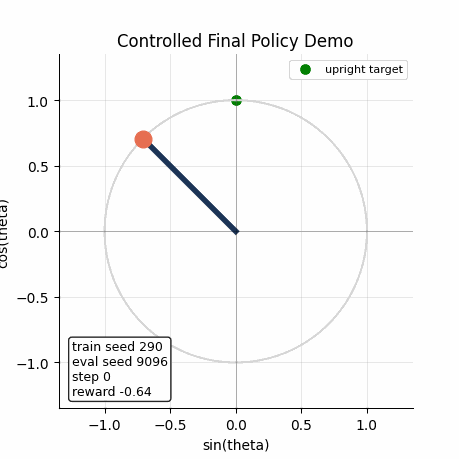

Saved controlled final GIF to: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_b_outputs\controlled_matched_seed\gifs\controlled_final_policy_demo.gif


In [69]:
# Step 14.14: Generate final controlled policy GIF and record final model weights
from IPython.display import Image as IPythonImage
from matplotlib.animation import FuncAnimation, PillowWriter

CONTROLLED_GIF_DIR = CONTROLLED_OUTPUT_DIR / "gifs"
CONTROLLED_GIF_DIR.mkdir(parents=True, exist_ok=True)

median_heldout_reward = controlled_final_heldout_per_seed["mean_total_reward"].median()
representative_seed_row = controlled_final_heldout_per_seed.iloc[
    (controlled_final_heldout_per_seed["mean_total_reward"] - median_heldout_reward).abs().argsort().iloc[0]
]
CONTROLLED_FINAL_REPRESENTATIVE_TRAIN_SEED = int(representative_seed_row["train_seed"])

representative_episode_scores = controlled_final_heldout_scores[
    controlled_final_heldout_scores["train_seed"] == CONTROLLED_FINAL_REPRESENTATIVE_TRAIN_SEED
].copy()
median_episode_reward = representative_episode_scores["total_reward"].median()
representative_episode_row = representative_episode_scores.iloc[
    (representative_episode_scores["total_reward"] - median_episode_reward).abs().argsort().iloc[0]
]
CONTROLLED_FINAL_REPRESENTATIVE_EVALUATION_SEED = int(representative_episode_row["evaluation_seed"])

final_q_network, _, final_source, final_paths = train_or_load_controlled_dqn(
    CONTROLLED_CONFIRMED_FINAL_CONFIG,
    CONTROLLED_FINAL_REPRESENTATIVE_TRAIN_SEED,
)
final_rollout_scores, final_rollout = evaluate_controlled_dqn(
    config=CONTROLLED_CONFIRMED_FINAL_CONFIG,
    q_network=final_q_network,
    train_seed=CONTROLLED_FINAL_REPRESENTATIVE_TRAIN_SEED,
    evaluation_seeds=[CONTROLLED_FINAL_REPRESENTATIVE_EVALUATION_SEED],
    keep_rollouts=True,
)

theta_values = final_rollout["theta"].to_numpy()
reward_values = final_rollout["reward"].to_numpy()
step_values = final_rollout["step"].to_numpy()
frame_indices = list(range(0, len(final_rollout), 2))
if frame_indices[-1] != len(final_rollout) - 1:
    frame_indices.append(len(final_rollout) - 1)

circle_angles = np.linspace(0, 2 * np.pi, 300)
fig, ax = plt.subplots(figsize=(4.6, 4.6))
ax.plot(np.sin(circle_angles), np.cos(circle_angles), color="lightgray", linewidth=1.5)
ax.scatter([0], [1], color="green", s=45, label="upright target")

arm_line, = ax.plot([], [], color="#1d3557", linewidth=4)
bob_point, = ax.plot([], [], marker="o", color="#e76f51", markersize=12)
trace_line, = ax.plot([], [], color="#457b9d", linewidth=1.2, alpha=0.45)
info_text = ax.text(
    -1.25,
    -1.25,
    "",
    fontsize=9,
    bbox={"boxstyle": "round,pad=0.25", "facecolor": "white", "alpha": 0.85},
)

ax.axhline(0, color="black", linewidth=0.8, alpha=0.25)
ax.axvline(0, color="black", linewidth=0.8, alpha=0.25)
ax.set_xlim(-1.35, 1.35)
ax.set_ylim(-1.35, 1.35)
ax.set_aspect("equal")
ax.set_title("Controlled Final Policy Demo")
ax.set_xlabel("sin(theta)")
ax.set_ylabel("cos(theta)")
ax.legend(loc="upper right", fontsize=8)

trace_x = []
trace_y = []


def update_final_demo(frame_position):
    frame = frame_indices[frame_position]
    theta = theta_values[frame]
    x = float(np.sin(theta))
    y = float(np.cos(theta))
    trace_x.append(x)
    trace_y.append(y)
    arm_line.set_data([0, x], [0, y])
    bob_point.set_data([x], [y])
    trace_line.set_data(trace_x, trace_y)
    info_text.set_text(
        f"train seed {CONTROLLED_FINAL_REPRESENTATIVE_TRAIN_SEED}\n"
        f"eval seed {CONTROLLED_FINAL_REPRESENTATIVE_EVALUATION_SEED}\n"
        f"step {int(step_values[frame])}\n"
        f"reward {reward_values[frame]:.2f}"
    )
    return arm_line, bob_point, trace_line, info_text


controlled_final_policy_gif_path = CONTROLLED_GIF_DIR / "controlled_final_policy_demo.gif"
animation = FuncAnimation(
    fig,
    update_final_demo,
    frames=len(frame_indices),
    interval=1000 / 12,
    blit=False,
)
animation.save(str(controlled_final_policy_gif_path), writer=PillowWriter(fps=12))
plt.close(fig)

controlled_final_model_weight_rows = []
for train_seed in CONTROLLED_TRAINING_SEEDS:
    paths = controlled_model_paths(CONTROLLED_CONFIRMED_FINAL_CONFIG, train_seed)
    controlled_final_model_weight_rows.append({
        "train_seed": int(train_seed),
        "weights_file": paths["weights_path"].name,
        "weights_found": paths["weights_path"].exists(),
        "weights_path": str(paths["weights_path"]),
        "history_file": paths["history_path"].name,
        "history_found": paths["history_path"].exists(),
        "history_path": str(paths["history_path"]),
    })

controlled_final_model_weight_evidence = pd.DataFrame(controlled_final_model_weight_rows)
controlled_final_model_weight_evidence_path = CONTROLLED_TABLE_DIR / "controlled_final_model_weight_evidence.csv"
controlled_final_model_weight_evidence.to_csv(
    controlled_final_model_weight_evidence_path,
    index=False,
)

controlled_final_demo_summary = pd.DataFrame([{
    "gif file": controlled_final_policy_gif_path.name,
    "gif path": str(controlled_final_policy_gif_path),
    "representative train seed": CONTROLLED_FINAL_REPRESENTATIVE_TRAIN_SEED,
    "representative evaluation seed": CONTROLLED_FINAL_REPRESENTATIVE_EVALUATION_SEED,
    "total reward": round(float(final_rollout_scores["total_reward"].iloc[0]), 2),
    "mean abs angle": round(float(final_rollout_scores["mean_abs_angle"].iloc[0]), 4),
    "model source": final_source,
    "weights file": str(final_paths["weights_path"]),
}])
controlled_final_demo_summary_path = CONTROLLED_TABLE_DIR / "controlled_final_demo_summary.csv"
controlled_final_demo_summary.to_csv(controlled_final_demo_summary_path, index=False)

display(controlled_final_demo_summary)
display(controlled_final_model_weight_evidence)
display(IPythonImage(filename=str(controlled_final_policy_gif_path)))
print("Saved controlled final GIF to:", controlled_final_policy_gif_path)


### 14.14 Controlled Final GIF and Weight Evidence Interpretation

This is the final demo evidence for the selected controlled model.

The important difference is provenance. The GIF is no longer from the older provisional free-fall model. It is generated from the frozen controlled configuration, and the notebook records the exact training seed, evaluation seed and weight file used to create it.

The weight-evidence table also makes the final model auditable because it lists the saved weight files for all three final training seeds.

Decision: use this GIF and weight table as the final demonstration evidence for Part B.


### 14.15 Upright-Control Rate Diagnostic

Reward is still the main evaluation metric, but I also add one more behavioural diagnostic here.

The reason is that reward tells me the overall penalty, while the earlier angle, angular-velocity and torque metrics tell me separate parts of the behaviour. What I still want to know is simpler: for how much of the evaluation episode is the pendulum actually near upright and moving calmly?

I define an **upright-control step** as a step where:

- `abs(theta) < 15 degrees`
- `abs(theta_dot) < 1`

This is a project-defined diagnostic, not an official Gym success condition. I therefore use upright-control rate only as secondary evidence. Mean evaluation reward remains the primary model-selection metric.


,evidence_scope,action_label,action_count,training_seed_runs,mean_upright_control_rate,sd_upright_control_rate,total_upright_steps,total_steps,mean_abs_angle,mean_abs_angular_velocity,mean_abs_torque,overall_upright_control_rate,gravity_name
0,controlled gravity comparison,NaN,NaN,3,89.46,0.09,10735,12000,0.163728,0.327242,0.859667,89.46,anti-gravity
1,controlled gravity comparison,NaN,NaN,3,86.87,7.47,10424,12000,0.182325,0.265779,0.645750,86.87,free-fall
2,controlled gravity comparison,NaN,NaN,3,85.85,0.25,10302,12000,0.263474,0.542170,1.008500,85.85,default gravity
3,controlled gravity comparison,NaN,NaN,3,84.17,0.37,10100,12000,0.307263,0.715433,1.080583,84.17,supergravity
4,final action-count confirmation,15 actions,15.0,3,86.02,0.44,10322,12000,0.245924,0.554196,1.185405,86.02,NaN
5,final action-count confirmation,5 actions,5.0,3,85.85,0.25,10302,12000,0.263474,0.542170,1.008500,85.85,NaN
6,final action-count confirmation,9 actions,9.0,3,85.54,0.26,10265,12000,0.301805,0.526178,0.722292,85.54,NaN
7,held-out final evaluation,NaN,NaN,3,88.02,7.55,10563,12000,0.160818,0.249191,0.630917,88.02,free-fall


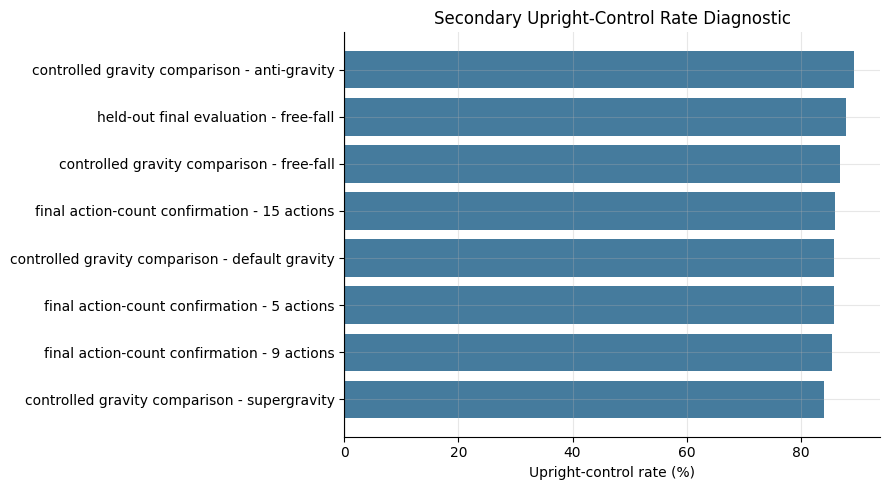

Saved upright-control summaries to: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_b_outputs\controlled_matched_seed\tables\upright_control_rate_aggregate_summary.csv
Saved upright-control plot to: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_b_outputs\controlled_matched_seed\plots\upright_control_rate_comparison.png


In [70]:
# Step 14.15: Calculate upright-control rate as a secondary behavioural diagnostic
UPRIGHT_ANGLE_THRESHOLD_DEGREES = 15
UPRIGHT_ANGLE_THRESHOLD_RADIANS = np.deg2rad(UPRIGHT_ANGLE_THRESHOLD_DEGREES)
UPRIGHT_ANGULAR_VELOCITY_THRESHOLD = 1.0


def add_upright_control_flag(rollout_df):
    checked_rollouts = rollout_df.copy()
    checked_rollouts["upright_control_step"] = (
        checked_rollouts["theta"].abs() < UPRIGHT_ANGLE_THRESHOLD_RADIANS
    ) & (
        checked_rollouts["theta_dot"].abs() < UPRIGHT_ANGULAR_VELOCITY_THRESHOLD
    )
    return checked_rollouts


def summarise_upright_control_rate(rollout_df, group_columns, evidence_scope):
    checked_rollouts = add_upright_control_flag(rollout_df)

    per_seed = checked_rollouts.groupby(
        group_columns + ["train_seed"],
        as_index=False,
        dropna=False,
    ).agg(
        upright_steps=("upright_control_step", "sum"),
        total_steps=("upright_control_step", "size"),
        upright_control_rate=("upright_control_step", "mean"),
        mean_abs_angle=("theta", lambda values: float(np.mean(np.abs(values)))),
        mean_abs_angular_velocity=("theta_dot", lambda values: float(np.mean(np.abs(values)))),
        mean_abs_torque=("torque", lambda values: float(np.mean(np.abs(values)))),
    )
    per_seed.insert(0, "evidence_scope", evidence_scope)

    aggregate = per_seed.groupby(
        ["evidence_scope"] + group_columns,
        as_index=False,
        dropna=False,
    ).agg(
        training_seed_runs=("train_seed", "nunique"),
        mean_upright_control_rate=("upright_control_rate", "mean"),
        sd_upright_control_rate=("upright_control_rate", "std"),
        total_upright_steps=("upright_steps", "sum"),
        total_steps=("total_steps", "sum"),
        mean_abs_angle=("mean_abs_angle", "mean"),
        mean_abs_angular_velocity=("mean_abs_angular_velocity", "mean"),
        mean_abs_torque=("mean_abs_torque", "mean"),
    )
    aggregate["sd_upright_control_rate"] = aggregate["sd_upright_control_rate"].fillna(0.0)
    aggregate["overall_upright_control_rate"] = (
        aggregate["total_upright_steps"] / aggregate["total_steps"]
    )
    return per_seed, aggregate


def load_or_create_final_action_confirmation_rollouts():
    rollout_path = CONTROLLED_TABLE_DIR / "final_action_count_confirmation_rollouts.csv"
    if rollout_path.exists():
        return pd.read_csv(rollout_path)

    print("Creating final action-count confirmation rollouts from saved controlled models...")
    _, _, _, rollout_df, _ = run_controlled_grid(
        configs=final_action_confirmation_configs,
        experiment_name="final_action_count_confirmation",
        group_columns=["action_label", "action_count"],
        keep_rollouts=True,
    )
    return rollout_df


def load_or_create_controlled_final_heldout_rollouts():
    rollout_path = CONTROLLED_TABLE_DIR / "controlled_final_heldout_rollouts.csv"
    if rollout_path.exists():
        return pd.read_csv(rollout_path)

    print("Creating held-out final evaluation rollouts from saved controlled models...")
    heldout_rollout_frames = []
    for train_seed in CONTROLLED_TRAINING_SEEDS:
        q_network, _, _, _ = train_or_load_controlled_dqn(
            CONTROLLED_CONFIRMED_FINAL_CONFIG,
            train_seed,
        )
        _, rollout_df = evaluate_controlled_dqn(
            config=CONTROLLED_CONFIRMED_FINAL_CONFIG,
            q_network=q_network,
            train_seed=train_seed,
            evaluation_seeds=CONTROLLED_HELDOUT_EVALUATION_SEEDS,
            keep_rollouts=True,
        )
        heldout_rollout_frames.append(rollout_df)

    heldout_rollouts = pd.concat(heldout_rollout_frames, ignore_index=True)
    heldout_rollouts.to_csv(rollout_path, index=False)
    return heldout_rollouts


final_action_confirmation_rollouts = load_or_create_final_action_confirmation_rollouts()

if "controlled_gravity_rollouts" not in globals() or controlled_gravity_rollouts.empty:
    controlled_gravity_rollouts = pd.read_csv(CONTROLLED_TABLE_DIR / "controlled_gravity_rollouts.csv")

controlled_final_heldout_rollouts = load_or_create_controlled_final_heldout_rollouts()

upright_per_seed_frames = []
upright_aggregate_frames = []

for rollout_df, group_columns, evidence_scope in [
    (
        final_action_confirmation_rollouts,
        ["action_label", "action_count"],
        "final action-count confirmation",
    ),
    (
        controlled_gravity_rollouts,
        ["gravity_name"],
        "controlled gravity comparison",
    ),
    (
        controlled_final_heldout_rollouts,
        ["gravity_name"],
        "held-out final evaluation",
    ),
]:
    per_seed, aggregate = summarise_upright_control_rate(
        rollout_df=rollout_df,
        group_columns=group_columns,
        evidence_scope=evidence_scope,
    )
    upright_per_seed_frames.append(per_seed)
    upright_aggregate_frames.append(aggregate)

upright_control_per_seed_summary = pd.concat(upright_per_seed_frames, ignore_index=True)
upright_control_aggregate_summary = pd.concat(upright_aggregate_frames, ignore_index=True)

upright_control_per_seed_summary.to_csv(
    CONTROLLED_TABLE_DIR / "upright_control_rate_per_training_seed_summary.csv",
    index=False,
)
upright_control_aggregate_summary.to_csv(
    CONTROLLED_TABLE_DIR / "upright_control_rate_aggregate_summary.csv",
    index=False,
)

upright_display = upright_control_aggregate_summary.copy()
for column in [
    "mean_upright_control_rate",
    "sd_upright_control_rate",
    "overall_upright_control_rate",
]:
    upright_display[column] = (upright_display[column] * 100).round(2)

upright_display = upright_display.sort_values(
    by=["evidence_scope", "mean_upright_control_rate"],
    ascending=[True, False],
).reset_index(drop=True)

display(upright_display)

upright_plot_df = upright_control_aggregate_summary.copy()
upright_plot_df["plot_label"] = upright_plot_df["evidence_scope"]
if "action_label" in upright_plot_df.columns:
    upright_plot_df["plot_label"] = np.where(
        upright_plot_df["action_label"].notna(),
        upright_plot_df["evidence_scope"] + " - " + upright_plot_df["action_label"].astype(str),
        upright_plot_df["plot_label"],
    )
if "gravity_name" in upright_plot_df.columns:
    upright_plot_df["plot_label"] = np.where(
        upright_plot_df["gravity_name"].notna(),
        upright_plot_df["evidence_scope"] + " - " + upright_plot_df["gravity_name"].astype(str),
        upright_plot_df["plot_label"],
    )

upright_plot_df = upright_plot_df.sort_values("overall_upright_control_rate", ascending=True)
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(
    upright_plot_df["plot_label"],
    upright_plot_df["overall_upright_control_rate"] * 100,
    color="#457b9d",
)
ax.set_xlabel("Upright-control rate (%)")
ax.set_title("Secondary Upright-Control Rate Diagnostic")
ax.axvline(0, color="#333333", linewidth=0.8)
plt.tight_layout()
upright_plot_path = CONTROLLED_PLOT_DIR / "upright_control_rate_comparison.png"
plt.savefig(upright_plot_path, dpi=150)
plt.show()

print("Saved upright-control summaries to:", CONTROLLED_TABLE_DIR / "upright_control_rate_aggregate_summary.csv")
print("Saved upright-control plot to:", upright_plot_path)


### 14.15 Upright-Control Rate Interpretation

The upright-control diagnostic gives a more direct view of stability, but it also shows why I should not treat one metric alone as the full answer.

For the final action-count confirmation, **15 actions** has the slightly higher upright-control rate (**86.02%**) compared with **5 actions** (**85.85%**). It also has the lower mean absolute angle (**0.2459** vs **0.2635**). However, 5 actions still has the slightly stronger reward (**-137.32** vs **-137.41**) and lower average torque (**1.0085** vs **1.1854**).

This changes the interpretation from “5 actions is clearly better” to a more careful conclusion: **5 actions is selected by the primary reward metric, but 15 actions is very close and looks slightly stronger on upright-position behaviour**. That is useful because it prevents the final decision from sounding stronger than the evidence actually shows.

For the gravity comparison, anti-gravity has the highest upright-control rate (**89.46%**), while free-fall is lower at **86.87%**. However, free-fall still has the slightly better mean reward and uses less torque and angular velocity on average. This means anti-gravity keeps the pendulum inside my upright threshold more often, but free-fall gives the better overall reward trade-off in the tested setting.

On held-out seeds, the final free-fall policy reaches an upright-control rate of **88.02%**. This supports the final model because the policy still spends most evaluation steps near upright on new starts that were not used for tuning.

Decision: keep reward as the main selection metric, but use upright-control rate to make the final explanation more balanced. The diagnostic supports the final policy behaviour, while also showing that the 5-action and free-fall decisions are close rather than absolute.


### 14.16 Paired Training-Seed Comparisons

The controlled audit already uses the same three training seeds for every candidate. Here I make that design more explicit by comparing candidates seed-by-seed.

This matters because some of the final reward gaps are small. A mean value alone can hide whether every seed favours the same candidate or whether the result depends on one training run. I therefore calculate paired reward differences for the main final decisions.

These paired differences are descriptive evidence of consistency, not a formal significance test. There are only three training seeds, so I use them to explain the direction of the evidence rather than to claim statistical proof.


,comparison,candidate_a,candidate_b,mean_paired_reward_difference,seeds_favouring_candidate_a,seeds_favouring_candidate_b,ties,training_seed_pairs
0,final action count: 5 actions vs 15 actions,5 actions,15 actions,0.0973,2,1,0,3
1,learning rate: 0.001 vs 0.0005,learning rate 0.001,learning rate 0.0005,0.6521,2,1,0,3
2,epsilon endpoint: 0.05 vs 0.01,epsilon end 0.05,epsilon end 0.01,2.2556,3,0,0,3
3,target update: every 5 vs every 10 episodes,target update every 5 episodes,target update every 10 episodes,44.1960,3,0,0,3
4,gravity: free-fall vs anti-gravity,free-fall,anti-gravity,0.3150,1,2,0,3


_candidate_key,comparison,candidate_a,candidate_b,train_seed,candidate_a_mean_reward,candidate_b_mean_reward,paired_reward_difference,favoured_setting
0,final action count: 5 actions vs 15 actions,5 actions,15 actions,88,-136.3122,-137.7663,1.4541,5 actions
1,final action count: 5 actions vs 15 actions,5 actions,15 actions,189,-138.1506,-136.6784,-1.4722,15 actions
2,final action count: 5 actions vs 15 actions,5 actions,15 actions,290,-137.4888,-137.7988,0.3100,5 actions
3,learning rate: 0.001 vs 0.0005,learning rate 0.001,learning rate 0.0005,88,-136.3122,-137.3822,1.0700,learning rate 0.001
4,learning rate: 0.001 vs 0.0005,learning rate 0.001,learning rate 0.0005,189,-138.1506,-139.4886,1.3380,learning rate 0.001
5,learning rate: 0.001 vs 0.0005,learning rate 0.001,learning rate 0.0005,290,-137.4888,-137.0373,-0.4515,learning rate 0.0005
6,epsilon endpoint: 0.05 vs 0.01,epsilon end 0.05,epsilon end 0.01,88,-136.3122,-138.3499,2.0378,epsilon end 0.05
7,epsilon endpoint: 0.05 vs 0.01,epsilon end 0.05,epsilon end 0.01,189,-138.1506,-138.5482,0.3976,epsilon end 0.05
8,epsilon endpoint: 0.05 vs 0.01,epsilon end 0.05,epsilon end 0.01,290,-137.4888,-141.8204,4.3316,epsilon end 0.05
9,target update: every 5 vs every 10 episodes,target update every 5 episodes,target update every 10 episodes,88,-136.3122,-160.0874,23.7753,target update every 5 episodes


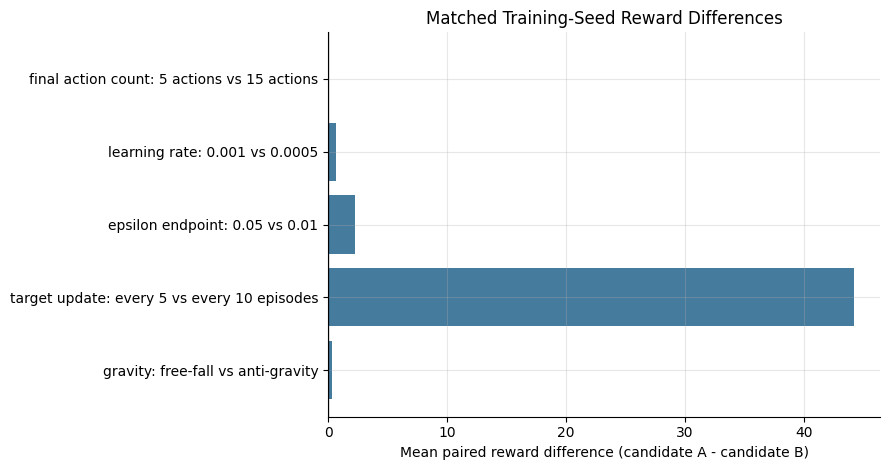

Saved paired seed comparisons to: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_b_outputs\controlled_matched_seed\tables\paired_training_seed_comparison_summary.csv
Saved paired seed plot to: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_b_outputs\controlled_matched_seed\plots\paired_training_seed_reward_difference_plot.png


In [71]:
# Step 14.16: Compare matched candidates seed-by-seed
def read_controlled_per_seed_summary(file_name):
    return pd.read_csv(CONTROLLED_TABLE_DIR / file_name)


def build_paired_reward_comparison(
    per_seed_df,
    label_column,
    candidate_a,
    candidate_b,
    comparison_name,
    candidate_a_label,
    candidate_b_label,
):
    comparison_source = per_seed_df.copy()
    comparison_source["_candidate_key"] = comparison_source[label_column].astype(str)
    candidate_a_key = str(candidate_a)
    candidate_b_key = str(candidate_b)

    pivot = comparison_source[
        comparison_source["_candidate_key"].isin([candidate_a_key, candidate_b_key])
    ].pivot_table(
        index="train_seed",
        columns="_candidate_key",
        values="mean_total_reward",
        aggfunc="mean",
    ).reset_index()

    missing_candidates = [
        label
        for label in [candidate_a_key, candidate_b_key]
        if label not in pivot.columns
    ]
    if missing_candidates:
        raise ValueError(f"Missing candidates for {comparison_name}: {missing_candidates}")

    result = pivot[["train_seed", candidate_a_key, candidate_b_key]].copy()
    result = result.rename(columns={
        candidate_a_key: "candidate_a_mean_reward",
        candidate_b_key: "candidate_b_mean_reward",
    })
    result["paired_reward_difference"] = (
        result["candidate_a_mean_reward"] - result["candidate_b_mean_reward"]
    )
    result["favoured_setting"] = np.where(
        result["paired_reward_difference"] > 0,
        candidate_a_label,
        np.where(
            result["paired_reward_difference"] < 0,
            candidate_b_label,
            "tie",
        ),
    )
    result.insert(0, "comparison", comparison_name)
    result.insert(1, "candidate_a", candidate_a_label)
    result.insert(2, "candidate_b", candidate_b_label)
    return result


paired_comparison_frames = [
    build_paired_reward_comparison(
        read_controlled_per_seed_summary("final_action_count_confirmation_per_training_seed_summary.csv"),
        label_column="action_label",
        candidate_a="5 actions",
        candidate_b="15 actions",
        comparison_name="final action count: 5 actions vs 15 actions",
        candidate_a_label="5 actions",
        candidate_b_label="15 actions",
    ),
    build_paired_reward_comparison(
        read_controlled_per_seed_summary("controlled_learning_rate_per_training_seed_summary.csv"),
        label_column="learning_rate",
        candidate_a=0.001,
        candidate_b=0.0005,
        comparison_name="learning rate: 0.001 vs 0.0005",
        candidate_a_label="learning rate 0.001",
        candidate_b_label="learning rate 0.0005",
    ),
    build_paired_reward_comparison(
        read_controlled_per_seed_summary("controlled_epsilon_end_per_training_seed_summary.csv"),
        label_column="epsilon_end",
        candidate_a=0.05,
        candidate_b=0.01,
        comparison_name="epsilon endpoint: 0.05 vs 0.01",
        candidate_a_label="epsilon end 0.05",
        candidate_b_label="epsilon end 0.01",
    ),
    build_paired_reward_comparison(
        read_controlled_per_seed_summary("controlled_target_update_per_training_seed_summary.csv"),
        label_column="target_update_every",
        candidate_a=5,
        candidate_b=10,
        comparison_name="target update: every 5 vs every 10 episodes",
        candidate_a_label="target update every 5 episodes",
        candidate_b_label="target update every 10 episodes",
    ),
    build_paired_reward_comparison(
        read_controlled_per_seed_summary("controlled_gravity_per_training_seed_summary.csv"),
        label_column="gravity_name",
        candidate_a="free-fall",
        candidate_b="anti-gravity",
        comparison_name="gravity: free-fall vs anti-gravity",
        candidate_a_label="free-fall",
        candidate_b_label="anti-gravity",
    ),
]

paired_training_seed_comparison_details = pd.concat(paired_comparison_frames, ignore_index=True)

paired_summary_rows = []
for comparison_name, group in paired_training_seed_comparison_details.groupby("comparison", sort=False):
    candidate_a = group["candidate_a"].iloc[0]
    candidate_b = group["candidate_b"].iloc[0]
    paired_summary_rows.append({
        "comparison": comparison_name,
        "candidate_a": candidate_a,
        "candidate_b": candidate_b,
        "mean_paired_reward_difference": group["paired_reward_difference"].mean(),
        "seeds_favouring_candidate_a": int((group["favoured_setting"] == candidate_a).sum()),
        "seeds_favouring_candidate_b": int((group["favoured_setting"] == candidate_b).sum()),
        "ties": int((group["favoured_setting"] == "tie").sum()),
        "training_seed_pairs": int(group["train_seed"].nunique()),
    })

paired_training_seed_comparison_summary = pd.DataFrame(paired_summary_rows)

paired_training_seed_comparison_details.to_csv(
    CONTROLLED_TABLE_DIR / "paired_training_seed_comparison_details.csv",
    index=False,
)
paired_training_seed_comparison_summary.to_csv(
    CONTROLLED_TABLE_DIR / "paired_training_seed_comparison_summary.csv",
    index=False,
)

display(paired_training_seed_comparison_summary.round(4))
display(paired_training_seed_comparison_details.round(4))

fig, ax = plt.subplots(figsize=(9, 4.8))
plot_summary = paired_training_seed_comparison_summary.iloc[::-1].copy()
bar_colours = np.where(plot_summary["mean_paired_reward_difference"] >= 0, "#457b9d", "#e76f51")
ax.barh(
    plot_summary["comparison"],
    plot_summary["mean_paired_reward_difference"],
    color=bar_colours,
)
ax.axvline(0, color="#333333", linewidth=0.9)
ax.set_xlabel("Mean paired reward difference (candidate A - candidate B)")
ax.set_title("Matched Training-Seed Reward Differences")
plt.tight_layout()
paired_plot_path = CONTROLLED_PLOT_DIR / "paired_training_seed_reward_difference_plot.png"
plt.savefig(paired_plot_path, dpi=150)
plt.show()

print("Saved paired seed comparisons to:", CONTROLLED_TABLE_DIR / "paired_training_seed_comparison_summary.csv")
print("Saved paired seed plot to:", paired_plot_path)


### 14.16 Paired Training-Seed Comparison Interpretation

The paired seed comparison makes the strength of each decision clearer than the mean table alone.

The final 5-action versus 15-action result is close. Five actions is ahead by only **+0.10** mean paired reward, with two seeds favouring 5 actions and one seed favouring 15 actions. This supports selecting 5 actions because reward was my primary metric, but it also confirms that the final action-count decision is modest rather than decisive.

The target-update result is much stronger. Updating every **5 episodes** beats every 10 episodes by **+44.20** mean paired reward, and all three training seeds favour the 5-episode update. This is the clearest improvement in the controlled audit because both the size and direction of the evidence are consistent.

The learning-rate result remains cautious. `0.001` beats `0.0005` by **+0.65** mean paired reward, but only two of the three seeds favour it. The epsilon result is more consistent: `0.05` beats `0.01` by **+2.26**, and all three seeds favour `0.05`. This means epsilon `0.01` is achievable, but it was not the better endpoint in this audit.

The gravity result is the most nuanced. Free-fall has a slight mean paired advantage over anti-gravity (**+0.32**), but only one of the three seeds favours free-fall. The average result selects free-fall, while the seed-level direction warns me that the difference is not robust.

Decision: keep the selected configuration, but describe the evidence with different confidence levels. Target update is the strongest decision, epsilon is consistent but smaller, and action count, learning rate and gravity should be presented as close controlled choices rather than guaranteed global optima.


### 14.17 Metric Disagreement

The final action-count comparison is a useful place to check whether all metrics agree.

If reward, angle error, angular velocity, torque and upright-control rate all selected the same action count, the interpretation would be straightforward. In my result, they do not fully agree. That does not make the evaluation invalid; it means I need to explain what each metric is measuring before making the final decision.


In [72]:
# Step 14.17: Summarise metric disagreement in the final action-count confirmation
if "final_action_confirmation_aggregate" not in globals():
    final_action_confirmation_aggregate = pd.read_csv(
        CONTROLLED_TABLE_DIR / "final_action_count_confirmation_aggregate_summary.csv"
    )

if "upright_control_aggregate_summary" not in globals():
    upright_control_aggregate_summary = pd.read_csv(
        CONTROLLED_TABLE_DIR / "upright_control_rate_aggregate_summary.csv"
    )

final_action_metric_source = final_action_confirmation_aggregate[
    final_action_confirmation_aggregate["action_label"].isin(["5 actions", "15 actions"])
].set_index("action_label")

upright_action_metric_source = upright_control_aggregate_summary[
    upright_control_aggregate_summary["evidence_scope"] == "final action-count confirmation"
].set_index("action_label")


def prefer_higher(metric_name, value_5, value_15):
    return "5 actions" if value_5 > value_15 else "15 actions"


def prefer_lower(metric_name, value_5, value_15):
    return "5 actions" if value_5 < value_15 else "15 actions"


five_action_upright_rate = float(
    upright_action_metric_source.loc["5 actions", "overall_upright_control_rate"]
) * 100
fifteen_action_upright_rate = float(
    upright_action_metric_source.loc["15 actions", "overall_upright_control_rate"]
) * 100

metric_disagreement_action_count = pd.DataFrame([
    {
        "metric": "mean reward",
        "5 actions": final_action_metric_source.loc["5 actions", "mean_reward_across_training_seeds"],
        "15 actions": final_action_metric_source.loc["15 actions", "mean_reward_across_training_seeds"],
        "preferred by this metric": prefer_higher(
            "mean reward",
            final_action_metric_source.loc["5 actions", "mean_reward_across_training_seeds"],
            final_action_metric_source.loc["15 actions", "mean_reward_across_training_seeds"],
        ),
        "selection rule": "higher is better",
    },
    {
        "metric": "mean absolute angle",
        "5 actions": final_action_metric_source.loc["5 actions", "mean_abs_angle"],
        "15 actions": final_action_metric_source.loc["15 actions", "mean_abs_angle"],
        "preferred by this metric": prefer_lower(
            "mean absolute angle",
            final_action_metric_source.loc["5 actions", "mean_abs_angle"],
            final_action_metric_source.loc["15 actions", "mean_abs_angle"],
        ),
        "selection rule": "lower is better",
    },
    {
        "metric": "mean absolute angular velocity",
        "5 actions": final_action_metric_source.loc["5 actions", "mean_abs_angular_velocity"],
        "15 actions": final_action_metric_source.loc["15 actions", "mean_abs_angular_velocity"],
        "preferred by this metric": prefer_lower(
            "mean absolute angular velocity",
            final_action_metric_source.loc["5 actions", "mean_abs_angular_velocity"],
            final_action_metric_source.loc["15 actions", "mean_abs_angular_velocity"],
        ),
        "selection rule": "lower is better",
    },
    {
        "metric": "mean absolute torque",
        "5 actions": final_action_metric_source.loc["5 actions", "mean_abs_torque"],
        "15 actions": final_action_metric_source.loc["15 actions", "mean_abs_torque"],
        "preferred by this metric": prefer_lower(
            "mean absolute torque",
            final_action_metric_source.loc["5 actions", "mean_abs_torque"],
            final_action_metric_source.loc["15 actions", "mean_abs_torque"],
        ),
        "selection rule": "lower is better",
    },
    {
        "metric": "upright-control rate (%)",
        "5 actions": five_action_upright_rate,
        "15 actions": fifteen_action_upright_rate,
        "preferred by this metric": prefer_higher(
            "upright-control rate",
            five_action_upright_rate,
            fifteen_action_upright_rate,
        ),
        "selection rule": "higher is better",
    },
])

metric_disagreement_action_count.to_csv(
    CONTROLLED_TABLE_DIR / "metric_disagreement_action_count.csv",
    index=False,
)

display(metric_disagreement_action_count.round(4))
print("Saved metric disagreement table to:", CONTROLLED_TABLE_DIR / "metric_disagreement_action_count.csv")


,metric,5 actions,15 actions,preferred by this metric,selection rule
0,mean reward,-137.3172,-137.4145,5 actions,higher is better
1,mean absolute angle,0.2635,0.2459,15 actions,lower is better
2,mean absolute angular velocity,0.5422,0.5542,5 actions,lower is better
3,mean absolute torque,1.0085,1.1854,5 actions,lower is better
4,upright-control rate (%),85.8500,86.0167,15 actions,higher is better


Saved metric disagreement table to: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_b_outputs\controlled_matched_seed\tables\metric_disagreement_action_count.csv


### 14.17 Metric Disagreement Interpretation

The final action-count comparison does not identify one candidate that is best on every metric.

Five actions gives the slightly higher mean reward (**-137.32** vs **-137.41**), lower angular velocity (**0.5422** vs **0.5542**) and lower average torque (**1.0085** vs **1.1854**). Fifteen actions gives the lower mean absolute angle (**0.2459** vs **0.2635**) and the slightly higher upright-control rate (**86.02%** vs **85.85%**).

This is not contradictory because Pendulum reward is not angle alone. The reward function penalises angle, angular velocity and torque together, so a model can sit slightly closer to upright but still receive a slightly weaker total reward if it uses movement or torque less efficiently.

This result improves the workflow because it forces me to separate **selection** from **interpretation**. I select 5 actions because reward was defined as the primary metric before tuning, but I interpret the behaviour more carefully because 15 actions has some better stability indicators.

Decision: keep **5 actions** as the final action count, but describe it as a close evidence-led choice. The stronger conclusion is not “5 actions is better in every way”; it is “5 actions gives the best reward trade-off under my tested settings.”


## 15. Final Evidence Summary

This final section pulls together the saved evidence from the full workflow.

I use it as a final audit before the conclusion. The purpose is to make sure the notebook has the main numerical tables, plots, model weights, matched-seed controlled evidence, final action-count confirmation, held-out evaluation, upright-control diagnostic, paired seed comparison, metric-disagreement check and final controlled GIF demo files saved in one place.


In [73]:
# Step 15.1: Compile the final Part B evidence summary
baseline_evaluation_summary = pd.read_csv(TABLE_DIR / "baseline_dqn_policy_evaluation_summary.csv")
improved_evaluation_summary = pd.read_csv(TABLE_DIR / "improved_dqn_9_action_policy_evaluation_summary.csv")
action_discretisation_comparison = pd.read_csv(TABLE_DIR / "action_discretisation_5_vs_9_vs_15_comparison.csv")
learning_rate_tuning_comparison = pd.read_csv(TABLE_DIR / "default_gravity_learning_rate_tuning_comparison.csv")
learning_rate_tuning_decision = pd.read_csv(TABLE_DIR / "default_gravity_learning_rate_tuning_decision.csv")
gravity_comparison_table = pd.read_csv(TABLE_DIR / "gravity_setting_comparison_summary.csv")
final_gravity_model_selection = pd.read_csv(TABLE_DIR / "final_gravity_model_selection.csv")

random_row = baseline_evaluation_summary[
    baseline_evaluation_summary["policy"] == "random torque"
].iloc[0]
zero_row = baseline_evaluation_summary[
    baseline_evaluation_summary["policy"] == "zero torque"
].iloc[0]
baseline_dqn_row = baseline_evaluation_summary[
    baseline_evaluation_summary["policy"] == "baseline DQN (greedy)"
].iloc[0]
nine_action_row = improved_evaluation_summary.iloc[0]
selected_action_row = action_discretisation_comparison.sort_values("rank").iloc[0]
low_lr_comparison_row = learning_rate_tuning_comparison[
    learning_rate_tuning_comparison["version"].astype(str).str.contains("lower LR")
].iloc[0]
selected_default_decision = learning_rate_tuning_decision.loc[
    learning_rate_tuning_decision["decision area"] == "selected default-gravity DQN",
    "decision",
].iloc[0]
default_gravity_row = gravity_comparison_table[
    gravity_comparison_table["gravity setup"] == "default gravity"
].iloc[0]
final_gravity_row = gravity_comparison_table[
    gravity_comparison_table["gravity setup"] == final_gravity_model_selection.loc[
        final_gravity_model_selection["selection check"] == "selected gravity setup",
        "value",
    ].iloc[0]
].iloc[0]
supergravity_row = gravity_comparison_table[
    gravity_comparison_table["gravity setup"] == "supergravity"
].iloc[0]

final_part_b_rows = [
    {
        "workflow stage": "non-learning reference",
        "model or setting": "random torque, default gravity",
        "mean evaluation reward": round(float(random_row["mean_total_reward"]), 2),
        "mean abs angle": round(float(random_row["mean_abs_angle"]), 4),
        "main evidence": "shows performance before learning",
    },
    {
        "workflow stage": "non-learning reference",
        "model or setting": "zero torque, default gravity",
        "mean evaluation reward": round(float(zero_row["mean_total_reward"]), 2),
        "mean abs angle": round(float(zero_row["mean_abs_angle"]), 4),
        "main evidence": "shows that doing nothing does not stabilise the pendulum",
    },
    {
        "workflow stage": "baseline DQN",
        "model or setting": "5-action DQN, default gravity",
        "mean evaluation reward": round(float(baseline_dqn_row["mean_total_reward"]), 2),
        "mean abs angle": round(float(baseline_dqn_row["mean_abs_angle"]), 4),
        "main evidence": "first learned policy and baseline for improvement",
    },
    {
        "workflow stage": "improvement 1a",
        "model or setting": "9-action DQN, default gravity",
        "mean evaluation reward": round(float(nine_action_row["mean_total_reward"]), 2),
        "mean abs angle": round(float(nine_action_row["mean_abs_angle"]), 4),
        "main evidence": "first finer-action improvement over the 5-action baseline",
    },
    {
        "workflow stage": "exploratory improvement 1b",
        "model or setting": f"{selected_action_row['action set']} selected from 5 vs 9 vs 15",
        "mean evaluation reward": round(float(selected_action_row["mean evaluation reward"]), 2),
        "mean abs angle": round(float(selected_action_row["mean abs angle"]), 4),
        "main evidence": "provisional action-discretisation direction before matched-seed audit",
    },
    {
        "workflow stage": "exploratory improvement 2",
        "model or setting": str(low_lr_comparison_row["version"]),
        "mean evaluation reward": round(float(low_lr_comparison_row["mean evaluation reward"]), 2),
        "mean abs angle": round(float(low_lr_comparison_row["mean abs angle"]), 4),
        "main evidence": "preliminary learning-rate tuning attempt from exploratory workflow",
    },
    {
        "workflow stage": "exploratory selected default setup",
        "model or setting": selected_default_decision,
        "mean evaluation reward": round(float(default_gravity_row["eval mean reward"]), 2),
        "mean abs angle": round(float(default_gravity_row["mean abs angle"]), 4),
        "main evidence": "provisional default-gravity setup before matched-seed audit",
    },
    {
        "workflow stage": "provisional gravity result",
        "model or setting": "provisional selected gravity model",
        "mean evaluation reward": round(float(final_gravity_row["eval mean reward"]), 2),
        "mean abs angle": round(float(final_gravity_row["mean abs angle"]), 4),
        "main evidence": "best repeated-evaluation result across gravity settings",
    },
    {
        "workflow stage": "stress-test evidence",
        "model or setting": "selected DQN workflow under supergravity",
        "mean evaluation reward": round(float(supergravity_row["eval mean reward"]), 2),
        "mean abs angle": round(float(supergravity_row["mean abs angle"]), 4),
        "main evidence": "shows the limitation under stronger gravity",
    },
]

repeated_seed_check_path = TABLE_DIR / "repeated_training_seed_setup_comparison.csv"

if repeated_seed_check_path.exists():
    repeated_seed_setup_comparison = pd.read_csv(repeated_seed_check_path)

    for _, row in repeated_seed_setup_comparison.iterrows():
        final_part_b_rows.append({
            "workflow stage": "extra training-seed check",
            "model or setting": f"{row['gravity setup']} repeated training seeds",
            "mean evaluation reward": round(float(row["extra-seed mean reward"]), 2),
            "mean abs angle": round(float(row["extra-seed mean abs angle"]), 4),
            "main evidence": "checks whether the gravity finding depends on one training run",
        })


controlled_audit_decision_record_path = CONTROLLED_TABLE_DIR / "controlled_audit_decision_record.csv"
controlled_final_configuration_path = CONTROLLED_TABLE_DIR / "controlled_final_configuration.csv"

if controlled_audit_decision_record_path.exists():
    controlled_audit_decision_record = pd.read_csv(controlled_audit_decision_record_path)
    for _, row in controlled_audit_decision_record.iterrows():
        final_part_b_rows.append({
            "workflow stage": f"controlled audit - {row['decision area']}",
            "model or setting": row["selected setting"],
            "mean evaluation reward": round(float(row["mean reward"]), 2),
            "mean abs angle": np.nan,
            "main evidence": f"matched-seed decision strength: {row['decision strength']}",
        })

if controlled_final_configuration_path.exists():
    controlled_final_configuration = pd.read_csv(controlled_final_configuration_path)
    final_part_b_rows.append({
        "workflow stage": "controlled final configuration",
        "model or setting": str(controlled_final_configuration.iloc[0].to_dict()),
        "mean evaluation reward": np.nan,
        "mean abs angle": np.nan,
        "main evidence": "final selected configuration after matched-seed audit",
    })


final_action_count_confirmation_selection_path = CONTROLLED_TABLE_DIR / "final_action_count_confirmation_selection.csv"
controlled_final_heldout_aggregate_path = CONTROLLED_TABLE_DIR / "controlled_final_heldout_aggregate_summary.csv"
controlled_final_confirmed_configuration_path = CONTROLLED_TABLE_DIR / "controlled_final_confirmed_configuration.csv"

if final_action_count_confirmation_selection_path.exists():
    final_action_count_confirmation_selection = pd.read_csv(final_action_count_confirmation_selection_path)
    row = final_action_count_confirmation_selection.iloc[0]
    final_part_b_rows.append({
        "workflow stage": "final action-count confirmation",
        "model or setting": row["selected setting"],
        "mean evaluation reward": round(float(row["mean reward"]), 2),
        "mean abs angle": np.nan,
        "main evidence": f"rechecks action count after target-update selection: {row['decision strength']}",
    })

if controlled_final_heldout_aggregate_path.exists():
    controlled_final_heldout_aggregate = pd.read_csv(controlled_final_heldout_aggregate_path)
    row = controlled_final_heldout_aggregate.iloc[0]
    final_part_b_rows.append({
        "workflow stage": "held-out final evaluation",
        "model or setting": row["gravity_name"],
        "mean evaluation reward": round(float(row["mean_reward_across_training_seeds"]), 2),
        "mean abs angle": round(float(row["mean_abs_angle"]), 4),
        "main evidence": "new evaluation seeds used after hyperparameters were frozen",
    })

if controlled_final_confirmed_configuration_path.exists():
    controlled_final_confirmed_configuration = pd.read_csv(controlled_final_confirmed_configuration_path)
    final_part_b_rows.append({
        "workflow stage": "confirmed final configuration",
        "model or setting": str(controlled_final_confirmed_configuration.iloc[0].to_dict()),
        "mean evaluation reward": np.nan,
        "mean abs angle": np.nan,
        "main evidence": "configuration used for final held-out evaluation and GIF demo",
    })


upright_control_aggregate_path = CONTROLLED_TABLE_DIR / "upright_control_rate_aggregate_summary.csv"
paired_seed_summary_path = CONTROLLED_TABLE_DIR / "paired_training_seed_comparison_summary.csv"
metric_disagreement_path = CONTROLLED_TABLE_DIR / "metric_disagreement_action_count.csv"

if upright_control_aggregate_path.exists():
    upright_control_aggregate_summary = pd.read_csv(upright_control_aggregate_path)
    heldout_upright_rows = upright_control_aggregate_summary[
        upright_control_aggregate_summary["evidence_scope"] == "held-out final evaluation"
    ]
    if not heldout_upright_rows.empty:
        row = heldout_upright_rows.iloc[0]
        final_part_b_rows.append({
            "workflow stage": "upright-control diagnostic",
            "model or setting": row["gravity_name"],
            "mean evaluation reward": np.nan,
            "mean abs angle": round(float(row["mean_abs_angle"]), 4),
            "main evidence": f"secondary upright-control rate: {float(row['overall_upright_control_rate']) * 100:.2f}%",
        })

if paired_seed_summary_path.exists():
    paired_training_seed_comparison_summary = pd.read_csv(paired_seed_summary_path)
    for _, row in paired_training_seed_comparison_summary.iterrows():
        final_part_b_rows.append({
            "workflow stage": "paired training-seed comparison",
            "model or setting": row["comparison"],
            "mean evaluation reward": np.nan,
            "mean abs angle": np.nan,
            "main evidence": (
                f"{row['candidate_a']} - {row['candidate_b']} mean paired reward difference "
                f"{float(row['mean_paired_reward_difference']):.2f}; "
                f"seed split {int(row['seeds_favouring_candidate_a'])}-"
                f"{int(row['seeds_favouring_candidate_b'])}"
            ),
        })

if metric_disagreement_path.exists():
    final_part_b_rows.append({
        "workflow stage": "metric disagreement check",
        "model or setting": "5 actions vs 15 actions",
        "mean evaluation reward": np.nan,
        "mean abs angle": np.nan,
        "main evidence": "reward and behavioural metrics do not fully rank the final action-count candidates the same way",
    })

final_part_b_evidence_summary = pd.DataFrame(final_part_b_rows)

final_part_b_evidence_summary_path = TABLE_DIR / "final_part_b_evidence_summary.csv"
final_part_b_evidence_summary.to_csv(final_part_b_evidence_summary_path, index=False)

display(final_part_b_evidence_summary)
print("Saved final Part B evidence summary to:", final_part_b_evidence_summary_path)


,workflow stage,model or setting,mean evaluation reward,mean abs angle,main evidence
0,non-learning reference,"random torque, default gravity",-1385.27,2.3456,shows performance before learning
1,non-learning reference,"zero torque, default gravity",-1404.10,2.3605,shows that doing nothing does not stabilise th...
2,baseline DQN,"5-action DQN, default gravity",-391.99,0.7925,first learned policy and baseline for improvement
3,improvement 1a,"9-action DQN, default gravity",-295.70,0.6420,first finer-action improvement over the 5-acti...
4,exploratory improvement 1b,15 actions selected from 5 vs 9 vs 15,-293.82,0.5876,closes the action-discretisation investigation...
5,exploratory improvement 2,DQN lower LR (15-action),-338.85,0.7047,preliminary learning-rate tuning attempt from ...
6,exploratory selected default setup,"15-action DQN, standard learning rate",-293.82,0.5876,provisional default-gravity setup before match...
7,provisional gravity result,provisional selected gravity model,-68.11,0.1766,best repeated-evaluation result across gravity...
8,stress-test evidence,selected DQN workflow under supergravity,-454.75,0.7529,shows the limitation under stronger gravity
9,extra training-seed check,free-fall repeated training seeds,-66.46,0.2622,checks whether the gravity finding depends on ...


Saved final Part B evidence summary to: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_b_outputs\tables\final_part_b_evidence_summary.csv


### 15.1 Final Evidence Summary Interpretation

The final evidence summary separates the development workflow from the final controlled evidence.

The earlier sections show how the notebook reached the DQN solution: non-learning baselines, 5-action DQN, 9-action DQN, 15-action follow-up, preliminary learning-rate tuning and provisional gravity comparison. Those sections are useful because they show the reasoning path and the problems found along the way.

The matched-seed audit is the stronger evidence layer. It checks action count, target-network update interval, learning rate, epsilon endpoint and gravity using the same training seeds and the same evaluation seeds. The final confirmation then rechecks action count after the target-update interval has changed, and the held-out evaluation tests the frozen configuration on new seeds.

The extra final diagnostics make the conclusion more careful. Upright-control rate shows that the final policy spends **88.02%** of held-out evaluation steps near upright, but it also reveals that 15 actions and anti-gravity have slightly stronger upright-rate behaviour in some comparisons. The paired seed comparison then explains which decisions are consistent across seeds and which are close.

Decision: use the saved evidence summary as the compact final record, but base the final conclusion mainly on the controlled audit, final confirmation, held-out evaluation, upright-control diagnostic and paired-seed checks.


In [75]:
# Step 15.2: Check final saved evidence files
if "final_gravity_model_selection" not in globals():
    final_gravity_model_selection = pd.read_csv(TABLE_DIR / "final_gravity_model_selection.csv")

selected_gravity_weights_path = Path(
    final_gravity_model_selection.loc[
        final_gravity_model_selection["selection check"] == "selected weights file",
        "value",
    ].iloc[0]
)

gif_dir = OUTPUT_DIR / "gifs"

final_evidence_files = [
    {
        "evidence type": "table",
        "file": "final_part_b_evidence_summary.csv",
        "path": TABLE_DIR / "final_part_b_evidence_summary.csv",
    },
    {
        "evidence type": "table",
        "file": "action_discretisation_5_vs_9_vs_15_comparison.csv",
        "path": TABLE_DIR / "action_discretisation_5_vs_9_vs_15_comparison.csv",
    },
    {
        "evidence type": "table",
        "file": "action_discretisation_selected_default_setup.csv",
        "path": TABLE_DIR / "action_discretisation_selected_default_setup.csv",
    },
    {
        "evidence type": "table",
        "file": "default_gravity_learning_rate_tuning_comparison.csv",
        "path": TABLE_DIR / "default_gravity_learning_rate_tuning_comparison.csv",
    },
    {
        "evidence type": "table",
        "file": "default_gravity_learning_rate_tuning_decision.csv",
        "path": TABLE_DIR / "default_gravity_learning_rate_tuning_decision.csv",
    },
    {
        "evidence type": "table",
        "file": "gravity_setting_comparison_summary.csv",
        "path": TABLE_DIR / "gravity_setting_comparison_summary.csv",
    },
    {
        "evidence type": "table",
        "file": "repeated_training_seed_check_summary.csv",
        "path": TABLE_DIR / "repeated_training_seed_check_summary.csv",
    },
    {
        "evidence type": "table",
        "file": "repeated_training_seed_setup_comparison.csv",
        "path": TABLE_DIR / "repeated_training_seed_setup_comparison.csv",
    },
    {
        "evidence type": "table",
        "file": "final_gravity_model_selection.csv",
        "path": TABLE_DIR / "final_gravity_model_selection.csv",
    },
    {
        "evidence type": "plot",
        "file": "gravity_setting_evaluation_reward_comparison.png",
        "path": PLOT_DIR / "gravity_setting_evaluation_reward_comparison.png",
    },
    {
        "evidence type": "plot",
        "file": "gravity_setting_behaviour_metrics_comparison.png",
        "path": PLOT_DIR / "gravity_setting_behaviour_metrics_comparison.png",
    },
    {
        "evidence type": "plot",
        "file": "gravity_setting_representative_angle_trajectories.png",
        "path": PLOT_DIR / "gravity_setting_representative_angle_trajectories.png",
    },
    {
        "evidence type": "gif",
        "file": "final_free_fall_policy_demo.gif",
        "path": gif_dir / "final_free_fall_policy_demo.gif",
    },
    {
        "evidence type": "gif",
        "file": "supergravity_stress_test_policy_demo.gif",
        "path": gif_dir / "supergravity_stress_test_policy_demo.gif",
    },
    {
        "evidence type": "weights",
        "file": "improved_dqn_9_actions.weights.h5",
        "path": MODEL_DIR / "improved_dqn_9_actions.weights.h5",
    },
    {
        "evidence type": "weights",
        "file": "dqn_15_actions_standard_lr.weights.h5",
        "path": MODEL_DIR / "dqn_15_actions_standard_lr.weights.h5",
    },
    {
        "evidence type": "weights",
        "file": LOW_LR_DQN_WEIGHTS_PATH.name,
        "path": LOW_LR_DQN_WEIGHTS_PATH,
    },
    {
        "evidence type": "weights",
        "file": selected_gravity_weights_path.name,
        "path": selected_gravity_weights_path,
    },
]


controlled_evidence_files = [
    ("table", "controlled_experiment_settings.csv", CONTROLLED_TABLE_DIR / "controlled_experiment_settings.csv"),
    ("table", "controlled_action_count_aggregate_summary.csv", CONTROLLED_TABLE_DIR / "controlled_action_count_aggregate_summary.csv"),
    ("table", "controlled_target_update_aggregate_summary.csv", CONTROLLED_TABLE_DIR / "controlled_target_update_aggregate_summary.csv"),
    ("table", "controlled_learning_rate_aggregate_summary.csv", CONTROLLED_TABLE_DIR / "controlled_learning_rate_aggregate_summary.csv"),
    ("table", "controlled_epsilon_end_aggregate_summary.csv", CONTROLLED_TABLE_DIR / "controlled_epsilon_end_aggregate_summary.csv"),
    ("table", "controlled_gravity_aggregate_summary.csv", CONTROLLED_TABLE_DIR / "controlled_gravity_aggregate_summary.csv"),
    ("table", "controlled_audit_decision_record.csv", CONTROLLED_TABLE_DIR / "controlled_audit_decision_record.csv"),
    ("table", "controlled_final_configuration.csv", CONTROLLED_TABLE_DIR / "controlled_final_configuration.csv"),
    ("plot", "controlled_action_count_training_seed_reward_plot.png", CONTROLLED_PLOT_DIR / "controlled_action_count_training_seed_reward_plot.png"),
    ("plot", "controlled_target_lr_epsilon_reward_plot.png", CONTROLLED_PLOT_DIR / "controlled_target_lr_epsilon_reward_plot.png"),
    ("plot", "controlled_gravity_training_seed_reward_plot.png", CONTROLLED_PLOT_DIR / "controlled_gravity_training_seed_reward_plot.png"),
    ("plot", "controlled_gravity_behaviour_metrics_separate_axes.png", CONTROLLED_PLOT_DIR / "controlled_gravity_behaviour_metrics_separate_axes.png"),
    ("plot", "controlled_gravity_matched_seed_trajectories.png", CONTROLLED_PLOT_DIR / "controlled_gravity_matched_seed_trajectories.png"),
]

for evidence_type, file_name, file_path in controlled_evidence_files:
    final_evidence_files.append({
        "evidence type": evidence_type,
        "file": file_name,
        "path": file_path,
    })

for setup in ["free-fall", "anti-gravity", "supergravity"]:
    for training_seed in REPEATED_TRAINING_SEEDS:
        paths = repeated_seed_model_paths(setup, training_seed)
        final_evidence_files.append({
            "evidence type": "weights",
            "file": paths["weights_path"].name,
            "path": paths["weights_path"],
        })


final_controlled_evidence_files = [
    ("table", "final_action_count_confirmation_aggregate_summary.csv", CONTROLLED_TABLE_DIR / "final_action_count_confirmation_aggregate_summary.csv"),
    ("table", "final_action_count_confirmation_selection.csv", CONTROLLED_TABLE_DIR / "final_action_count_confirmation_selection.csv"),
    ("table", "controlled_final_heldout_aggregate_summary.csv", CONTROLLED_TABLE_DIR / "controlled_final_heldout_aggregate_summary.csv"),
    ("table", "controlled_final_confirmed_configuration.csv", CONTROLLED_TABLE_DIR / "controlled_final_confirmed_configuration.csv"),
    ("table", "controlled_final_demo_summary.csv", CONTROLLED_TABLE_DIR / "controlled_final_demo_summary.csv"),
    ("table", "controlled_final_model_weight_evidence.csv", CONTROLLED_TABLE_DIR / "controlled_final_model_weight_evidence.csv"),
    ("table", "final_action_count_confirmation_rollouts.csv", CONTROLLED_TABLE_DIR / "final_action_count_confirmation_rollouts.csv"),
    ("table", "controlled_final_heldout_rollouts.csv", CONTROLLED_TABLE_DIR / "controlled_final_heldout_rollouts.csv"),
    ("table", "upright_control_rate_per_training_seed_summary.csv", CONTROLLED_TABLE_DIR / "upright_control_rate_per_training_seed_summary.csv"),
    ("table", "upright_control_rate_aggregate_summary.csv", CONTROLLED_TABLE_DIR / "upright_control_rate_aggregate_summary.csv"),
    ("table", "paired_training_seed_comparison_details.csv", CONTROLLED_TABLE_DIR / "paired_training_seed_comparison_details.csv"),
    ("table", "paired_training_seed_comparison_summary.csv", CONTROLLED_TABLE_DIR / "paired_training_seed_comparison_summary.csv"),
    ("table", "metric_disagreement_action_count.csv", CONTROLLED_TABLE_DIR / "metric_disagreement_action_count.csv"),
    ("plot", "controlled_target_lr_epsilon_reward_plot.png", CONTROLLED_PLOT_DIR / "controlled_target_lr_epsilon_reward_plot.png"),
    ("plot", "final_action_count_confirmation_reward_plot.png", CONTROLLED_PLOT_DIR / "final_action_count_confirmation_reward_plot.png"),
    ("plot", "upright_control_rate_comparison.png", CONTROLLED_PLOT_DIR / "upright_control_rate_comparison.png"),
    ("plot", "paired_training_seed_reward_difference_plot.png", CONTROLLED_PLOT_DIR / "paired_training_seed_reward_difference_plot.png"),
    ("gif", "controlled_final_policy_demo.gif", CONTROLLED_OUTPUT_DIR / "gifs" / "controlled_final_policy_demo.gif"),
]

for evidence_type, file_name, file_path in final_controlled_evidence_files:
    final_evidence_files.append({
        "evidence type": evidence_type,
        "file": file_name,
        "path": file_path,
    })

if "CONTROLLED_CONFIRMED_FINAL_CONFIG" in globals():
    for train_seed in CONTROLLED_TRAINING_SEEDS:
        paths = controlled_model_paths(CONTROLLED_CONFIRMED_FINAL_CONFIG, train_seed)
        final_evidence_files.append({
            "evidence type": "weights",
            "file": paths["weights_path"].name,
            "path": paths["weights_path"],
        })

saved_evidence_rows = []

for evidence_file in final_evidence_files:
    file_path = evidence_file["path"]
    saved_evidence_rows.append({
        "evidence type": evidence_file["evidence type"],
        "file": evidence_file["file"],
        "found": file_path.exists(),
        "size KB": round(file_path.stat().st_size / 1024, 2) if file_path.exists() else 0,
        "path": str(file_path),
    })

final_saved_evidence_checklist = pd.DataFrame(saved_evidence_rows)
final_saved_evidence_checklist_path = TABLE_DIR / "final_saved_evidence_checklist.csv"
final_saved_evidence_checklist.to_csv(final_saved_evidence_checklist_path, index=False)

display(final_saved_evidence_checklist)

if final_saved_evidence_checklist["found"].all():
    print("All key final evidence files were found.")
else:
    missing_files = final_saved_evidence_checklist.loc[
        ~final_saved_evidence_checklist["found"],
        "file",
    ].tolist()
    print("Missing evidence files:", missing_files)

print("Saved final evidence checklist to:", final_saved_evidence_checklist_path)


,evidence type,file,found,size KB,path
0,table,final_part_b_evidence_summary.csv,True,4.12,C:\Users\USER\OneDrive - Singapore Polytechnic...
1,table,action_discretisation_5_vs_9_vs_15_comparison.csv,True,2.27,C:\Users\USER\OneDrive - Singapore Polytechnic...
2,table,action_discretisation_selected_default_setup.csv,True,0.40,C:\Users\USER\OneDrive - Singapore Polytechnic...
3,table,default_gravity_learning_rate_tuning_compariso...,True,0.50,C:\Users\USER\OneDrive - Singapore Polytechnic...
4,table,default_gravity_learning_rate_tuning_decision.csv,True,0.50,C:\Users\USER\OneDrive - Singapore Polytechnic...
5,table,gravity_setting_comparison_summary.csv,True,0.60,C:\Users\USER\OneDrive - Singapore Polytechnic...
6,table,repeated_training_seed_check_summary.csv,True,1.52,C:\Users\USER\OneDrive - Singapore Polytechnic...
7,table,repeated_training_seed_setup_comparison.csv,True,0.29,C:\Users\USER\OneDrive - Singapore Polytechnic...
8,table,final_gravity_model_selection.csv,True,1.01,C:\Users\USER\OneDrive - Singapore Polytechnic...
9,plot,gravity_setting_evaluation_reward_comparison.png,True,57.83,C:\Users\USER\OneDrive - Singapore Polytechnic...


All key final evidence files were found.
Saved final evidence checklist to: C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA2\part_b_outputs\tables\final_saved_evidence_checklist.csv


### 15.2 Limitations and Improvements

The saved-evidence checklist confirms that all **58** key evidence files were created, including the final tables, plots, GIF, controlled-model weights, rollout files and new diagnostic summaries.

The main improvement made in the final audit is control of randomness. Earlier comparisons were useful for building the workflow, but the matched-seed section gives a fairer basis for final decisions because every candidate uses the same training seeds and evaluation seeds.

The most important reasoning change is that the controlled audit overturned the earlier action-count conclusion. The one-run workflow suggested 15 actions, but the matched-seed audit selected 5 actions. This improves the notebook because it shows that I changed the decision when better evidence contradicted the first impression.

The final action-count confirmation reduces the sequential-tuning weakness, but it also makes the final interpretation more cautious. Under the selected target-update setting, 5 actions and 15 actions are almost tied on reward, with a gap of only about **0.10**. The new upright-control rate also slightly favours 15 actions, so I describe 5 actions as the best reward trade-off rather than as a model that wins every metric.

The paired seed comparison improves this interpretation because it shows whether the mean result is consistent across the three training runs. It is descriptive evidence, not a formal significance test, but it helps separate strong decisions such as the target-update choice from close decisions such as action count and gravity.

The held-out evaluation is important because the final configuration is tested on new evaluation seeds after tuning has finished. The held-out mean reward of **-33.74**, mean absolute angle of **0.1608** and upright-control rate of **88.02%** suggest that the final policy generalises well to those new starts, but I do not treat the held-out result as another tuning improvement.

The main technical limitation remains that this is a discretised DQN solution. It does not learn continuous torque directly. A stronger future extension would compare the final DQN against a continuous-action RL method using the same held-out evaluation seeds.

Decision: conclude with the selected controlled configuration, the successful and failed improvements, the close final confirmation, paired-seed evidence, upright-control diagnostic, held-out validation and remaining limitations clearly separated.


## 16. Final Conclusion

This Part B notebook built and evaluated a DQN workflow for the Pendulum control task.

The environment check showed the main modelling issue: Pendulum uses a continuous torque action space from **-2.0 to 2.0**, while standard DQN chooses from fixed discrete actions. I therefore converted the torque range into action sets and treated action discretisation as a modelling decision rather than a minor coding detail.

The non-learning baselines showed why a learned policy was needed. Random torque and zero torque did not stabilise the pendulum, so the first target was not perfect reward 0, but a clear movement toward rewards closer to 0 with lower angle error.

The first workflow showed that DQN could learn useful control, and it initially made the finer 15-action setup look attractive. However, that comparison used different training seeds. The matched-seed audit corrected this: **5 actions** performed best among the tested action counts, with mean reward **-181.51** compared with **-223.31** for 9 actions and **-224.18** for 15 actions. This changed my final action-count decision.

The clearest tuning improvement was the target-network update interval. Updating every **5 episodes** achieved mean reward **-137.32**, while every 10 episodes was weaker and every 20 episodes failed badly. The paired seed comparison also supports this strongly, because all three training seeds favoured the 5-episode update and the mean paired reward gap was **+44.20**.

The learning-rate and epsilon results were smaller. Learning rate **0.001** beat **0.0005** by only **+0.65** mean paired reward, with two out of three seeds favouring it. Epsilon end **0.05** beat **0.01** by **+2.26**, with all three seeds favouring 0.05. This directly answers the 0.01 question: it is achievable, but it was not the better endpoint in this audit.

The final action-count confirmation keeps **5 actions** as the selected action count, but only narrowly. Five actions achieves **-137.32**, while 15 actions achieves **-137.41**, so the final reward gap is only about **0.10**. The upright-control diagnostic adds nuance because 15 actions has a slightly higher upright-control rate (**86.02%** vs **85.85%**) and lower angle error, while 5 actions has better reward and lower torque.

The controlled gravity comparison selected **free-fall**, but only narrowly over anti-gravity. Free-fall achieved mean reward **-45.88**, while anti-gravity achieved **-46.20**. Anti-gravity had the higher upright-control rate (**89.46%** vs **86.87%**), so I describe free-fall as the better reward trade-off within this audit rather than a gravity setting that wins every behavioural metric.

Final controlled configuration: **5 actions**, **target update every 5 episodes**, **learning rate 0.001**, **epsilon end 0.05**, and **free-fall gravity**. On held-out evaluation seeds, this frozen configuration achieved mean reward **-33.74**, training-seed SD **3.07**, mean absolute angle **0.1608** and upright-control rate **88.02%**. This supports the final choice because the policy still performs strongly on starts that were not used for hyperparameter selection.

The main limitation is that this is still a discretised DQN solution for a naturally continuous-action environment. The workflow is systematic and controlled, but it does not remove the approximation introduced by discretising torque. A stronger future extension would compare the final DQN against a continuous-action RL method using the same held-out evaluation seeds.
